In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path(r"F:\yingxiang2")

FEATURE_PATH = PROJECT_ROOT / "data" / "processed" / "radiomics_features.csv"
LABEL_PATH = PROJECT_ROOT / "final_patients_egfr.csv"

features_df = pd.read_csv(FEATURE_PATH)
labels_df = pd.read_csv(LABEL_PATH)

print("Features:", features_df.shape)
print("Labels:", labels_df.shape)

display(features_df.head())
display(labels_df.head())

Features: (97, 108)
Labels: (97, 2)


,Case ID,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,...,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,R01-003,0.720221,0.657195,11.036269,16.792985,15.264338,20.396078,20.248457,21.908902,1436.000000,...,0.015595,0.001915,0.381474,399.314034,0.001424,0.094470,0.004453,3667.838634,0.214884,5.187657
1,R01-005,0.785596,0.671483,18.349358,27.326629,30.413813,28.442925,32.557641,34.234486,7093.583333,...,0.039476,0.001121,0.196453,180.248868,0.000467,0.495823,0.000862,1688.359596,0.052741,1.630667
2,R01-006,0.827038,0.611589,14.872624,24.317993,27.856777,27.018512,27.294688,31.208973,4185.458333,...,0.063193,0.004919,0.279960,150.481212,0.002754,0.319900,0.002256,1444.603853,0.232923,1.882577
3,R01-008,0.962727,0.606142,15.220509,25.110479,30.886890,28.442925,30.413813,31.906112,6136.166667,...,0.047396,0.005656,0.318292,153.986034,0.002414,0.484510,0.002295,2593.958310,0.211343,2.257230
4,R01-012,0.825965,0.726582,47.295007,65.092457,71.700767,73.246160,76.850504,78.057671,110072.875000,...,0.072685,0.004176,0.263579,158.757944,0.001111,10.450988,0.000102,2952.279138,0.171360,0.112334


,Case ID,EGFR mutation status
0,R01-003,Mutant
1,R01-005,Wildtype
2,R01-006,Wildtype
3,R01-008,Wildtype
4,R01-012,Wildtype


In [2]:
model_df = features_df.merge(
    labels_df,
    on="Case ID",
    how="inner",
    validate="one_to_one"
)

print("Merged shape:", model_df.shape)

print("\nEGFR distribution:")
print(model_df["EGFR mutation status"].value_counts(dropna=False))

print("\nDuplicate Case IDs:")
print(model_df["Case ID"].duplicated().sum())

print("\nMissing values:")
print(model_df.isna().sum().sum())

Merged shape: (97, 109)

EGFR distribution:
EGFR mutation status
Wildtype    74
Mutant      23
Name: count, dtype: int64

Duplicate Case IDs:
0

Missing values:
0


In [3]:
# 107个影像组学特征
feature_cols = [
    c for c in model_df.columns
    if c.startswith("original_")
]

X = model_df[feature_cols].copy()

# Mutant = 1, Wildtype = 0
y = (
    model_df["EGFR mutation status"]
    .map({
        "Wildtype": 0,
        "Mutant": 1
    })
    .astype(int)
)

case_ids = model_df["Case ID"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts().sort_index())

print("\nFeature count:", len(feature_cols))

X shape: (97, 107)
y shape: (97,)

Class distribution:
EGFR mutation status
0    74
1    23
Name: count, dtype: int64

Feature count: 107


In [5]:
from sklearn.model_selection import StratifiedKFold

RANDOM_STATE = 2026

# 外层：只用于最终泛化性能评估
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# 内层：只用于特征选择和调参
inner_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Outer CV:", outer_cv)
print("Inner CV:", inner_cv)

Outer CV: StratifiedKFold(n_splits=5, random_state=2026, shuffle=True)
Inner CV: StratifiedKFold(n_splits=4, random_state=2026, shuffle=True)


In [6]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print(y.value_counts().sort_index())

X shape: (97, 107)
y shape: (97,)
EGFR mutation status
0    74
1    23
Name: count, dtype: int64


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=mutual_info_classif)),
    ("model", LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

param_grid = {
    "selector__k": [5, 10, 15, 20],
    "model__C": [0.01, 0.1, 1, 10]
}

print(pipe)

Pipeline(steps=[('scaler', StandardScaler()),
                ('selector',
                 SelectKBest(score_func=<function mutual_info_classif at 0x0000027B7E07EA20>)),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=5000,
                                    random_state=2026, solver='liblinear'))])


In [8]:
oof_pred = np.zeros(len(X), dtype=float)
fold_rows = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    grid.fit(X_train, y_train)

    pred = grid.predict_proba(X_test)[:, 1]
    oof_pred[test_idx] = pred

    fold_auc = roc_auc_score(y_test, pred)
    fold_ap = average_precision_score(y_test, pred)

    fold_rows.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "n_mutant_test": int(y_test.sum()),
        "best_k": grid.best_params_["selector__k"],
        "best_C": grid.best_params_["model__C"],
        "inner_best_auc": grid.best_score_,
        "outer_auc": fold_auc,
        "outer_pr_auc": fold_ap,
    })

    print(
        f"Fold {fold}: "
        f"AUC={fold_auc:.3f}, "
        f"PR-AUC={fold_ap:.3f}, "
        f"best_k={grid.best_params_['selector__k']}, "
        f"best_C={grid.best_params_['model__C']}"
    )

Fold 1: AUC=0.173, PR-AUC=0.184, best_k=20, best_C=10
Fold 2: AUC=0.533, PR-AUC=0.317, best_k=15, best_C=10
Fold 3: AUC=0.371, PR-AUC=0.242, best_k=20, best_C=0.01
Fold 4: AUC=0.500, PR-AUC=0.243, best_k=5, best_C=10
Fold 5: AUC=0.383, PR-AUC=0.202, best_k=15, best_C=1


In [9]:
fold_df = pd.DataFrame(fold_rows)

overall_auc = roc_auc_score(y, oof_pred)
overall_pr_auc = average_precision_score(y, oof_pred)

print("\nOOF ROC-AUC:", round(overall_auc, 3))
print("OOF PR-AUC:", round(overall_pr_auc, 3))

display(fold_df)


OOF ROC-AUC: 0.391
OOF PR-AUC: 0.197


,fold,n_train,n_test,n_mutant_test,best_k,best_C,inner_best_auc,outer_auc,outer_pr_auc
0,1,77,20,5,20,10.00,0.675714,0.173333,0.183857
1,2,77,20,5,15,10.00,0.534643,0.533333,0.317222
2,3,78,19,5,20,0.01,0.629167,0.371429,0.241940
3,4,78,19,4,5,10.00,0.611667,0.500000,0.243056
4,5,78,19,4,15,1.00,0.568452,0.383333,0.202492


In [10]:
print("y classes:", sorted(y.unique()))
print("Mutant count:", int(y.sum()))

print(
    "Example model classes:",
    grid.best_estimator_.named_steps["model"].classes_
)

print(
    "Mean predicted probability:",
    oof_pred.mean()
)

print(
    "Mean pred for Mutant:",
    oof_pred[y.values == 1].mean()
)

print(
    "Mean pred for Wildtype:",
    oof_pred[y.values == 0].mean()
)

y classes: [0, 1]
Mutant count: 23
Example model classes: [0 1]
Mean predicted probability: 0.4400874703354336
Mean pred for Mutant: 0.377601121115048
Mean pred for Wildtype: 0.45950890320122895


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score

pipe_l2 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="l2",
        class_weight="balanced",
        solver="liblinear",
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

param_grid_l2 = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

oof_pred_l2 = np.zeros(len(X), dtype=float)
fold_rows_l2 = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    grid_l2 = GridSearchCV(
        estimator=pipe_l2,
        param_grid=param_grid_l2,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    grid_l2.fit(X_train, y_train)

    pred = grid_l2.predict_proba(X_test)[:, 1]
    oof_pred_l2[test_idx] = pred

    fold_auc = roc_auc_score(y_test, pred)
    fold_ap = average_precision_score(y_test, pred)

    fold_rows_l2.append({
        "fold": fold,
        "best_C": grid_l2.best_params_["model__C"],
        "inner_best_auc": grid_l2.best_score_,
        "outer_auc": fold_auc,
        "outer_pr_auc": fold_ap,
    })

    print(
        f"Fold {fold}: "
        f"AUC={fold_auc:.3f}, "
        f"PR-AUC={fold_ap:.3f}, "
        f"C={grid_l2.best_params_['model__C']}"
    )

fold_l2_df = pd.DataFrame(fold_rows_l2)

print("\nL2 Logistic OOF ROC-AUC:",
      round(roc_auc_score(y, oof_pred_l2), 3))

print("L2 Logistic OOF PR-AUC:",
      round(average_precision_score(y, oof_pred_l2), 3))

display(fold_l2_df)

C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Fold 1: AUC=0.307, PR-AUC=0.237, C=100
Fold 2: AUC=0.627, PR-AUC=0.429, C=1


C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Fold 3: AUC=0.857, PR-AUC=0.679, C=100
Fold 4: AUC=0.617, PR-AUC=0.499, C=100
Fold 5: AUC=0.633, PR-AUC=0.365, C=100

L2 Logistic OOF ROC-AUC: 0.573
L2 Logistic OOF PR-AUC: 0.336


C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,fold,best_C,inner_best_auc,outer_auc,outer_pr_auc
0,1,100,0.738690,0.306667,0.237126
1,2,1,0.556786,0.626667,0.428695
2,3,100,0.604167,0.857143,0.678730
3,4,100,0.624762,0.616667,0.499359
4,5,100,0.647381,0.633333,0.364583


In [12]:
print("Mean pred Mutant:",
      oof_pred_l2[y.values == 1].mean())

print("Mean pred Wildtype:",
      oof_pred_l2[y.values == 0].mean())

Mean pred Mutant: 0.4351940935549327
Mean pred Wildtype: 0.30833211678648825


In [13]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

repeat_results = []

N_REPEATS = 20

for repeat in range(N_REPEATS):

    seed = 2026 + repeat

    outer_cv_rep = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    inner_cv_rep = StratifiedKFold(
        n_splits=4,
        shuffle=True,
        random_state=seed
    )

    oof_pred_rep = np.zeros(len(X), dtype=float)

    for train_idx, test_idx in outer_cv_rep.split(X, y):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        grid = GridSearchCV(
            estimator=pipe_l2,
            param_grid=param_grid_l2,
            scoring="roc_auc",
            cv=inner_cv_rep,
            n_jobs=-1,
            refit=True
        )

        grid.fit(X_train, y_train)

        oof_pred_rep[test_idx] = (
            grid.predict_proba(X_test)[:, 1]
        )

    auc = roc_auc_score(y, oof_pred_rep)
    pr_auc = average_precision_score(y, oof_pred_rep)

    repeat_results.append({
        "repeat": repeat + 1,
        "seed": seed,
        "roc_auc": auc,
        "pr_auc": pr_auc
    })

    print(
        f"Repeat {repeat + 1:02d}: "
        f"AUC={auc:.3f}, PR-AUC={pr_auc:.3f}"
    )

repeat_df = pd.DataFrame(repeat_results)

print("\nROC-AUC summary:")
print(repeat_df["roc_auc"].describe())

print("\nPR-AUC summary:")
print(repeat_df["pr_auc"].describe())

C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.cond

Repeat 01: AUC=0.573, PR-AUC=0.336


C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.cond

Repeat 02: AUC=0.533, PR-AUC=0.268


C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.cond

...

C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.cond

Repeat 19: AUC=0.605, PR-AUC=0.309


C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Repeat 20: AUC=0.613, PR-AUC=0.385

ROC-AUC summary:
count    20.000000
mean      0.627850
std       0.048885
min       0.533490
25%       0.600323
50%       0.618978
75%       0.660987
max       0.742068
Name: roc_auc, dtype: float64

PR-AUC summary:
count    20.000000
mean      0.352572
std       0.047831
min       0.268126
25%       0.325034
50%       0.356127
75%       0.388365
max       0.444531
Name: pr_auc, dtype: float64


C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Administrator\.conda\envs\lung2\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [14]:
PROTOCOL_PATH = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "ct_acquisition_parameters_qc.csv"
)

protocol_df = pd.read_csv(PROTOCOL_PATH)

print("Protocol table shape:", protocol_df.shape)
print("\nColumns:")
for c in protocol_df.columns:
    print(c)

display(protocol_df.head())

Protocol table shape: (97, 13)

Columns:
Case ID
SeriesDescription
SliceThickness
PixelSpacing_X
PixelSpacing_Y
ReconstructionKernel
KVP
Manufacturer
ScannerModel
ContrastAgent
NumberOfSlices
ReconstructionKernel_clean
EGFR mutation status


,Case ID,SeriesDescription,SliceThickness,PixelSpacing_X,PixelSpacing_Y,ReconstructionKernel,KVP,Manufacturer,ScannerModel,ContrastAgent,NumberOfSlices,ReconstructionKernel_clean,EGFR mutation status
0,R01-003,THIN LUNG WINDOW,1.250,0.937500,0.937500,LUNG,120.0,GE MEDICAL SYSTEMS,Discovery CT750 HD,WATER,288,LUNG,Mutant
1,R01-005,Thorax 1.0 B45f,1.000,0.654297,0.654297,B45f,120.0,NaN,NaN,NaN,329,B45f,Wildtype
2,R01-006,.625 mm Chest,0.625,0.976562,0.976562,STANDARD,120.0,GE MEDICAL SYSTEMS,Discovery CT750 HD,WATER,567,STANDARD,Wildtype
3,R01-008,LUNG,3.000,0.750000,0.750000,YB,120.0,NaN,NaN,NaN,199,YB,Wildtype
4,R01-012,Thorax 1.0 B45f,1.000,0.699219,0.699219,B45f,120.0,NaN,NaN,NaN,373,B45f,Wildtype


In [15]:
REPEAT_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_l2_logistic.csv"
)

repeat_df.to_csv(REPEAT_OUTPUT, index=False)

print("Saved:", REPEAT_OUTPUT)
print("Exists:", REPEAT_OUTPUT.exists())

Saved: F:\yingxiang2\results\metrics\repeated_nested_cv_l2_logistic.csv
Exists: True


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score

# -----------------------------
# protocol-only predictors
# -----------------------------
protocol_numeric = [
    "SliceThickness",
    "PixelSpacing_X",
    "PixelSpacing_Y",
    "KVP",
    "NumberOfSlices",
]

protocol_categorical = [
    "ReconstructionKernel_clean",
    "Manufacturer",
    "ScannerModel",
    "ContrastAgent",
]

protocol_features = protocol_numeric + protocol_categorical

protocol_model_df = protocol_df[
    ["Case ID", "EGFR mutation status"] + protocol_features
].copy()

print("Protocol model shape:", protocol_model_df.shape)
print("\nMissing values by column:")
print(protocol_model_df[protocol_features].isna().sum())

Protocol model shape: (97, 11)

Missing values by column:
SliceThickness                 0
PixelSpacing_X                 0
PixelSpacing_Y                 0
KVP                            0
NumberOfSlices                 0
ReconstructionKernel_clean     0
Manufacturer                   4
ScannerModel                  42
ContrastAgent                 39
dtype: int64


In [17]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, protocol_numeric),
    ("cat", categorical_pipe, protocol_categorical),
])

protocol_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        max_iter=5000,
        random_state=2026
    ))
])

protocol_param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

In [18]:
X_protocol = protocol_model_df[protocol_features].copy()

y_protocol = (
    protocol_model_df["EGFR mutation status"]
    .map({
        "Wildtype": 0,
        "Mutant": 1
    })
    .astype(int)
)

print("X_protocol shape:", X_protocol.shape)
print(y_protocol.value_counts().sort_index())

X_protocol shape: (97, 9)
EGFR mutation status
0    74
1    23
Name: count, dtype: int64


In [19]:
protocol_repeat_results = []

N_REPEATS = 20

for repeat in range(N_REPEATS):

    seed = 2026 + repeat

    outer_cv_rep = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    inner_cv_rep = StratifiedKFold(
        n_splits=4,
        shuffle=True,
        random_state=seed
    )

    oof_pred_protocol = np.zeros(len(X_protocol), dtype=float)

    for train_idx, test_idx in outer_cv_rep.split(X_protocol, y_protocol):

        X_train = X_protocol.iloc[train_idx]
        X_test = X_protocol.iloc[test_idx]

        y_train = y_protocol.iloc[train_idx]
        y_test = y_protocol.iloc[test_idx]

        grid_protocol = GridSearchCV(
            estimator=protocol_pipe,
            param_grid=protocol_param_grid,
            scoring="roc_auc",
            cv=inner_cv_rep,
            n_jobs=-1,
            refit=True
        )

        grid_protocol.fit(X_train, y_train)

        oof_pred_protocol[test_idx] = (
            grid_protocol.predict_proba(X_test)[:, 1]
        )

    auc = roc_auc_score(
        y_protocol,
        oof_pred_protocol
    )

    pr_auc = average_precision_score(
        y_protocol,
        oof_pred_protocol
    )

    protocol_repeat_results.append({
        "repeat": repeat + 1,
        "seed": seed,
        "roc_auc": auc,
        "pr_auc": pr_auc
    })

    print(
        f"Repeat {repeat + 1:02d}: "
        f"AUC={auc:.3f}, "
        f"PR-AUC={pr_auc:.3f}"
    )

protocol_repeat_df = pd.DataFrame(protocol_repeat_results)

print("\nProtocol-only ROC-AUC:")
print(protocol_repeat_df["roc_auc"].describe())

print("\nProtocol-only PR-AUC:")
print(protocol_repeat_df["pr_auc"].describe())

Repeat 01: AUC=0.463, PR-AUC=0.281
Repeat 02: AUC=0.421, PR-AUC=0.244
Repeat 03: AUC=0.538, PR-AUC=0.289
Repeat 04: AUC=0.535, PR-AUC=0.297
Repeat 05: AUC=0.602, PR-AUC=0.376
Repeat 06: AUC=0.630, PR-AUC=0.408
Repeat 07: AUC=0.566, PR-AUC=0.303
Repeat 08: AUC=0.568, PR-AUC=0.325
Repeat 09: AUC=0.529, PR-AUC=0.336
Repeat 10: AUC=0.585, PR-AUC=0.368
Repeat 11: AUC=0.514, PR-AUC=0.274
Repeat 12: AUC=0.540, PR-AUC=0.316
Repeat 13: AUC=0.539, PR-AUC=0.319
Repeat 14: AUC=0.576, PR-AUC=0.386
Repeat 15: AUC=0.526, PR-AUC=0.284
Repeat 16: AUC=0.489, PR-AUC=0.260
Repeat 17: AUC=0.526, PR-AUC=0.327
Repeat 18: AUC=0.590, PR-AUC=0.326
Repeat 19: AUC=0.498, PR-AUC=0.271
Repeat 20: AUC=0.616, PR-AUC=0.337

Protocol-only ROC-AUC:
count    20.000000
mean      0.542626
std       0.051531
min       0.421269
25%       0.522767
50%       0.538484
75%       0.578437
max       0.629847
Name: roc_auc, dtype: float64

Protocol-only PR-AUC:
count    20.000000
mean      0.316293
std       0.043723
min       0.24

In [20]:
protocol_repeat_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_protocol_only.csv",
    index=False
)

In [21]:
comparison_df = repeat_df.merge(
    protocol_repeat_df,
    on=["repeat", "seed"],
    suffixes=("_radiomics", "_protocol")
)

comparison_df["auc_diff"] = (
    comparison_df["roc_auc_radiomics"]
    - comparison_df["roc_auc_protocol"]
)

comparison_df["pr_auc_diff"] = (
    comparison_df["pr_auc_radiomics"]
    - comparison_df["pr_auc_protocol"]
)

print("AUC difference summary:")
print(comparison_df["auc_diff"].describe())

print("\nPR-AUC difference summary:")
print(comparison_df["pr_auc_diff"].describe())

print("\nRadiomics better AUC in:",
      (comparison_df["auc_diff"] > 0).sum(),
      "of", len(comparison_df), "repeats")

AUC difference summary:
count    20.000000
mean      0.085223
std       0.049666
min      -0.003525
25%       0.059342
50%       0.076968
75%       0.113543
max       0.202703
Name: auc_diff, dtype: float64

PR-AUC difference summary:
count    20.000000
mean      0.036279
std       0.048169
min      -0.050557
25%       0.006894
50%       0.033671
75%       0.067392
max       0.125884
Name: pr_auc_diff, dtype: float64

Radiomics better AUC in: 19 of 20 repeats


In [22]:
comparison_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "radiomics_vs_protocol_comparison.csv",
    index=False
)

In [23]:
print(labels_df.columns.tolist())
display(labels_df.head())

['Case ID', 'EGFR mutation status']


,Case ID,EGFR mutation status
0,R01-003,Mutant
1,R01-005,Wildtype
2,R01-006,Wildtype
3,R01-008,Wildtype
4,R01-012,Wildtype


In [24]:
RAW_LABEL_PATH = (
    PROJECT_ROOT
    / "NSCLCR01Radiogenomic_DATA_LABELS_2018-05-22_1500-shifted.csv"
)

raw_labels = pd.read_csv(RAW_LABEL_PATH)

print("Shape:", raw_labels.shape)

print("\nColumns:")
for c in raw_labels.columns:
    print(c)

display(raw_labels.head())

Shape: (211, 40)

Columns:
Case ID
Patient affiliation
Age at Histological Diagnosis
Weight (lbs)
Gender
Ethnicity
Smoking status
Pack Years
Quit Smoking Year
%GG
Tumor Location (choice=RUL)
Tumor Location (choice=RML)
Tumor Location (choice=RLL)
Tumor Location (choice=LUL)
Tumor Location (choice=LLL)
Tumor Location (choice=L Lingula)
Tumor Location (choice=Unknown)
Histology 
Pathological T stage
Pathological N stage
Pathological M stage
Histopathological Grade
Lymphovascular invasion
Pleural invasion (elastic, visceral, or parietal)
EGFR mutation status
KRAS mutation status
ALK translocation status
Adjuvant Treatment
Chemotherapy
Radiation
Recurrence
Recurrence Location
Date of Recurrence
Date of Last Known Alive
Survival Status
Date of Death
Time to Death (days)
CT Date
Days between CT and surgery
PET Date


,Case ID,Patient affiliation,Age at Histological Diagnosis,Weight (lbs),Gender,Ethnicity,Smoking status,Pack Years,Quit Smoking Year,%GG,...,Recurrence,Recurrence Location,Date of Recurrence,Date of Last Known Alive,Survival Status,Date of Death,Time to Death (days),CT Date,Days between CT and surgery,PET Date
0,AMC-001,Stanford,34,Not Collected,Male,Not Recorded In Database,Nonsmoker,NaN,NaN,Not Assessed,...,yes,distant,10/7/1994,1/7/1997,Dead,1/7/1997,872.0,8/10/1994,9,Not Collected
1,AMC-002,Stanford,33,Not Collected,Female,Not Recorded In Database,Nonsmoker,NaN,NaN,Not Assessed,...,no,NaN,NaN,3/20/1992,Alive,NaN,NaN,2/19/1992,3,Not Collected
2,AMC-003,Stanford,69,Not Collected,Female,Not Recorded In Database,Nonsmoker,NaN,NaN,Not Assessed,...,no,NaN,NaN,6/19/1996,Alive,NaN,NaN,2/23/1995,28,Not Collected
3,AMC-004,Stanford,80,Not Collected,Female,Not Recorded In Database,Nonsmoker,NaN,NaN,Not Assessed,...,no,NaN,NaN,12/13/1996,Alive,NaN,NaN,12/26/1992,47,Not Collected
4,AMC-005,Stanford,76,Not Collected,Male,Not Recorded In Database,Former,30,1962.0,Not Assessed,...,yes,distant,1/4/1996,1/7/1997,Alive,NaN,NaN,7/21/1994,2,Not Collected


In [25]:
# 看看原始临床表里有多少 R01 病例
raw_labels["Case ID"] = raw_labels["Case ID"].astype(str).str.strip()

r01_mask = raw_labels["Case ID"].str.startswith("R01-")

print("Total rows:", len(raw_labels))
print("R01 rows:", r01_mask.sum())

print("\nExample R01 IDs:")
print(raw_labels.loc[r01_mask, "Case ID"].head(20).tolist())

Total rows: 211
R01 rows: 162

Example R01 IDs:
['R01-001', 'R01-002', 'R01-003', 'R01-004', 'R01-005', 'R01-006', 'R01-007', 'R01-008', 'R01-009', 'R01-010', 'R01-011', 'R01-012', 'R01-013', 'R01-014', 'R01-015', 'R01-016', 'R01-017', 'R01-018', 'R01-019', 'R01-020']


In [26]:
clinical_cols = [
    "Case ID",
    "Age at Histological Diagnosis",
    "Gender",
    "Smoking status",
    "Pack Years",
    "Weight (lbs)",
]

clinical_raw = raw_labels[clinical_cols].copy()

clinical_97 = labels_df[["Case ID", "EGFR mutation status"]].merge(
    clinical_raw,
    on="Case ID",
    how="left",
    validate="one_to_one"
)

print("Merged clinical shape:", clinical_97.shape)

print("\nMissing values:")
print(clinical_97.isna().sum())

display(clinical_97.head())

Merged clinical shape: (97, 7)

Missing values:
Case ID                           0
EGFR mutation status              0
Age at Histological Diagnosis     0
Gender                            0
Smoking status                    0
Pack Years                       16
Weight (lbs)                      0
dtype: int64


,Case ID,EGFR mutation status,Age at Histological Diagnosis,Gender,Smoking status,Pack Years,Weight (lbs)
0,R01-003,Mutant,65,Male,Current,38,Not Collected
1,R01-005,Wildtype,84,Male,Former,20,145
2,R01-006,Wildtype,62,Male,Former,Not Collected,Not Collected
3,R01-008,Wildtype,73,Male,Nonsmoker,NaN,102
4,R01-012,Wildtype,70,Female,Nonsmoker,NaN,125


In [27]:
for col in [
    "Age at Histological Diagnosis",
    "Gender",
    "Smoking status",
    "Pack Years",
    "Weight (lbs)",
]:
    print("\n====", col, "====")
    print(clinical_97[col].value_counts(dropna=False).head(30))


==== Age at Histological Diagnosis ====
Age at Histological Diagnosis
65    7
63    7
70    6
68    6
62    5
73    5
74    5
81    5
67    5
78    4
64    3
71    3
66    3
69    3
76    3
84    2
59    2
86    2
72    2
77    2
80    2
79    2
43    1
87    1
56    1
53    1
75    1
85    1
47    1
51    1
Name: count, dtype: int64

==== Gender ====
Gender
Male      71
Female    26
Name: count, dtype: int64

==== Smoking status ====
Smoking status
Former       59
Current      22
Nonsmoker    16
Name: count, dtype: int64

==== Pack Years ====
Pack Years
NaN              16
50               10
40                7
30                7
Not Collected     5
10                5
90                5
20                4
60                4
80                3
25                3
8                 3
120               2
22                2
35                2
15                2
70                2
5                 2
38                1
42                1
34                1
43                

In [28]:
missing_tokens = {
    "Not Collected",
    "Not Assessed",
    "Not Recorded In Database",
    "Unknown",
    "",
}

clinical_check = clinical_97.copy()

for col in clinical_check.columns:
    clinical_check[col] = clinical_check[col].replace(
        list(missing_tokens),
        np.nan
    )

print("True missing values after cleaning:")
print(clinical_check.isna().sum())

True missing values after cleaning:
Case ID                           0
EGFR mutation status              0
Age at Histological Diagnosis     0
Gender                            0
Smoking status                    0
Pack Years                       21
Weight (lbs)                      5
dtype: int64


In [29]:
clinical_main_cols = [
    "Age at Histological Diagnosis",
    "Gender",
    "Smoking status",
]

clinical_model_df = clinical_check[
    ["Case ID", "EGFR mutation status"] + clinical_main_cols
].copy()

print("Clinical model shape:", clinical_model_df.shape)
print(clinical_model_df.isna().sum())

Clinical model shape: (97, 5)
Case ID                          0
EGFR mutation status             0
Age at Histological Diagnosis    0
Gender                           0
Smoking status                   0
dtype: int64


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score

clinical_numeric = [
    "Age at Histological Diagnosis"
]

clinical_categorical = [
    "Gender",
    "Smoking status"
]

clinical_preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("scaler", StandardScaler())
        ]),
        clinical_numeric
    ),
    (
        "cat",
        Pipeline([
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        clinical_categorical
    ),
])

clinical_pipe = Pipeline([
    ("preprocessor", clinical_preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        max_iter=5000,
        random_state=2026
    ))
])

clinical_param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

In [2]:
X_clinical = clinical_model_df[clinical_main_cols].copy()

y_clinical = (
    clinical_model_df["EGFR mutation status"]
    .map({
        "Wildtype": 0,
        "Mutant": 1
    })
    .astype(int)
)

clinical_repeat_results = []

N_REPEATS = 20

for repeat in range(N_REPEATS):

    seed = 2026 + repeat

    outer_cv_rep = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    inner_cv_rep = StratifiedKFold(
        n_splits=4,
        shuffle=True,
        random_state=seed
    )

    oof_pred_clinical = np.zeros(len(X_clinical), dtype=float)

    for train_idx, test_idx in outer_cv_rep.split(
        X_clinical, y_clinical
    ):

        X_train = X_clinical.iloc[train_idx]
        X_test = X_clinical.iloc[test_idx]

        y_train = y_clinical.iloc[train_idx]
        y_test = y_clinical.iloc[test_idx]

        grid_clinical = GridSearchCV(
            estimator=clinical_pipe,
            param_grid=clinical_param_grid,
            scoring="roc_auc",
            cv=inner_cv_rep,
            n_jobs=-1,
            refit=True
        )

        grid_clinical.fit(X_train, y_train)

        oof_pred_clinical[test_idx] = (
            grid_clinical.predict_proba(X_test)[:, 1]
        )

    auc = roc_auc_score(
        y_clinical,
        oof_pred_clinical
    )

    pr_auc = average_precision_score(
        y_clinical,
        oof_pred_clinical
    )

    clinical_repeat_results.append({
        "repeat": repeat + 1,
        "seed": seed,
        "roc_auc": auc,
        "pr_auc": pr_auc
    })

    print(
        f"Repeat {repeat + 1:02d}: "
        f"AUC={auc:.3f}, "
        f"PR-AUC={pr_auc:.3f}"
    )

clinical_repeat_df = pd.DataFrame(clinical_repeat_results)

print("\nClinical-only ROC-AUC:")
print(clinical_repeat_df["roc_auc"].describe())

print("\nClinical-only PR-AUC:")
print(clinical_repeat_df["pr_auc"].describe())

NameError: name 'clinical_model_df' is not defined

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path(r"F:\yingxiang2")

LABEL_PATH = PROJECT_ROOT / "final_patients_egfr.csv"
RAW_LABEL_PATH = (
    PROJECT_ROOT
    / "NSCLCR01Radiogenomic_DATA_LABELS_2018-05-22_1500-shifted.csv"
)

labels_df = pd.read_csv(LABEL_PATH)
raw_labels = pd.read_csv(RAW_LABEL_PATH)

raw_labels["Case ID"] = raw_labels["Case ID"].astype(str).str.strip()

clinical_cols = [
    "Case ID",
    "Age at Histological Diagnosis",
    "Gender",
    "Smoking status",
    "Pack Years",
    "Weight (lbs)",
]

clinical_raw = raw_labels[clinical_cols].copy()

clinical_97 = labels_df[
    ["Case ID", "EGFR mutation status"]
].merge(
    clinical_raw,
    on="Case ID",
    how="left",
    validate="one_to_one"
)

missing_tokens = {
    "Not Collected",
    "Not Assessed",
    "Not Recorded In Database",
    "Unknown",
    "",
}

clinical_check = clinical_97.copy()

for col in clinical_check.columns:
    clinical_check[col] = clinical_check[col].replace(
        list(missing_tokens),
        np.nan
    )

clinical_main_cols = [
    "Age at Histological Diagnosis",
    "Gender",
    "Smoking status",
]

clinical_model_df = clinical_check[
    ["Case ID", "EGFR mutation status"] + clinical_main_cols
].copy()

print("Clinical model shape:", clinical_model_df.shape)
print(clinical_model_df.isna().sum())

Clinical model shape: (97, 5)
Case ID                          0
EGFR mutation status             0
Age at Histological Diagnosis    0
Gender                           0
Smoking status                   0
dtype: int64


In [4]:
X_clinical = clinical_model_df[clinical_main_cols].copy()

y_clinical = (
    clinical_model_df["EGFR mutation status"]
    .map({
        "Wildtype": 0,
        "Mutant": 1
    })
    .astype(int)
)

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path(r"F:\yingxiang2")

# =========================
# 1. 重新读取 radiomics
# =========================
FEATURE_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "radiomics_features.csv"
)

features_df = pd.read_csv(FEATURE_PATH)

# =========================
# 2. 重新读取 EGFR 标签
# =========================
LABEL_PATH = PROJECT_ROOT / "final_patients_egfr.csv"

labels_df = pd.read_csv(LABEL_PATH)

# =========================
# 3. 重新读取原始临床表
# =========================
RAW_LABEL_PATH = (
    PROJECT_ROOT
    / "NSCLCR01Radiogenomic_DATA_LABELS_2018-05-22_1500-shifted.csv"
)

raw_labels = pd.read_csv(RAW_LABEL_PATH)
raw_labels["Case ID"] = (
    raw_labels["Case ID"]
    .astype(str)
    .str.strip()
)

clinical_cols = [
    "Case ID",
    "Age at Histological Diagnosis",
    "Gender",
    "Smoking status",
    "Pack Years",
    "Weight (lbs)",
]

clinical_raw = raw_labels[clinical_cols].copy()

clinical_97 = labels_df[
    ["Case ID", "EGFR mutation status"]
].merge(
    clinical_raw,
    on="Case ID",
    how="left",
    validate="one_to_one"
)

# =========================
# 4. 清理特殊缺失值
# =========================
missing_tokens = [
    "Not Collected",
    "Not Assessed",
    "Not Recorded In Database",
    "Unknown",
    "",
]

clinical_check = clinical_97.replace(
    missing_tokens,
    np.nan
)

# 主 clinical baseline 变量
clinical_main_cols = [
    "Age at Histological Diagnosis",
    "Gender",
    "Smoking status",
]

clinical_model_df = clinical_check[
    ["Case ID", "EGFR mutation status"]
    + clinical_main_cols
].copy()

# =========================
# 5. 检查
# =========================
print("Radiomics:", features_df.shape)
print("Labels:", labels_df.shape)
print("Clinical:", clinical_model_df.shape)

print("\nClinical missing:")
print(clinical_model_df.isna().sum())

Radiomics: (97, 108)
Labels: (97, 2)
Clinical: (97, 5)

Clinical missing:
Case ID                          0
EGFR mutation status             0
Age at Histological Diagnosis    0
Gender                           0
Smoking status                   0
dtype: int64


In [6]:
combined_df = (
    features_df
    .merge(
        clinical_model_df[
            [
                "Case ID",
                "Age at Histological Diagnosis",
                "Gender",
                "Smoking status",
            ]
        ],
        on="Case ID",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        labels_df[
            ["Case ID", "EGFR mutation status"]
        ],
        on="Case ID",
        how="inner",
        validate="one_to_one"
    )
)

print("Combined shape:", combined_df.shape)
print("Duplicates:", combined_df["Case ID"].duplicated().sum())
print("Missing values:", combined_df.isna().sum().sum())

Combined shape: (97, 112)
Duplicates: 0
Missing values: 0


In [7]:
radiomics_cols = [
    c for c in combined_df.columns
    if c.startswith("original_")
]

clinical_numeric = [
    "Age at Histological Diagnosis"
]

clinical_categorical = [
    "Gender",
    "Smoking status"
]

combined_feature_cols = (
    radiomics_cols
    + clinical_numeric
    + clinical_categorical
)

X_combined = combined_df[combined_feature_cols].copy()

y_combined = (
    combined_df["EGFR mutation status"]
    .map({
        "Wildtype": 0,
        "Mutant": 1
    })
    .astype(int)
)

print("X_combined shape:", X_combined.shape)
print(y_combined.value_counts().sort_index())

X_combined shape: (97, 110)
EGFR mutation status
0    74
1    23
Name: count, dtype: int64


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score

combined_preprocessor = ColumnTransformer([
    (
        "radiomics",
        StandardScaler(),
        radiomics_cols
    ),
    (
        "clinical_num",
        StandardScaler(),
        clinical_numeric
    ),
    (
        "clinical_cat",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ),
        clinical_categorical
    ),
])

combined_pipe = Pipeline([
    ("preprocessor", combined_preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        max_iter=5000,
        random_state=2026
    ))
])

combined_param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

In [9]:
combined_repeat_results = []

N_REPEATS = 20

for repeat in range(N_REPEATS):

    seed = 2026 + repeat

    outer_cv_rep = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    inner_cv_rep = StratifiedKFold(
        n_splits=4,
        shuffle=True,
        random_state=seed
    )

    oof_pred_combined = np.zeros(len(X_combined), dtype=float)

    for train_idx, test_idx in outer_cv_rep.split(
        X_combined,
        y_combined
    ):

        X_train = X_combined.iloc[train_idx]
        X_test = X_combined.iloc[test_idx]

        y_train = y_combined.iloc[train_idx]
        y_test = y_combined.iloc[test_idx]

        grid_combined = GridSearchCV(
            estimator=combined_pipe,
            param_grid=combined_param_grid,
            scoring="roc_auc",
            cv=inner_cv_rep,
            n_jobs=-1,
            refit=True
        )

        grid_combined.fit(X_train, y_train)

        oof_pred_combined[test_idx] = (
            grid_combined.predict_proba(X_test)[:, 1]
        )

    auc = roc_auc_score(
        y_combined,
        oof_pred_combined
    )

    pr_auc = average_precision_score(
        y_combined,
        oof_pred_combined
    )

    combined_repeat_results.append({
        "repeat": repeat + 1,
        "seed": seed,
        "roc_auc": auc,
        "pr_auc": pr_auc
    })

    print(
        f"Repeat {repeat + 1:02d}: "
        f"AUC={auc:.3f}, "
        f"PR-AUC={pr_auc:.3f}"
    )

combined_repeat_df = pd.DataFrame(combined_repeat_results)

print("\nCombined ROC-AUC:")
print(combined_repeat_df["roc_auc"].describe())

print("\nCombined PR-AUC:")
print(combined_repeat_df["pr_auc"].describe())

Repeat 01: AUC=0.463, PR-AUC=0.248
Repeat 02: AUC=0.469, PR-AUC=0.237
Repeat 03: AUC=0.608, PR-AUC=0.330
Repeat 04: AUC=0.559, PR-AUC=0.280
Repeat 05: AUC=0.589, PR-AUC=0.322
Repeat 06: AUC=0.550, PR-AUC=0.290
Repeat 07: AUC=0.640, PR-AUC=0.346
Repeat 08: AUC=0.600, PR-AUC=0.304
Repeat 09: AUC=0.598, PR-AUC=0.361
Repeat 10: AUC=0.579, PR-AUC=0.332
Repeat 11: AUC=0.595, PR-AUC=0.337
Repeat 12: AUC=0.580, PR-AUC=0.355
Repeat 13: AUC=0.660, PR-AUC=0.337
Repeat 14: AUC=0.572, PR-AUC=0.328
Repeat 15: AUC=0.603, PR-AUC=0.376
Repeat 16: AUC=0.578, PR-AUC=0.301
Repeat 17: AUC=0.592, PR-AUC=0.305
Repeat 18: AUC=0.586, PR-AUC=0.291
Repeat 19: AUC=0.538, PR-AUC=0.298
Repeat 20: AUC=0.682, PR-AUC=0.406

Combined ROC-AUC:
count    20.000000
mean      0.582080
std       0.052349
min       0.462985
25%       0.568596
50%       0.587544
75%       0.601058
max       0.681551
Name: roc_auc, dtype: float64

Combined PR-AUC:
count    20.000000
mean      0.319274
std       0.040859
min       0.236838
25%  

In [10]:
combined_repeat_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_combined.csv",
    index=False
)

print("Saved combined results.")

Saved combined results.


In [11]:
radiomics_repeat_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_l2_logistic.csv"
)

clinical_repeat_df = pd.DataFrame(clinical_repeat_results)

combined_repeat_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_combined.csv"
)

NameError: name 'clinical_repeat_results' is not defined

In [12]:
radiomics_repeat_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_l2_logistic.csv"
)

clinical_repeat_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_clinical_only.csv"
)

combined_repeat_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_combined.csv"
)

print("Radiomics:", radiomics_repeat_df.shape)
print("Clinical:", clinical_repeat_df.shape)
print("Combined:", combined_repeat_df.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'F:\\yingxiang2\\results\\metrics\\repeated_nested_cv_clinical_only.csv'

In [13]:
clinical_repeat_df = pd.DataFrame({
    "repeat": list(range(1, 21)),
    "seed": list(range(2026, 2046)),
    "roc_auc": [
        0.456, 0.548, 0.632, 0.509, 0.611,
        0.591, 0.575, 0.541, 0.602, 0.535,
        0.591, 0.596, 0.624, 0.507, 0.614,
        0.582, 0.617, 0.522, 0.595, 0.572
    ],
    "pr_auc": [
        0.229, 0.270, 0.327, 0.248, 0.305,
        0.314, 0.324, 0.256, 0.327, 0.252,
        0.294, 0.312, 0.317, 0.236, 0.300,
        0.287, 0.322, 0.270, 0.321, 0.307
    ]
})

CLINICAL_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_clinical_only.csv"
)

clinical_repeat_df.to_csv(
    CLINICAL_OUTPUT,
    index=False
)

print("Saved:", CLINICAL_OUTPUT)
print(clinical_repeat_df.shape)
print(clinical_repeat_df.head())

Saved: F:\yingxiang2\results\metrics\repeated_nested_cv_clinical_only.csv
(20, 4)
   repeat  seed  roc_auc  pr_auc
0       1  2026    0.456   0.229
1       2  2027    0.548   0.270
2       3  2028    0.632   0.327
3       4  2029    0.509   0.248
4       5  2030    0.611   0.305


In [14]:
radiomics_repeat_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_l2_logistic.csv"
)

clinical_repeat_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_clinical_only.csv"
)

combined_repeat_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_combined.csv"
)

print("Radiomics:", radiomics_repeat_df.shape)
print("Clinical:", clinical_repeat_df.shape)
print("Combined:", combined_repeat_df.shape)

Radiomics: (20, 4)
Clinical: (20, 4)
Combined: (20, 4)


In [15]:
model_compare = (
    radiomics_repeat_df
    .merge(
        clinical_repeat_df,
        on=["repeat", "seed"],
        suffixes=("_radiomics", "_clinical")
    )
    .merge(
        combined_repeat_df,
        on=["repeat", "seed"]
    )
    .rename(columns={
        "roc_auc": "roc_auc_combined",
        "pr_auc": "pr_auc_combined"
    })
)

model_compare["auc_rad_minus_clin"] = (
    model_compare["roc_auc_radiomics"]
    - model_compare["roc_auc_clinical"]
)

model_compare["auc_rad_minus_combined"] = (
    model_compare["roc_auc_radiomics"]
    - model_compare["roc_auc_combined"]
)

model_compare["pr_rad_minus_clin"] = (
    model_compare["pr_auc_radiomics"]
    - model_compare["pr_auc_clinical"]
)

model_compare["pr_rad_minus_combined"] = (
    model_compare["pr_auc_radiomics"]
    - model_compare["pr_auc_combined"]
)

print("Radiomics vs Clinical — AUC difference:")
print(model_compare["auc_rad_minus_clin"].describe())

print(
    "\nRadiomics better than Clinical:",
    (model_compare["auc_rad_minus_clin"] > 0).sum(),
    "of 20"
)

print("\nRadiomics vs Combined — AUC difference:")
print(model_compare["auc_rad_minus_combined"].describe())

print(
    "\nRadiomics better than Combined:",
    (model_compare["auc_rad_minus_combined"] > 0).sum(),
    "of 20"
)

print("\nRadiomics vs Clinical — PR-AUC difference:")
print(model_compare["pr_rad_minus_clin"].describe())

print("\nRadiomics vs Combined — PR-AUC difference:")
print(model_compare["pr_rad_minus_combined"].describe())

Radiomics vs Clinical — AUC difference:
count    20.000000
mean      0.056850
std       0.052913
min      -0.048257
25%       0.010649
50%       0.056341
75%       0.098139
max       0.144664
Name: auc_rad_minus_clin, dtype: float64

Radiomics better than Clinical: 17 of 20

Radiomics vs Combined — AUC difference:
count    20.000000
mean      0.045770
std       0.049875
min      -0.068743
25%       0.012338
50%       0.056992
75%       0.077262
max       0.130435
Name: auc_rad_minus_combined, dtype: float64

Radiomics better than Combined: 16 of 20

Radiomics vs Clinical — PR-AUC difference:
count    20.000000
mean      0.061672
std       0.052905
min      -0.045450
25%       0.015674
50%       0.070099
75%       0.095731
max       0.145535
Name: pr_rad_minus_clin, dtype: float64

Radiomics vs Combined — PR-AUC difference:
count    20.000000
mean      0.033297
std       0.045300
min      -0.030600
25%      -0.006267
50%       0.033229
75%       0.068833
max       0.115979
Name: pr_rad_

In [16]:
print("clinical_model_df:", "clinical_model_df" in globals())
print("clinical_pipe:", "clinical_pipe" in globals())
print("clinical_param_grid:", "clinical_param_grid" in globals())

clinical_model_df: True
clinical_pipe: False
clinical_param_grid: False


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

clinical_numeric = [
    "Age at Histological Diagnosis"
]

clinical_categorical = [
    "Gender",
    "Smoking status"
]

clinical_preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("scaler", StandardScaler())
        ]),
        clinical_numeric
    ),
    (
        "cat",
        Pipeline([
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        clinical_categorical
    ),
])

clinical_pipe = Pipeline([
    ("preprocessor", clinical_preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        max_iter=5000,
        random_state=2026
    ))
])

clinical_param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

print("clinical_pipe restored:", clinical_pipe is not None)
print("clinical_param_grid restored:", clinical_param_grid)

clinical_pipe restored: True
clinical_param_grid restored: {'model__C': [0.001, 0.01, 0.1, 1, 10, 100]}


In [18]:
X_clinical = clinical_model_df[
    [
        "Age at Histological Diagnosis",
        "Gender",
        "Smoking status",
    ]
].copy()

y_clinical = (
    clinical_model_df["EGFR mutation status"]
    .map({
        "Wildtype": 0,
        "Mutant": 1
    })
    .astype(int)
)

clinical_repeat_results = []

for repeat in range(20):

    seed = 2026 + repeat

    outer_cv_rep = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    inner_cv_rep = StratifiedKFold(
        n_splits=4,
        shuffle=True,
        random_state=seed
    )

    oof_pred = np.zeros(len(X_clinical), dtype=float)

    for train_idx, test_idx in outer_cv_rep.split(
        X_clinical,
        y_clinical
    ):

        grid = GridSearchCV(
            estimator=clinical_pipe,
            param_grid=clinical_param_grid,
            scoring="roc_auc",
            cv=inner_cv_rep,
            n_jobs=-1,
            refit=True
        )

        grid.fit(
            X_clinical.iloc[train_idx],
            y_clinical.iloc[train_idx]
        )

        oof_pred[test_idx] = grid.predict_proba(
            X_clinical.iloc[test_idx]
        )[:, 1]

    auc = roc_auc_score(
        y_clinical,
        oof_pred
    )

    pr_auc = average_precision_score(
        y_clinical,
        oof_pred
    )

    clinical_repeat_results.append({
        "repeat": repeat + 1,
        "seed": seed,
        "roc_auc": auc,
        "pr_auc": pr_auc
    })

    print(
        f"Repeat {repeat + 1:02d}: "
        f"AUC={auc:.6f}, "
        f"PR-AUC={pr_auc:.6f}"
    )

clinical_repeat_df = pd.DataFrame(
    clinical_repeat_results
)

clinical_repeat_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_clinical_only.csv",
    index=False
)

print("\nClinical ROC-AUC:")
print(clinical_repeat_df["roc_auc"].describe())

print("\nClinical PR-AUC:")
print(clinical_repeat_df["pr_auc"].describe())

print("\nSaved exact clinical results.")

Repeat 01: AUC=0.456228, PR-AUC=0.229293
Repeat 02: AUC=0.548472, PR-AUC=0.269913
Repeat 03: AUC=0.631610, PR-AUC=0.327169
Repeat 04: AUC=0.509401, PR-AUC=0.247686
Repeat 05: AUC=0.611340, PR-AUC=0.304659
Repeat 06: AUC=0.591069, PR-AUC=0.313981
Repeat 07: AUC=0.575499, PR-AUC=0.323888
Repeat 08: AUC=0.540834, PR-AUC=0.255932
Repeat 09: AUC=0.601645, PR-AUC=0.327232
Repeat 10: AUC=0.534959, PR-AUC=0.251955
Repeat 11: AUC=0.590776, PR-AUC=0.293591
Repeat 12: AUC=0.595770, PR-AUC=0.311771
Repeat 13: AUC=0.623972, PR-AUC=0.317279
Repeat 14: AUC=0.507051, PR-AUC=0.236459
Repeat 15: AUC=0.613690, PR-AUC=0.300493
Repeat 16: AUC=0.581962, PR-AUC=0.286925
Repeat 17: AUC=0.616627, PR-AUC=0.321995
Repeat 18: AUC=0.521739, PR-AUC=0.269838
Repeat 19: AUC=0.595182, PR-AUC=0.321165
Repeat 20: AUC=0.571680, PR-AUC=0.306808

Clinical ROC-AUC:
count    20.000000
mean      0.570975
std       0.046613
min       0.456228
25%       0.539365
50%       0.586369
75%       0.604069
max       0.631610
Name: roc

In [19]:
radiomics_repeat_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_l2_logistic.csv"
)

clinical_repeat_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_clinical_only.csv"
)

combined_repeat_df = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_combined.csv"
)

model_compare = (
    radiomics_repeat_df
    .merge(
        clinical_repeat_df,
        on=["repeat", "seed"],
        suffixes=("_radiomics", "_clinical")
    )
    .merge(
        combined_repeat_df,
        on=["repeat", "seed"]
    )
    .rename(columns={
        "roc_auc": "roc_auc_combined",
        "pr_auc": "pr_auc_combined"
    })
)

model_compare["auc_rad_minus_clin"] = (
    model_compare["roc_auc_radiomics"]
    - model_compare["roc_auc_clinical"]
)

model_compare["auc_rad_minus_combined"] = (
    model_compare["roc_auc_radiomics"]
    - model_compare["roc_auc_combined"]
)

model_compare["pr_rad_minus_clin"] = (
    model_compare["pr_auc_radiomics"]
    - model_compare["pr_auc_clinical"]
)

model_compare["pr_rad_minus_combined"] = (
    model_compare["pr_auc_radiomics"]
    - model_compare["pr_auc_combined"]
)

print("Radiomics vs Clinical — AUC difference:")
print(model_compare["auc_rad_minus_clin"].describe())

print(
    "\nRadiomics better than Clinical:",
    (model_compare["auc_rad_minus_clin"] > 0).sum(),
    "of 20"
)

print("\nRadiomics vs Combined — AUC difference:")
print(model_compare["auc_rad_minus_combined"].describe())

print(
    "\nRadiomics better than Combined:",
    (model_compare["auc_rad_minus_combined"] > 0).sum(),
    "of 20"
)

print("\nRadiomics vs Clinical — PR-AUC difference:")
print(model_compare["pr_rad_minus_clin"].describe())

print("\nRadiomics vs Combined — PR-AUC difference:")
print(model_compare["pr_rad_minus_combined"].describe())

model_compare.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "model_comparison_repeated_nested_cv.csv",
    index=False
)

Radiomics vs Clinical — AUC difference:
count    20.000000
mean      0.056874
std       0.052851
min      -0.047885
25%       0.010870
50%       0.056110
75%       0.097826
max       0.144830
Name: auc_rad_minus_clin, dtype: float64

Radiomics better than Clinical: 17 of 20

Radiomics vs Combined — AUC difference:
count    20.000000
mean      0.045770
std       0.049875
min      -0.068743
25%       0.012338
50%       0.056992
75%       0.077262
max       0.130435
Name: auc_rad_minus_combined, dtype: float64

Radiomics better than Combined: 16 of 20

Radiomics vs Clinical — PR-AUC difference:
count    20.000000
mean      0.061670
std       0.052875
min      -0.045444
25%       0.015798
50%       0.069949
75%       0.096006
max       0.145580
Name: pr_rad_minus_clin, dtype: float64

Radiomics vs Combined — PR-AUC difference:
count    20.000000
mean      0.033297
std       0.045300
min      -0.030600
25%      -0.006267
50%       0.033229
75%       0.068833
max       0.115979
Name: pr_rad_

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)

# ============================================================
# 0. Paths
# ============================================================

PROJECT_ROOT = Path(r"F:\yingxiang2")

FEATURE_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "radiomics_features.csv"
)

LABEL_PATH = (
    PROJECT_ROOT
    / "final_patients_egfr.csv"
)

METRICS_DIR = (
    PROJECT_ROOT
    / "results"
    / "metrics"
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OOF_OUTPUT = (
    METRICS_DIR
    / "repeated_nested_cv_radiomics_oof_predictions.csv"
)

METRIC_OUTPUT = (
    METRICS_DIR
    / "repeated_nested_cv_radiomics_full_metrics.csv"
)

# ============================================================
# 1. Reload clean modeling data
# ============================================================

features_df = pd.read_csv(FEATURE_PATH)
labels_df = pd.read_csv(LABEL_PATH)

model_df = features_df.merge(
    labels_df,
    on="Case ID",
    how="inner",
    validate="one_to_one"
)

feature_cols = [
    c for c in model_df.columns
    if c.startswith("original_")
]

X = model_df[feature_cols].copy()

y = (
    model_df["EGFR mutation status"]
    .map({
        "Wildtype": 0,
        "Mutant": 1
    })
    .astype(int)
)

case_ids = (
    model_df["Case ID"]
    .astype(str)
    .copy()
)

print("Patients:", len(model_df))
print("Radiomics features:", len(feature_cols))
print("Wildtype:", int((y == 0).sum()))
print("Mutant:", int((y == 1).sum()))

# ============================================================
# 2. Main radiomics pipeline
#    All scaling occurs inside CV
# ============================================================

radiomics_pipe = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            class_weight="balanced",
            solver="liblinear",
            max_iter=5000,
            random_state=2026
        )
    )
])

radiomics_param_grid = {
    "model__C": [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

# ============================================================
# 3. 20x repeated nested CV
# ============================================================

N_REPEATS = 20

all_oof_rows = []
all_metric_rows = []

for repeat in range(N_REPEATS):

    seed = 2026 + repeat

    outer_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    inner_cv = StratifiedKFold(
        n_splits=4,
        shuffle=True,
        random_state=seed
    )

    oof_pred = np.full(
        len(X),
        np.nan,
        dtype=float
    )

    outer_fold_number = np.zeros(
        len(X),
        dtype=int
    )

    best_C_by_case = np.full(
        len(X),
        np.nan,
        dtype=float
    )

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]

        grid = GridSearchCV(
            estimator=radiomics_pipe,
            param_grid=radiomics_param_grid,
            scoring="roc_auc",
            cv=inner_cv,
            n_jobs=-1,
            refit=True
        )

        grid.fit(
            X_train,
            y_train
        )

        pred = (
            grid
            .predict_proba(X_test)[:, 1]
        )

        oof_pred[test_idx] = pred
        outer_fold_number[test_idx] = fold
        best_C_by_case[test_idx] = (
            grid.best_params_["model__C"]
        )

    # Safety check
    if np.isnan(oof_pred).any():
        raise RuntimeError(
            f"Repeat {repeat + 1}: "
            "some OOF predictions are missing."
        )

    # -------------------------
    # Repeat-level metrics
    # -------------------------

    auc = roc_auc_score(
        y,
        oof_pred
    )

    pr_auc = average_precision_score(
        y,
        oof_pred
    )

    brier = brier_score_loss(
        y,
        oof_pred
    )

    all_metric_rows.append({
        "repeat": repeat + 1,
        "seed": seed,
        "roc_auc": auc,
        "pr_auc": pr_auc,
        "brier_score": brier,
        "mean_predicted_probability": float(
            np.mean(oof_pred)
        ),
        "mean_pred_mutant": float(
            np.mean(oof_pred[y.values == 1])
        ),
        "mean_pred_wildtype": float(
            np.mean(oof_pred[y.values == 0])
        ),
    })

    # -------------------------
    # Case-level OOF results
    # -------------------------

    for i in range(len(X)):

        all_oof_rows.append({
            "repeat": repeat + 1,
            "seed": seed,
            "Case ID": case_ids.iloc[i],
            "true_label": int(y.iloc[i]),
            "EGFR mutation status": (
                model_df[
                    "EGFR mutation status"
                ].iloc[i]
            ),
            "outer_fold": int(
                outer_fold_number[i]
            ),
            "best_C": float(
                best_C_by_case[i]
            ),
            "oof_probability": float(
                oof_pred[i]
            ),
        })

    print(
        f"Repeat {repeat + 1:02d}: "
        f"AUC={auc:.6f}, "
        f"PR-AUC={pr_auc:.6f}, "
        f"Brier={brier:.6f}"
    )

# ============================================================
# 4. Save immediately
# ============================================================

radiomics_oof_df = pd.DataFrame(
    all_oof_rows
)

radiomics_full_metrics_df = pd.DataFrame(
    all_metric_rows
)

radiomics_oof_df.to_csv(
    OOF_OUTPUT,
    index=False
)

radiomics_full_metrics_df.to_csv(
    METRIC_OUTPUT,
    index=False
)

print("\n================================")
print("Saved OOF predictions:")
print(OOF_OUTPUT)

print("\nSaved metrics:")
print(METRIC_OUTPUT)

print("\nOOF table shape:")
print(radiomics_oof_df.shape)

print("\nMetric table shape:")
print(radiomics_full_metrics_df.shape)

print("\nROC-AUC summary:")
print(
    radiomics_full_metrics_df[
        "roc_auc"
    ].describe()
)

print("\nPR-AUC summary:")
print(
    radiomics_full_metrics_df[
        "pr_auc"
    ].describe()
)

print("\nBrier score summary:")
print(
    radiomics_full_metrics_df[
        "brier_score"
    ].describe()
)

Patients: 97
Radiomics features: 107
Wildtype: 74
Mutant: 23
Repeat 01: AUC=0.572855, PR-AUC=0.335899, Brier=0.298803
Repeat 02: AUC=0.533490, PR-AUC=0.268126, Brier=0.292197
Repeat 03: AUC=0.659812, PR-AUC=0.365076, Brier=0.237210
Repeat 04: AUC=0.603408, PR-AUC=0.306331, Brier=0.262652
Repeat 05: AUC=0.664512, PR-AUC=0.400191, Brier=0.259232
Repeat 06: AUC=0.680376, PR-AUC=0.406434, Brier=0.254595
Repeat 07: AUC=0.629847, PR-AUC=0.340664, Brier=0.257265
Repeat 08: AUC=0.685664, PR-AUC=0.350363, Brier=0.260241
Repeat 09: AUC=0.612808, PR-AUC=0.330398, Brier=0.264052
Repeat 10: AUC=0.655112, PR-AUC=0.397535, Brier=0.249263
Repeat 11: AUC=0.583431, PR-AUC=0.338721, Brier=0.341620
Repeat 12: AUC=0.678026, PR-AUC=0.401264, Brier=0.281085
Repeat 13: AUC=0.742068, PR-AUC=0.444531, Brier=0.219174
Repeat 14: AUC=0.616334, PR-AUC=0.366152, Brier=0.269504
Repeat 15: AUC=0.621622, PR-AUC=0.361891, Brier=0.271741
Repeat 16: AUC=0.639835, PR-AUC=0.384352, Brier=0.273480
Repeat 17: AUC=0.568743, PR

In [21]:
radiomics_pipe_unweighted = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="liblinear",
        max_iter=5000,
        random_state=2026
    ))
])

radiomics_param_grid_unweighted = {
    "model__C": [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

unweighted_results = []

for repeat in range(20):

    seed = 2026 + repeat

    outer_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    inner_cv = StratifiedKFold(
        n_splits=4,
        shuffle=True,
        random_state=seed
    )

    oof_pred = np.zeros(len(X), dtype=float)

    for train_idx, test_idx in outer_cv.split(X, y):

        grid = GridSearchCV(
            estimator=radiomics_pipe_unweighted,
            param_grid=radiomics_param_grid_unweighted,
            scoring="roc_auc",
            cv=inner_cv,
            n_jobs=-1,
            refit=True
        )

        grid.fit(
            X.iloc[train_idx],
            y.iloc[train_idx]
        )

        oof_pred[test_idx] = (
            grid.predict_proba(
                X.iloc[test_idx]
            )[:, 1]
        )

    unweighted_results.append({
        "repeat": repeat + 1,
        "seed": seed,
        "roc_auc": roc_auc_score(y, oof_pred),
        "pr_auc": average_precision_score(y, oof_pred),
        "brier_score": brier_score_loss(y, oof_pred)
    })

    print(
        f"Repeat {repeat + 1:02d}: "
        f"AUC={unweighted_results[-1]['roc_auc']:.6f}, "
        f"PR-AUC={unweighted_results[-1]['pr_auc']:.6f}, "
        f"Brier={unweighted_results[-1]['brier_score']:.6f}"
    )

unweighted_df = pd.DataFrame(unweighted_results)

print("\nUnweighted ROC-AUC:")
print(unweighted_df["roc_auc"].describe())

print("\nUnweighted PR-AUC:")
print(unweighted_df["pr_auc"].describe())

print("\nUnweighted Brier:")
print(unweighted_df["brier_score"].describe())

Repeat 01: AUC=0.572268, PR-AUC=0.332687, Brier=0.282762
Repeat 02: AUC=0.527027, PR-AUC=0.267790, Brier=0.262672
Repeat 03: AUC=0.645123, PR-AUC=0.343184, Brier=0.204176
Repeat 04: AUC=0.618096, PR-AUC=0.308031, Brier=0.236290
Repeat 05: AUC=0.676263, PR-AUC=0.423243, Brier=0.211726
Repeat 06: AUC=0.674501, PR-AUC=0.407519, Brier=0.241418
Repeat 07: AUC=0.616921, PR-AUC=0.331527, Brier=0.244971
Repeat 08: AUC=0.672738, PR-AUC=0.342469, Brier=0.250147
Repeat 09: AUC=0.617509, PR-AUC=0.329272, Brier=0.249250
Repeat 10: AUC=0.681551, PR-AUC=0.420441, Brier=0.233000
Repeat 11: AUC=0.629260, PR-AUC=0.395500, Brier=0.297373
Repeat 12: AUC=0.675676, PR-AUC=0.401830, Brier=0.269418
Repeat 13: AUC=0.736780, PR-AUC=0.445421, Brier=0.216667
Repeat 14: AUC=0.617509, PR-AUC=0.364272, Brier=0.242213
Repeat 15: AUC=0.611633, PR-AUC=0.353659, Brier=0.259852
Repeat 16: AUC=0.649824, PR-AUC=0.371997, Brier=0.258666
Repeat 17: AUC=0.570505, PR-AUC=0.271810, Brier=0.269993
Repeat 18: AUC=0.586957, PR-AUC

In [22]:
unweighted_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_radiomics_unweighted.csv",
    index=False
)

In [23]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone

calibrated_results = []
calibrated_oof_rows = []

for repeat in range(20):

    seed = 2026 + repeat

    outer_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    inner_cv = StratifiedKFold(
        n_splits=4,
        shuffle=True,
        random_state=seed
    )

    oof_pred = np.zeros(len(X), dtype=float)

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]

        # 1. 先在 outer-train 内调 C
        grid = GridSearchCV(
            estimator=radiomics_pipe_unweighted,
            param_grid=radiomics_param_grid_unweighted,
            scoring="roc_auc",
            cv=inner_cv,
            n_jobs=-1,
            refit=True
        )

        grid.fit(X_train, y_train)

        best_model = clone(grid.best_estimator_)

        # 2. 仍然只在 outer-train 内做 Platt calibration
        calibrator = CalibratedClassifierCV(
            estimator=best_model,
            method="sigmoid",
            cv=inner_cv,
            n_jobs=-1
        )

        calibrator.fit(X_train, y_train)

        pred = calibrator.predict_proba(X_test)[:, 1]
        oof_pred[test_idx] = pred

        for idx, p in zip(test_idx, pred):
            calibrated_oof_rows.append({
                "repeat": repeat + 1,
                "seed": seed,
                "outer_fold": fold,
                "Case ID": case_ids.iloc[idx],
                "true_label": int(y.iloc[idx]),
                "oof_probability": float(p)
            })

    auc = roc_auc_score(y, oof_pred)
    pr_auc = average_precision_score(y, oof_pred)
    brier = brier_score_loss(y, oof_pred)

    calibrated_results.append({
        "repeat": repeat + 1,
        "seed": seed,
        "roc_auc": auc,
        "pr_auc": pr_auc,
        "brier_score": brier
    })

    print(
        f"Repeat {repeat + 1:02d}: "
        f"AUC={auc:.6f}, "
        f"PR-AUC={pr_auc:.6f}, "
        f"Brier={brier:.6f}"
    )

calibrated_df = pd.DataFrame(calibrated_results)
calibrated_oof_df = pd.DataFrame(calibrated_oof_rows)

print("\nCalibrated ROC-AUC:")
print(calibrated_df["roc_auc"].describe())

print("\nCalibrated PR-AUC:")
print(calibrated_df["pr_auc"].describe())

print("\nCalibrated Brier:")
print(calibrated_df["brier_score"].describe())

Repeat 01: AUC=0.504113, PR-AUC=0.254883, Brier=0.185521
Repeat 02: AUC=0.528202, PR-AUC=0.264136, Brier=0.184768
Repeat 03: AUC=0.686251, PR-AUC=0.379548, Brier=0.170377
Repeat 04: AUC=0.626910, PR-AUC=0.347772, Brier=0.178856
Repeat 05: AUC=0.599882, PR-AUC=0.349164, Brier=0.176886
Repeat 06: AUC=0.629847, PR-AUC=0.364932, Brier=0.174973
Repeat 07: AUC=0.578731, PR-AUC=0.290619, Brier=0.179688
Repeat 08: AUC=0.602233, PR-AUC=0.323107, Brier=0.177526
Repeat 09: AUC=0.568155, PR-AUC=0.331198, Brier=0.178651
Repeat 10: AUC=0.605758, PR-AUC=0.379574, Brier=0.174843
Repeat 11: AUC=0.565805, PR-AUC=0.282718, Brier=0.188649
Repeat 12: AUC=0.625147, PR-AUC=0.353579, Brier=0.172894
Repeat 13: AUC=0.662750, PR-AUC=0.341814, Brier=0.175786
Repeat 14: AUC=0.615746, PR-AUC=0.348164, Brier=0.175788
Repeat 15: AUC=0.614571, PR-AUC=0.375760, Brier=0.173122
Repeat 16: AUC=0.594595, PR-AUC=0.300598, Brier=0.181520
Repeat 17: AUC=0.522914, PR-AUC=0.278083, Brier=0.188216
Repeat 18: AUC=0.568155, PR-AUC

In [24]:
calibrated_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_radiomics_calibrated_metrics.csv",
    index=False
)

calibrated_oof_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_radiomics_calibrated_oof.csv",
    index=False
)

print("Saved calibrated metrics and OOF predictions.")

Saved calibrated metrics and OOF predictions.


In [25]:
from sklearn.base import clone

# ============================================================
# Feature stability across repeated nested CV
# 20 repeats x 5 outer folds = 100 fitted models
# ============================================================

coef_rows = []
fold_model_rows = []

N_REPEATS = 20

for repeat in range(N_REPEATS):

    seed = 2026 + repeat

    outer_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    inner_cv = StratifiedKFold(
        n_splits=4,
        shuffle=True,
        random_state=seed
    )

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y),
        start=1
    ):

        X_train = X.iloc[train_idx]
        y_train = y.iloc[train_idx]

        # -------------------------
        # Inner-CV tuning
        # -------------------------
        grid = GridSearchCV(
            estimator=radiomics_pipe_unweighted,
            param_grid=radiomics_param_grid_unweighted,
            scoring="roc_auc",
            cv=inner_cv,
            n_jobs=-1,
            refit=True
        )

        grid.fit(X_train, y_train)

        best_pipe = grid.best_estimator_

        best_C = grid.best_params_["model__C"]

        # Logistic coefficients after StandardScaler
        coef = (
            best_pipe
            .named_steps["model"]
            .coef_[0]
        )

        abs_coef = np.abs(coef)

        # Rank 1 = largest absolute coefficient
        ranks = (
            pd.Series(abs_coef)
            .rank(
                method="min",
                ascending=False
            )
            .astype(int)
            .values
        )

        fold_model_rows.append({
            "repeat": repeat + 1,
            "seed": seed,
            "outer_fold": fold,
            "n_train": len(train_idx),
            "n_test": len(test_idx),
            "best_C": best_C,
            "inner_best_auc": grid.best_score_
        })

        for j, feature in enumerate(feature_cols):

            coef_rows.append({
                "repeat": repeat + 1,
                "seed": seed,
                "outer_fold": fold,
                "feature": feature,
                "coefficient": float(coef[j]),
                "abs_coefficient": float(abs_coef[j]),
                "abs_rank": int(ranks[j]),
                "top10": int(ranks[j] <= 10),
                "top20": int(ranks[j] <= 20),
                "best_C": float(best_C)
            })

    print(
        f"Repeat {repeat + 1:02d} completed"
    )

# ============================================================
# Convert to DataFrames
# ============================================================

coef_long_df = pd.DataFrame(coef_rows)
fold_model_df = pd.DataFrame(fold_model_rows)

print("\nCoefficient table:", coef_long_df.shape)
print("Outer models:", fold_model_df.shape)

print(
    "Expected coefficient rows:",
    20 * 5 * len(feature_cols)
)

Repeat 01 completed
Repeat 02 completed
Repeat 03 completed
Repeat 04 completed
Repeat 05 completed
Repeat 06 completed
Repeat 07 completed
Repeat 08 completed
Repeat 09 completed
Repeat 10 completed
Repeat 11 completed
Repeat 12 completed
Repeat 13 completed
Repeat 14 completed
Repeat 15 completed
Repeat 16 completed
Repeat 17 completed
Repeat 18 completed
Repeat 19 completed
Repeat 20 completed

Coefficient table: (10700, 10)
Outer models: (100, 7)
Expected coefficient rows: 10700


In [26]:
# ============================================================
# Feature-level stability summary
# ============================================================

def dominant_sign_consistency(s):

    prop_positive = (s > 0).mean()
    prop_negative = (s < 0).mean()

    return max(
        prop_positive,
        prop_negative
    )


feature_stability_df = (
    coef_long_df
    .groupby("feature")
    .agg(
        mean_coefficient=(
            "coefficient",
            "mean"
        ),
        median_coefficient=(
            "coefficient",
            "median"
        ),
        mean_abs_coefficient=(
            "abs_coefficient",
            "mean"
        ),
        median_abs_coefficient=(
            "abs_coefficient",
            "median"
        ),
        std_coefficient=(
            "coefficient",
            "std"
        ),
        median_abs_rank=(
            "abs_rank",
            "median"
        ),
        top10_frequency=(
            "top10",
            "mean"
        ),
        top20_frequency=(
            "top20",
            "mean"
        ),
        positive_frequency=(
            "coefficient",
            lambda x: (x > 0).mean()
        ),
        negative_frequency=(
            "coefficient",
            lambda x: (x < 0).mean()
        ),
        sign_consistency=(
            "coefficient",
            dominant_sign_consistency
        )
    )
    .reset_index()
)

# Main ranking:
# first prioritize repeated top-20 appearance,
# then sign consistency,
# then median |coefficient|
feature_stability_df = (
    feature_stability_df
    .sort_values(
        [
            "top20_frequency",
            "sign_consistency",
            "median_abs_coefficient"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

print("Feature stability table:")
print(feature_stability_df.shape)

display(
    feature_stability_df.head(20)
)

Feature stability table:
(107, 12)


,feature,mean_coefficient,median_coefficient,mean_abs_coefficient,median_abs_coefficient,std_coefficient,median_abs_rank,top10_frequency,top20_frequency,positive_frequency,negative_frequency,sign_consistency
0,original_ngtdm_Contrast,-3.332945,-2.901063,3.332945,2.901063,2.513969,3.0,0.84,0.97,0.00,1.00,1.00
1,original_ngtdm_Strength,-2.973138,-2.323565,2.973138,2.323565,2.571954,5.0,0.72,0.89,0.00,1.00,1.00
2,original_glcm_Correlation,-5.572056,-4.678427,5.572352,4.678427,4.477757,1.0,0.80,0.87,0.05,0.95,0.95
3,original_firstorder_RootMeanSquared,2.152591,1.552142,2.152591,1.552142,1.885091,12.0,0.42,0.69,1.00,0.00,1.00
4,original_firstorder_Maximum,-1.836309,-1.685478,1.836309,1.685478,1.412477,13.0,0.36,0.67,0.00,1.00,1.00
5,original_glcm_Idmn,2.208811,1.912931,2.208811,1.912931,1.859449,12.0,0.41,0.66,1.00,0.00,1.00
6,original_glcm_ClusterShade,-1.725999,-1.386607,1.727560,1.386607,1.416625,14.0,0.41,0.66,0.05,0.95,0.95
7,original_shape_Maximum2DDiameterColumn,2.295041,2.016867,2.297803,2.016867,2.072839,15.0,0.40,0.62,0.95,0.05,0.95
8,original_glcm_Imc2,1.908853,1.640590,1.909181,1.640590,1.659937,16.0,0.38,0.59,0.95,0.05,0.95
9,original_firstorder_Range,-1.650704,-1.486759,1.650704,1.486759,1.250131,17.5,0.15,0.58,0.00,1.00,1.00


In [27]:
STABILITY_LONG_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "radiomics_feature_coefficients_repeated_nested_cv.csv"
)

STABILITY_SUMMARY_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "radiomics_feature_stability_summary.csv"
)

FOLD_MODEL_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "radiomics_outer_model_parameters.csv"
)

coef_long_df.to_csv(
    STABILITY_LONG_OUTPUT,
    index=False
)

feature_stability_df.to_csv(
    STABILITY_SUMMARY_OUTPUT,
    index=False
)

fold_model_df.to_csv(
    FOLD_MODEL_OUTPUT,
    index=False
)

print("Saved:")
print(STABILITY_LONG_OUTPUT)
print(STABILITY_SUMMARY_OUTPUT)
print(FOLD_MODEL_OUTPUT)

Saved:
F:\yingxiang2\results\metrics\radiomics_feature_coefficients_repeated_nested_cv.csv
F:\yingxiang2\results\metrics\radiomics_feature_stability_summary.csv
F:\yingxiang2\results\metrics\radiomics_outer_model_parameters.csv


In [28]:
print(
    "Features in Top 20 in >= 50% of models:",
    (
        feature_stability_df[
            "top20_frequency"
        ] >= 0.50
    ).sum()
)

print(
    "Features with >= 90% sign consistency:",
    (
        feature_stability_df[
            "sign_consistency"
        ] >= 0.90
    ).sum()
)

stable_core = feature_stability_df[
    (
        feature_stability_df[
            "top20_frequency"
        ] >= 0.50
    )
    &
    (
        feature_stability_df[
            "sign_consistency"
        ] >= 0.90
    )
].copy()

print(
    "\nCore stable features "
    "(Top20 >=50% AND sign consistency >=90%):",
    len(stable_core)
)

display(
    stable_core[
        [
            "feature",
            "top10_frequency",
            "top20_frequency",
            "sign_consistency",
            "median_coefficient",
            "median_abs_rank"
        ]
    ]
)

Features in Top 20 in >= 50% of models: 14
Features with >= 90% sign consistency: 43

Core stable features (Top20 >=50% AND sign consistency >=90%): 14


,feature,top10_frequency,top20_frequency,sign_consistency,median_coefficient,median_abs_rank
0,original_ngtdm_Contrast,0.84,0.97,1.00,-2.901063,3.0
1,original_ngtdm_Strength,0.72,0.89,1.00,-2.323565,5.0
2,original_glcm_Correlation,0.80,0.87,0.95,-4.678427,1.0
3,original_firstorder_RootMeanSquared,0.42,0.69,1.00,1.552142,12.0
4,original_firstorder_Maximum,0.36,0.67,1.00,-1.685478,13.0
5,original_glcm_Idmn,0.41,0.66,1.00,1.912931,12.0
6,original_glcm_ClusterShade,0.41,0.66,0.95,-1.386607,14.0
7,original_shape_Maximum2DDiameterColumn,0.40,0.62,0.95,2.016867,15.0
8,original_glcm_Imc2,0.38,0.59,0.95,1.640590,16.0
9,original_firstorder_Range,0.15,0.58,1.00,-1.486759,17.5


In [29]:
# 每个 repeat 内，把 5 个 outer folds 的系数先取中位数
repeat_feature_df = (
    coef_long_df
    .groupby(["repeat", "feature"])
    .agg(
        repeat_median_coef=("coefficient", "median"),
        repeat_median_abs_coef=("abs_coefficient", "median"),
        repeat_top20_frequency=("top20", "mean"),
        repeat_top10_frequency=("top10", "mean")
    )
    .reset_index()
)

# 每个 repeat 中，对107个特征重新按 |median coefficient| 排名
repeat_feature_df["repeat_abs_rank"] = (
    repeat_feature_df
    .groupby("repeat")["repeat_median_abs_coef"]
    .rank(
        method="min",
        ascending=False
    )
)

repeat_feature_df["repeat_top20"] = (
    repeat_feature_df["repeat_abs_rank"] <= 20
).astype(int)

repeat_feature_df["repeat_top10"] = (
    repeat_feature_df["repeat_abs_rank"] <= 10
).astype(int)

repeat_stability_df = (
    repeat_feature_df
    .groupby("feature")
    .agg(
        top10_repeat_frequency=("repeat_top10", "mean"),
        top20_repeat_frequency=("repeat_top20", "mean"),
        median_repeat_coefficient=("repeat_median_coef", "median"),
        median_repeat_abs_coefficient=("repeat_median_abs_coef", "median"),
        positive_repeat_frequency=(
            "repeat_median_coef",
            lambda x: (x > 0).mean()
        ),
        negative_repeat_frequency=(
            "repeat_median_coef",
            lambda x: (x < 0).mean()
        )
    )
    .reset_index()
)

repeat_stability_df["repeat_sign_consistency"] = (
    repeat_stability_df[
        ["positive_repeat_frequency", "negative_repeat_frequency"]
    ].max(axis=1)
)

repeat_stability_df = repeat_stability_df.sort_values(
    [
        "top20_repeat_frequency",
        "repeat_sign_consistency",
        "median_repeat_abs_coefficient"
    ],
    ascending=False
).reset_index(drop=True)

display(repeat_stability_df.head(20))

,feature,top10_repeat_frequency,top20_repeat_frequency,median_repeat_coefficient,median_repeat_abs_coefficient,positive_repeat_frequency,negative_repeat_frequency,repeat_sign_consistency
0,original_glcm_Correlation,1.00,1.00,-4.716887,4.716887,0.0,1.0,1.0
1,original_ngtdm_Contrast,1.00,1.00,-2.950386,2.950386,0.0,1.0,1.0
2,original_glcm_Imc2,0.60,0.95,1.932513,1.932513,1.0,0.0,1.0
3,original_glcm_ClusterShade,0.40,0.95,-1.574441,1.574441,0.0,1.0,1.0
4,original_ngtdm_Strength,0.75,0.90,-2.469862,2.469862,0.0,1.0,1.0
5,original_firstorder_RootMeanSquared,0.80,0.90,1.929290,1.929290,1.0,0.0,1.0
6,original_glszm_LargeAreaLowGrayLevelEmphasis,0.50,0.90,1.604586,1.604586,1.0,0.0,1.0
7,original_shape_Maximum2DDiameterColumn,0.65,0.85,2.016867,2.016867,1.0,0.0,1.0
8,original_firstorder_Range,0.30,0.85,-1.638762,1.638762,0.0,1.0,1.0
9,original_firstorder_Maximum,0.45,0.85,-1.637917,1.637917,0.0,1.0,1.0


In [30]:
repeat_stable_core = repeat_stability_df[
    (repeat_stability_df["top20_repeat_frequency"] >= 0.50)
    &
    (repeat_stability_df["repeat_sign_consistency"] >= 0.90)
].copy()

print(
    "Repeat-level stable core:",
    len(repeat_stable_core)
)

display(
    repeat_stable_core[
        [
            "feature",
            "top10_repeat_frequency",
            "top20_repeat_frequency",
            "repeat_sign_consistency",
            "median_repeat_coefficient"
        ]
    ]
)

Repeat-level stable core: 18


,feature,top10_repeat_frequency,top20_repeat_frequency,repeat_sign_consistency,median_repeat_coefficient
0,original_glcm_Correlation,1.00,1.00,1.0,-4.716887
1,original_ngtdm_Contrast,1.00,1.00,1.0,-2.950386
2,original_glcm_Imc2,0.60,0.95,1.0,1.932513
3,original_glcm_ClusterShade,0.40,0.95,1.0,-1.574441
4,original_ngtdm_Strength,0.75,0.90,1.0,-2.469862
5,original_firstorder_RootMeanSquared,0.80,0.90,1.0,1.929290
6,original_glszm_LargeAreaLowGrayLevelEmphasis,0.50,0.90,1.0,1.604586
7,original_shape_Maximum2DDiameterColumn,0.65,0.85,1.0,2.016867
8,original_firstorder_Range,0.30,0.85,1.0,-1.638762
9,original_firstorder_Maximum,0.45,0.85,1.0,-1.637917


In [31]:
repeat_stability_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "radiomics_feature_stability_repeat_level.csv",
    index=False
)

In [32]:
OUTPUT_PATH = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "radiomics_feature_stability_repeat_level.csv"
)

print("Saved:", OUTPUT_PATH.exists())
print("Path:", OUTPUT_PATH)

Saved: True
Path: F:\yingxiang2\results\metrics\radiomics_feature_stability_repeat_level.csv


In [33]:
stable_features = repeat_stable_core["feature"].tolist()

print("Stable feature count:", len(stable_features))
print(stable_features)

Stable feature count: 18
['original_glcm_Correlation', 'original_ngtdm_Contrast', 'original_glcm_Imc2', 'original_glcm_ClusterShade', 'original_ngtdm_Strength', 'original_firstorder_RootMeanSquared', 'original_glszm_LargeAreaLowGrayLevelEmphasis', 'original_shape_Maximum2DDiameterColumn', 'original_firstorder_Range', 'original_firstorder_Maximum', 'original_glcm_Idmn', 'original_glszm_HighGrayLevelZoneEmphasis', 'original_shape_Sphericity', 'original_glrlm_RunEntropy', 'original_shape_SurfaceVolumeRatio', 'original_firstorder_10Percentile', 'original_ngtdm_Busyness', 'original_firstorder_Kurtosis']


In [34]:
stable_corr = X[stable_features].corr(method="spearman")

display(stable_corr.round(2))

,original_glcm_Correlation,original_ngtdm_Contrast,original_glcm_Imc2,original_glcm_ClusterShade,original_ngtdm_Strength,original_firstorder_RootMeanSquared,original_glszm_LargeAreaLowGrayLevelEmphasis,original_shape_Maximum2DDiameterColumn,original_firstorder_Range,original_firstorder_Maximum,original_glcm_Idmn,original_glszm_HighGrayLevelZoneEmphasis,original_shape_Sphericity,original_glrlm_RunEntropy,original_shape_SurfaceVolumeRatio,original_firstorder_10Percentile,original_ngtdm_Busyness,original_firstorder_Kurtosis
original_glcm_Correlation,1.00,-0.28,0.27,0.16,-0.55,0.12,0.56,0.41,-0.21,-0.23,0.38,-0.34,-0.28,-0.01,-0.43,0.01,0.58,-0.27
original_ngtdm_Contrast,-0.28,1.00,0.45,-0.12,0.46,0.38,-0.65,-0.48,-0.00,-0.08,-0.88,-0.02,-0.03,0.59,0.62,-0.59,-0.51,-0.70
original_glcm_Imc2,0.27,0.45,1.00,0.07,0.43,0.28,-0.22,-0.52,-0.42,-0.45,-0.48,-0.43,0.16,0.21,0.51,-0.22,-0.39,-0.55
original_glcm_ClusterShade,0.16,-0.12,0.07,1.00,0.03,0.65,-0.05,-0.10,-0.23,-0.21,-0.00,-0.53,0.01,0.02,0.04,-0.36,0.24,-0.02
original_ngtdm_Strength,-0.55,0.46,0.43,0.03,1.00,0.14,-0.65,-0.82,-0.14,-0.13,-0.58,-0.16,0.41,0.05,0.84,-0.14,-0.91,-0.09
original_firstorder_RootMeanSquared,0.12,0.38,0.28,0.65,0.14,1.00,-0.37,-0.11,0.07,-0.01,-0.32,-0.35,-0.25,0.51,0.20,-0.90,0.11,-0.40
original_glszm_LargeAreaLowGrayLevelEmphasis,0.56,-0.65,-0.22,-0.05,-0.65,-0.37,1.00,0.49,-0.25,-0.22,0.63,-0.13,-0.03,-0.57,-0.64,0.48,0.64,0.34
original_shape_Maximum2DDiameterColumn,0.41,-0.48,-0.52,-0.10,-0.82,-0.11,0.49,1.00,0.48,0.46,0.68,0.41,-0.63,0.10,-0.78,0.06,0.80,0.17
original_firstorder_Range,-0.21,-0.00,-0.42,-0.23,-0.14,0.07,-0.25,0.48,1.00,0.97,0.29,0.78,-0.43,0.46,-0.31,-0.26,0.14,0.05
original_firstorder_Maximum,-0.23,-0.08,-0.45,-0.21,-0.13,-0.01,-0.22,0.46,0.97,1.00,0.36,0.74,-0.37,0.40,-0.32,-0.16,0.12,0.11


In [35]:
high_corr_pairs = []

for i in range(len(stable_features)):
    for j in range(i + 1, len(stable_features)):

        f1 = stable_features[i]
        f2 = stable_features[j]

        r = stable_corr.loc[f1, f2]

        if abs(r) >= 0.80:
            high_corr_pairs.append({
                "feature_1": f1,
                "feature_2": f2,
                "spearman_r": r
            })

high_corr_df = pd.DataFrame(high_corr_pairs)

if len(high_corr_df) > 0:
    high_corr_df = high_corr_df.sort_values(
        "spearman_r",
        key=lambda x: x.abs(),
        ascending=False
    )

print("Pairs with |Spearman r| >= 0.80:", len(high_corr_df))

display(high_corr_df)

Pairs with |Spearman r| >= 0.80: 7


,feature_1,feature_2,spearman_r
5,original_firstorder_Range,original_firstorder_Maximum,0.972616
3,original_ngtdm_Strength,original_ngtdm_Busyness,-0.906388
4,original_firstorder_RootMeanSquared,original_firstorder_10Percentile,-0.899434
0,original_ngtdm_Contrast,original_glcm_Idmn,-0.882785
2,original_ngtdm_Strength,original_shape_SurfaceVolumeRatio,0.842718
1,original_ngtdm_Strength,original_shape_Maximum2DDiameterColumn,-0.821077
6,original_shape_SurfaceVolumeRatio,original_ngtdm_Busyness,-0.811672


In [36]:
stable_corr.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "stable_feature_spearman_correlation.csv"
)

high_corr_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "stable_feature_high_correlation_pairs.csv",
    index=False
)

In [37]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

# 绝对 Spearman 相关：
# |r| 越接近 1，说明越相似
abs_corr = stable_corr.abs()

# 距离 = 1 - |correlation|
distance_matrix = 1 - abs_corr

# 避免浮点误差
np.fill_diagonal(distance_matrix.values, 0)

condensed_distance = squareform(
    distance_matrix.values,
    checks=False
)

Z = linkage(
    condensed_distance,
    method="average"
)

# |r| >= 0.80 相当于 distance <= 0.20
cluster_labels = fcluster(
    Z,
    t=0.20,
    criterion="distance"
)

cluster_df = pd.DataFrame({
    "feature": stable_features,
    "cluster": cluster_labels
})

cluster_df = (
    cluster_df
    .merge(
        repeat_stability_df[
            [
                "feature",
                "top10_repeat_frequency",
                "top20_repeat_frequency",
                "repeat_sign_consistency",
                "median_repeat_coefficient"
            ]
        ],
        on="feature",
        how="left"
    )
    .sort_values(
        ["cluster", "top20_repeat_frequency"],
        ascending=[True, False]
    )
)

display(cluster_df)

ValueError: underlying array is read-only

In [38]:
# 绝对 Spearman 相关
abs_corr = stable_corr.abs()

# 距离 = 1 - |correlation|
distance_matrix = (1 - abs_corr).copy()

# 转成可写 numpy 数组
distance_array = distance_matrix.to_numpy(copy=True)

# 对角线设为 0
np.fill_diagonal(distance_array, 0)

condensed_distance = squareform(
    distance_array,
    checks=False
)

Z = linkage(
    condensed_distance,
    method="average"
)

# |r| >= 0.80 <=> distance <= 0.20
cluster_labels = fcluster(
    Z,
    t=0.20,
    criterion="distance"
)

cluster_df = pd.DataFrame({
    "feature": stable_features,
    "cluster": cluster_labels
})

cluster_df = (
    cluster_df
    .merge(
        repeat_stability_df[
            [
                "feature",
                "top10_repeat_frequency",
                "top20_repeat_frequency",
                "repeat_sign_consistency",
                "median_repeat_coefficient"
            ]
        ],
        on="feature",
        how="left"
    )
    .sort_values(
        ["cluster", "top20_repeat_frequency"],
        ascending=[True, False]
    )
)

display(cluster_df)

,feature,cluster,top10_repeat_frequency,top20_repeat_frequency,repeat_sign_consistency,median_repeat_coefficient
4,original_ngtdm_Strength,1,0.75,0.90,1.0,-2.469862
7,original_shape_Maximum2DDiameterColumn,1,0.65,0.85,1.0,2.016867
14,original_shape_SurfaceVolumeRatio,1,0.25,0.75,0.9,0.580041
16,original_ngtdm_Busyness,1,0.35,0.55,1.0,-1.267017
1,original_ngtdm_Contrast,2,1.00,1.00,1.0,-2.950386
10,original_glcm_Idmn,2,0.55,0.75,1.0,1.700031
6,original_glszm_LargeAreaLowGrayLevelEmphasis,3,0.50,0.90,1.0,1.604586
0,original_glcm_Correlation,4,1.00,1.00,1.0,-4.716887
8,original_firstorder_Range,5,0.30,0.85,1.0,-1.638762
9,original_firstorder_Maximum,5,0.45,0.85,1.0,-1.637917


In [39]:
cluster_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "stable_feature_correlation_clusters.csv",
    index=False
)

In [40]:
for cluster_id, group in cluster_df.groupby("cluster"):
    print(f"\nCluster {cluster_id} ({len(group)} features)")
    for feature in group["feature"]:
        print("  ", feature)


Cluster 1 (4 features)
   original_ngtdm_Strength
   original_shape_Maximum2DDiameterColumn
   original_shape_SurfaceVolumeRatio
   original_ngtdm_Busyness

Cluster 2 (2 features)
   original_ngtdm_Contrast
   original_glcm_Idmn

Cluster 3 (1 features)
   original_glszm_LargeAreaLowGrayLevelEmphasis

Cluster 4 (1 features)
   original_glcm_Correlation

Cluster 5 (2 features)
   original_firstorder_Range
   original_firstorder_Maximum

Cluster 6 (1 features)
   original_glszm_HighGrayLevelZoneEmphasis

Cluster 7 (1 features)
   original_glcm_Imc2

Cluster 8 (1 features)
   original_shape_Sphericity

Cluster 9 (2 features)
   original_firstorder_RootMeanSquared
   original_firstorder_10Percentile

Cluster 10 (1 features)
   original_glrlm_RunEntropy

Cluster 11 (1 features)
   original_firstorder_Kurtosis

Cluster 12 (1 features)
   original_glcm_ClusterShade


In [41]:
representatives = [
    "original_ngtdm_Strength",
    "original_ngtdm_Contrast",
    "original_glszm_LargeAreaLowGrayLevelEmphasis",
    "original_glcm_Correlation",
    "original_firstorder_Range",
    "original_glszm_HighGrayLevelZoneEmphasis",
    "original_glcm_Imc2",
    "original_shape_Sphericity",
    "original_firstorder_RootMeanSquared",
    "original_glrlm_RunEntropy",
    "original_firstorder_Kurtosis",
    "original_glcm_ClusterShade",
]

representative_df = (
    repeat_stability_df[
        repeat_stability_df["feature"].isin(representatives)
    ]
    .merge(
        cluster_df[["feature", "cluster"]],
        on="feature",
        how="left"
    )
    .sort_values("cluster")
)

display(
    representative_df[
        [
            "cluster",
            "feature",
            "top10_repeat_frequency",
            "top20_repeat_frequency",
            "repeat_sign_consistency",
            "median_repeat_coefficient"
        ]
    ]
)

,cluster,feature,top10_repeat_frequency,top20_repeat_frequency,repeat_sign_consistency,median_repeat_coefficient
4,1,original_ngtdm_Strength,0.75,0.90,1.0,-2.469862
1,2,original_ngtdm_Contrast,1.00,1.00,1.0,-2.950386
6,3,original_glszm_LargeAreaLowGrayLevelEmphasis,0.50,0.90,1.0,1.604586
0,4,original_glcm_Correlation,1.00,1.00,1.0,-4.716887
7,5,original_firstorder_Range,0.30,0.85,1.0,-1.638762
8,6,original_glszm_HighGrayLevelZoneEmphasis,0.30,0.75,1.0,-1.580093
2,7,original_glcm_Imc2,0.60,0.95,1.0,1.932513
9,8,original_shape_Sphericity,0.25,0.75,1.0,1.466035
5,9,original_firstorder_RootMeanSquared,0.80,0.90,1.0,1.929290
10,10,original_glrlm_RunEntropy,0.35,0.75,1.0,1.394590


In [42]:
representative_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "stable_feature_cluster_representatives.csv",
    index=False
)

In [43]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)

PROJECT_ROOT = Path(r"F:\yingxiang2")

OOF_PATH = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "repeated_nested_cv_radiomics_oof_predictions.csv"
)

oof_df = pd.read_csv(OOF_PATH)

print("Raw OOF shape:", oof_df.shape)
display(oof_df.head())

Raw OOF shape: (1940, 8)


,repeat,seed,Case ID,true_label,EGFR mutation status,outer_fold,best_C,oof_probability
0,1,2026,R01-003,1,Mutant,1,100.0,1.834331e-09
1,1,2026,R01-005,0,Wildtype,1,100.0,1.431907e-11
2,1,2026,R01-006,0,Wildtype,1,100.0,9.999202e-01
3,1,2026,R01-008,0,Wildtype,1,100.0,9.980501e-01
4,1,2026,R01-012,0,Wildtype,2,1.0,3.803243e-01


In [44]:
case_level_oof = (
    oof_df
    .groupby(
        [
            "Case ID",
            "true_label",
            "EGFR mutation status"
        ],
        as_index=False
    )
    .agg(
        mean_oof_probability=(
            "oof_probability",
            "mean"
        ),
        median_oof_probability=(
            "oof_probability",
            "median"
        ),
        sd_oof_probability=(
            "oof_probability",
            "std"
        ),
        min_oof_probability=(
            "oof_probability",
            "min"
        ),
        max_oof_probability=(
            "oof_probability",
            "max"
        ),
        n_repeats=(
            "oof_probability",
            "count"
        )
    )
)

print("Case-level shape:", case_level_oof.shape)
print("\nRepeat counts:")
print(case_level_oof["n_repeats"].value_counts())

display(case_level_oof.head())

Case-level shape: (97, 9)

Repeat counts:
n_repeats
20    97
Name: count, dtype: int64


,Case ID,true_label,EGFR mutation status,mean_oof_probability,median_oof_probability,sd_oof_probability,min_oof_probability,max_oof_probability,n_repeats
0,R01-003,1,Mutant,0.038373,0.003869,0.083788,3.666993e-10,0.345887,20
1,R01-005,0,Wildtype,0.191344,0.001143,0.331547,1.915641e-16,0.998016,20
2,R01-006,0,Wildtype,0.530687,0.525063,0.366861,1.861942e-03,0.999920,20
3,R01-008,0,Wildtype,0.711575,0.756536,0.240184,3.139394e-01,0.998050,20
4,R01-012,0,Wildtype,0.280960,0.148188,0.312595,8.888495e-19,0.900462,20


In [45]:
y_case = case_level_oof["true_label"].to_numpy()
p_case = case_level_oof["mean_oof_probability"].to_numpy()

case_auc = roc_auc_score(
    y_case,
    p_case
)

case_pr_auc = average_precision_score(
    y_case,
    p_case
)

case_brier = brier_score_loss(
    y_case,
    p_case
)

print("Case-level mean-OOF ROC-AUC:",
      round(case_auc, 6))

print("Case-level mean-OOF PR-AUC:",
      round(case_pr_auc, 6))

print("Case-level mean-OOF Brier:",
      round(case_brier, 6))

Case-level mean-OOF ROC-AUC: 0.655112
Case-level mean-OOF PR-AUC: 0.383007
Case-level mean-OOF Brier: 0.216906


In [46]:
rng = np.random.default_rng(2026)

N_BOOT = 2000

pos_idx = np.where(y_case == 1)[0]
neg_idx = np.where(y_case == 0)[0]

bootstrap_rows = []

for b in range(N_BOOT):

    boot_pos = rng.choice(
        pos_idx,
        size=len(pos_idx),
        replace=True
    )

    boot_neg = rng.choice(
        neg_idx,
        size=len(neg_idx),
        replace=True
    )

    boot_idx = np.concatenate([
        boot_pos,
        boot_neg
    ])

    y_boot = y_case[boot_idx]
    p_boot = p_case[boot_idx]

    bootstrap_rows.append({
        "bootstrap": b + 1,
        "roc_auc": roc_auc_score(
            y_boot,
            p_boot
        ),
        "pr_auc": average_precision_score(
            y_boot,
            p_boot
        ),
        "brier_score": brier_score_loss(
            y_boot,
            p_boot
        )
    })

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

print(bootstrap_df.head())

   bootstrap   roc_auc    pr_auc  brier_score
0          1  0.760870  0.496743     0.189102
1          2  0.668038  0.471473     0.200707
2          3  0.663337  0.376796     0.232618
3          4  0.576381  0.292711     0.254223
4          5  0.715041  0.449876     0.197816


In [47]:
def percentile_ci(series, alpha=0.05):

    lower = series.quantile(alpha / 2)
    upper = series.quantile(1 - alpha / 2)

    return lower, upper


auc_ci = percentile_ci(
    bootstrap_df["roc_auc"]
)

pr_ci = percentile_ci(
    bootstrap_df["pr_auc"]
)

brier_ci = percentile_ci(
    bootstrap_df["brier_score"]
)

print(
    f"ROC-AUC: {case_auc:.3f} "
    f"(95% CI {auc_ci[0]:.3f}–{auc_ci[1]:.3f})"
)

print(
    f"PR-AUC: {case_pr_auc:.3f} "
    f"(95% CI {pr_ci[0]:.3f}–{pr_ci[1]:.3f})"
)

print(
    f"Brier: {case_brier:.3f} "
    f"(95% CI {brier_ci[0]:.3f}–{brier_ci[1]:.3f})"
)

ROC-AUC: 0.655 (95% CI 0.523–0.776)
PR-AUC: 0.383 (95% CI 0.280–0.570)
Brier: 0.217 (95% CI 0.169–0.270)


In [48]:
case_level_oof.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "radiomics_case_level_mean_oof_predictions.csv",
    index=False
)

bootstrap_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "radiomics_case_level_bootstrap_metrics.csv",
    index=False
)

bootstrap_summary_df = pd.DataFrame({
    "metric": [
        "ROC-AUC",
        "PR-AUC",
        "Brier score"
    ],
    "estimate": [
        case_auc,
        case_pr_auc,
        case_brier
    ],
    "ci_lower": [
        auc_ci[0],
        pr_ci[0],
        brier_ci[0]
    ],
    "ci_upper": [
        auc_ci[1],
        pr_ci[1],
        brier_ci[1]
    ]
})

bootstrap_summary_df.to_csv(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "radiomics_case_level_bootstrap_summary.csv",
    index=False
)

display(bootstrap_summary_df)

,metric,estimate,ci_lower,ci_upper
0,ROC-AUC,0.655112,0.522914,0.776146
1,PR-AUC,0.383007,0.280296,0.569983
2,Brier score,0.216906,0.169088,0.269759


In [49]:
# 1. 检查特征值是否正常
print(X.describe())
print("缺失值：", X.isnull().sum().sum())

# 2. 检查标签分布
print(y.value_counts())

# 3. 只用 age + gender 跑一个基线
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
X_clin = clinical[['age', 'gender_num']]
scores = cross_val_score(RandomForestClassifier(), X_clin, y, cv=5, scoring='roc_auc')
print("临床变量 AUC：", scores.mean())

# 4. 检查单个特征与标签的相关性
from scipy.stats import pointbiserialr
for col in X.columns[:10]:
    r, p = pointbiserialr(y, X[col])
    print(f"{col}: r={r:.3f}, p={p:.3f}")

       original_shape_Elongation  original_shape_Flatness  \
count                  97.000000                97.000000   
mean                    0.788630                 0.611641   
std                     0.134897                 0.135686   
min                     0.356903                 0.273070   
25%                     0.706339                 0.526339   
50%                     0.814728                 0.611589   
75%                     0.898237                 0.710536   
max                     0.988585                 0.876888   

       original_shape_LeastAxisLength  original_shape_MajorAxisLength  \
count                       97.000000                       97.000000   
mean                        21.997181                       37.046005   
std                         11.891887                       18.558953   
min                          8.131851                       11.023599   
25%                         14.474324                       22.669194   
50%         

NameError: name 'clinical' is not defined

In [50]:
# ========================================
# Final figures and summary table
# ========================================

In [51]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

PROJECT_ROOT = Path(r"F:\yingxiang2")

OOF_PATH = PROJECT_ROOT / "results" / "metrics" / "repeated_nested_cv_radiomics_oof_predictions.csv"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
TABLE_DIR = PROJECT_ROOT / "results" / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

In [52]:
oof_df = pd.read_csv(OOF_PATH)
print(oof_df.columns.tolist())
print(oof_df.shape)

def find_first_existing(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    raise ValueError(f"None of these columns found: {candidates}")

case_col = find_first_existing(oof_df, ["Case ID", "case_id", "case"])
label_col = find_first_existing(oof_df, ["true_label", "y_true", "label"])
prob_col = find_first_existing(oof_df, ["oof_probability", "pred_probability", "probability", "y_prob", "pred_prob"])
repeat_col = find_first_existing(oof_df, ["repeat", "repeat_id", "seed"])

print("case_col:", case_col)
print("label_col:", label_col)
print("prob_col:", prob_col)
print("repeat_col:", repeat_col)

['repeat', 'seed', 'Case ID', 'true_label', 'EGFR mutation status', 'outer_fold', 'best_C', 'oof_probability']
(1940, 8)
case_col: Case ID
label_col: true_label
prob_col: oof_probability
repeat_col: repeat


In [53]:
case_level_oof = (
    oof_df
    .groupby(case_col, as_index=False)
    .agg(
        true_label=(label_col, "first"),
        mean_oof_probability=(prob_col, "mean")
    )
)

print(case_level_oof.shape)
display(case_level_oof.head())

(97, 3)


,Case ID,true_label,mean_oof_probability
0,R01-003,1,0.038373
1,R01-005,0,0.191344
2,R01-006,0,0.530687
3,R01-008,0,0.711575
4,R01-012,0,0.280960


In [54]:
y_case = case_level_oof["true_label"].to_numpy()
p_case = case_level_oof["mean_oof_probability"].to_numpy()

case_auc = roc_auc_score(y_case, p_case)
case_pr_auc = average_precision_score(y_case, p_case)
case_brier = brier_score_loss(y_case, p_case)

print("Case-level mean-OOF ROC-AUC:", round(case_auc, 6))
print("Case-level mean-OOF PR-AUC:", round(case_pr_auc, 6))
print("Case-level mean-OOF Brier:", round(case_brier, 6))

Case-level mean-OOF ROC-AUC: 0.655112
Case-level mean-OOF PR-AUC: 0.383007
Case-level mean-OOF Brier: 0.216906


In [55]:
from sklearn.utils import resample

def bootstrap_metrics(y, p, n_bootstrap=2000, random_state=2026):
    rng = np.random.RandomState(random_state)

    aucs = []
    pras = []
    briers = []

    y = np.asarray(y)
    p = np.asarray(p)

    n = len(y)

    for i in range(n_bootstrap):
        idx = rng.choice(np.arange(n), size=n, replace=True)
        y_bs = y[idx]
        p_bs = p[idx]

        # 必须同时包含两类，否则AUC不可算
        if len(np.unique(y_bs)) < 2:
            continue

        aucs.append(roc_auc_score(y_bs, p_bs))
        pras.append(average_precision_score(y_bs, p_bs))
        briers.append(brier_score_loss(y_bs, p_bs))

    def summary(arr):
        arr = np.array(arr)
        return {
            "mean": arr.mean(),
            "lower": np.percentile(arr, 2.5),
            "upper": np.percentile(arr, 97.5)
        }

    return {
        "roc_auc": summary(aucs),
        "pr_auc": summary(pras),
        "brier": summary(briers)
    }

ci_results = bootstrap_metrics(y_case, p_case, n_bootstrap=2000, random_state=2026)
ci_results

{'roc_auc': {'mean': 0.6561010628391498,
  'lower': 0.5218664274322169,
  'upper': 0.7784969603313856},
 'pr_auc': {'mean': 0.41078122867314315,
  'lower': 0.24694872665854622,
  'upper': 0.5917022629232334},
 'brier': {'mean': 0.2162860784757018,
  'lower': 0.16595427196825166,
  'upper': 0.2713288491891486}}

In [56]:
print(
    f"ROC-AUC: {case_auc:.3f} "
    f"(95% CI {ci_results['roc_auc']['lower']:.3f}–{ci_results['roc_auc']['upper']:.3f})"
)
print(
    f"PR-AUC: {case_pr_auc:.3f} "
    f"(95% CI {ci_results['pr_auc']['lower']:.3f}–{ci_results['pr_auc']['upper']:.3f})"
)
print(
    f"Brier: {case_brier:.3f} "
    f"(95% CI {ci_results['brier']['lower']:.3f}–{ci_results['brier']['upper']:.3f})"
)

ROC-AUC: 0.655 (95% CI 0.522–0.778)
PR-AUC: 0.383 (95% CI 0.247–0.592)
Brier: 0.217 (95% CI 0.166–0.271)


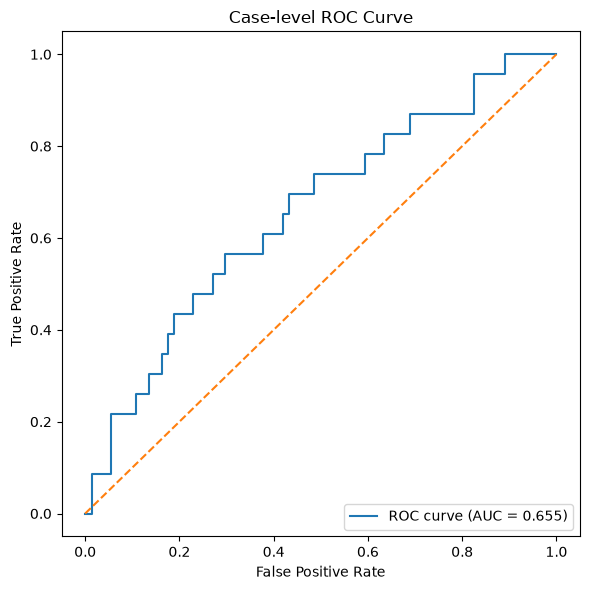

Saved: F:\yingxiang2\results\figures\figure_roc_curve_case_level.png


In [57]:
fpr, tpr, _ = roc_curve(y_case, p_case)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {case_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-level ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()

roc_fig_path = FIG_DIR / "figure_roc_curve_case_level.png"
plt.savefig(roc_fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", roc_fig_path)

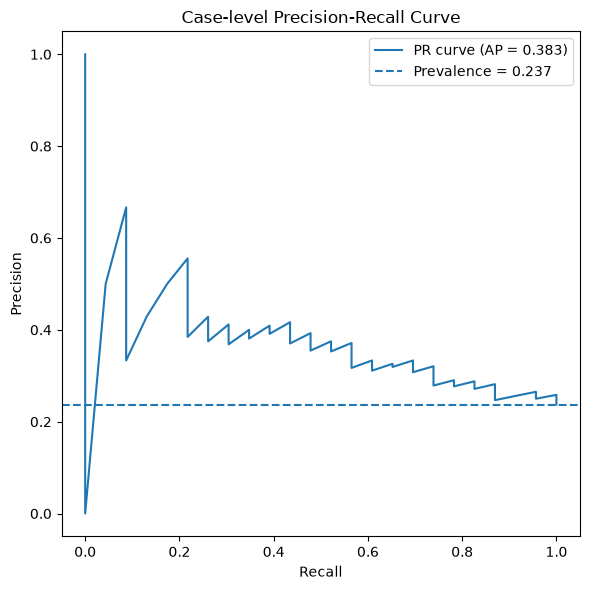

Saved: F:\yingxiang2\results\figures\figure_pr_curve_case_level.png


In [58]:
precision, recall, _ = precision_recall_curve(y_case, p_case)
positive_rate = y_case.mean()

plt.figure(figsize=(6, 6))
plt.plot(recall, precision, label=f"PR curve (AP = {case_pr_auc:.3f})")
plt.axhline(positive_rate, linestyle="--", label=f"Prevalence = {positive_rate:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Case-level Precision-Recall Curve")
plt.legend(loc="best")
plt.tight_layout()

pr_fig_path = FIG_DIR / "figure_pr_curve_case_level.png"
plt.savefig(pr_fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", pr_fig_path)

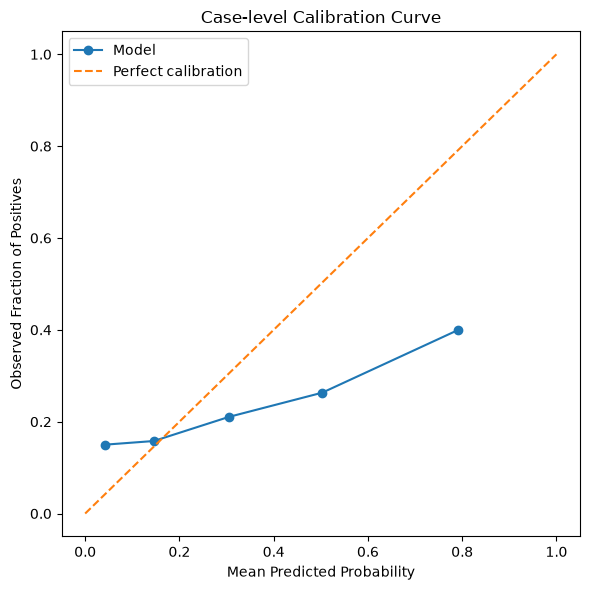

Saved: F:\yingxiang2\results\figures\figure_calibration_curve_case_level.png


In [59]:
prob_true, prob_pred = calibration_curve(y_case, p_case, n_bins=5, strategy="quantile")

plt.figure(figsize=(6, 6))
plt.plot(prob_pred, prob_true, marker="o", label="Model")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Fraction of Positives")
plt.title("Case-level Calibration Curve")
plt.legend(loc="best")
plt.tight_layout()

cal_fig_path = FIG_DIR / "figure_calibration_curve_case_level.png"
plt.savefig(cal_fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", cal_fig_path)

In [60]:
summary_table = pd.DataFrame({
    "metric": ["ROC-AUC", "PR-AUC", "Brier score"],
    "estimate": [case_auc, case_pr_auc, case_brier],
    "ci_lower": [
        ci_results["roc_auc"]["lower"],
        ci_results["pr_auc"]["lower"],
        ci_results["brier"]["lower"]
    ],
    "ci_upper": [
        ci_results["roc_auc"]["upper"],
        ci_results["pr_auc"]["upper"],
        ci_results["brier"]["upper"]
    ]
})

summary_table["display"] = summary_table.apply(
    lambda row: f"{row['estimate']:.3f} ({row['ci_lower']:.3f}–{row['ci_upper']:.3f})",
    axis=1
)

display(summary_table)

summary_csv_path = TABLE_DIR / "table_main_case_level_performance.csv"
summary_table.to_csv(summary_csv_path, index=False)

print("Saved:", summary_csv_path)

,metric,estimate,ci_lower,ci_upper,display
0,ROC-AUC,0.655112,0.521866,0.778497,0.655 (0.522–0.778)
1,PR-AUC,0.383007,0.246949,0.591702,0.383 (0.247–0.592)
2,Brier score,0.216906,0.165954,0.271329,0.217 (0.166–0.271)


Saved: F:\yingxiang2\results\tables\table_main_case_level_performance.csv


In [61]:
case_level_csv_path = TABLE_DIR / "case_level_mean_oof_predictions.csv"
case_level_oof.to_csv(case_level_csv_path, index=False)
print("Saved:", case_level_csv_path)

Saved: F:\yingxiang2\results\tables\case_level_mean_oof_predictions.csv


In [62]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"F:\yingxiang2")
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
TABLE_DIR = PROJECT_ROOT / "results" / "tables"

TABLE_DIR.mkdir(parents=True, exist_ok=True)

radiomics_df = pd.read_csv(
    METRICS_DIR / "repeated_nested_cv_l2_logistic.csv"
)

clinical_df = pd.read_csv(
    METRICS_DIR / "repeated_nested_cv_clinical_only.csv"
)

protocol_df = pd.read_csv(
    METRICS_DIR / "repeated_nested_cv_protocol_only.csv"
)

combined_df = pd.read_csv(
    METRICS_DIR / "repeated_nested_cv_combined.csv"
)

model_summary = pd.DataFrame([
    {
        "Model": "Radiomics-only",
        "Mean ROC-AUC": radiomics_df["roc_auc"].mean(),
        "SD ROC-AUC": radiomics_df["roc_auc"].std(),
        "Median ROC-AUC": radiomics_df["roc_auc"].median(),
        "Mean PR-AUC": radiomics_df["pr_auc"].mean(),
        "SD PR-AUC": radiomics_df["pr_auc"].std(),
        "Median PR-AUC": radiomics_df["pr_auc"].median(),
    },
    {
        "Model": "Clinical-only",
        "Mean ROC-AUC": clinical_df["roc_auc"].mean(),
        "SD ROC-AUC": clinical_df["roc_auc"].std(),
        "Median ROC-AUC": clinical_df["roc_auc"].median(),
        "Mean PR-AUC": clinical_df["pr_auc"].mean(),
        "SD PR-AUC": clinical_df["pr_auc"].std(),
        "Median PR-AUC": clinical_df["pr_auc"].median(),
    },
    {
        "Model": "Protocol-only",
        "Mean ROC-AUC": protocol_df["roc_auc"].mean(),
        "SD ROC-AUC": protocol_df["roc_auc"].std(),
        "Median ROC-AUC": protocol_df["roc_auc"].median(),
        "Mean PR-AUC": protocol_df["pr_auc"].mean(),
        "SD PR-AUC": protocol_df["pr_auc"].std(),
        "Median PR-AUC": protocol_df["pr_auc"].median(),
    },
    {
        "Model": "Clinical + Radiomics",
        "Mean ROC-AUC": combined_df["roc_auc"].mean(),
        "SD ROC-AUC": combined_df["roc_auc"].std(),
        "Median ROC-AUC": combined_df["roc_auc"].median(),
        "Mean PR-AUC": combined_df["pr_auc"].mean(),
        "SD PR-AUC": combined_df["pr_auc"].std(),
        "Median PR-AUC": combined_df["pr_auc"].median(),
    },
])

display(model_summary.round(3))

MODEL_SUMMARY_PATH = (
    TABLE_DIR
    / "table_model_comparison_repeated_nested_cv.csv"
)

model_summary.to_csv(
    MODEL_SUMMARY_PATH,
    index=False
)

print("Saved:", MODEL_SUMMARY_PATH)

,Model,Mean ROC-AUC,SD ROC-AUC,Median ROC-AUC,Mean PR-AUC,SD PR-AUC,Median PR-AUC
0,Radiomics-only,0.628,0.049,0.619,0.353,0.048,0.356
1,Clinical-only,0.571,0.047,0.586,0.291,0.033,0.303
2,Protocol-only,0.543,0.052,0.538,0.316,0.044,0.317
3,Clinical + Radiomics,0.582,0.052,0.588,0.319,0.041,0.325


Saved: F:\yingxiang2\results\tables\table_model_comparison_repeated_nested_cv.csv


In [67]:
from pathlib import Path
import json
import requests
import pandas as pd

PROJECT_ROOT = Path(r"F:\yingxiang2")

OUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "external_validation"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# 1. TCIA: 获取 TCGA-LUAD 中有 CT 的病例
# ============================================================

TCIA_URL = (
    "https://services.cancerimagingarchive.net/"
    "nbia-api/services/v1/"
    "getPatientByCollectionAndModality"
)

params = {
    "Collection": "TCGA-LUAD",
    "Modality": "CT"
}

r = requests.get(
    TCIA_URL,
    params=params,
    timeout=60
)

r.raise_for_status()

tcia_json = r.json()

print("TCIA response type:", type(tcia_json))
print("TCIA raw rows:", len(tcia_json))

# API 返回字段通常为 PatientId / PatientID
tcia_ids = []

for item in tcia_json:

    if isinstance(item, str):
        pid = item

    else:
        pid = (
            item.get("PatientId")
            or item.get("PatientID")
            or item.get("patientId")
        )

    if pid:
        tcia_ids.append(
            str(pid).strip().upper()
        )

tcia_ids = sorted(set(tcia_ids))

print("\nCT patients from TCIA:", len(tcia_ids))
print(tcia_ids[:10])

TCIA response type: <class 'list'>
TCIA raw rows: 67

CT patients from TCIA: 67
['TCGA-17-Z011', 'TCGA-17-Z013', 'TCGA-17-Z015', 'TCGA-17-Z016', 'TCGA-17-Z017', 'TCGA-17-Z018', 'TCGA-17-Z019', 'TCGA-17-Z020', 'TCGA-17-Z021', 'TCGA-17-Z023']


In [64]:
import sys
print(sys.executable)

C:\Users\Administrator\.conda\envs\lung2\python.exe


In [65]:
import requests
print(requests.__version__)

2.34.2


In [66]:
import sys
import requests

print(sys.executable)
print(requests.__version__)

C:\Users\Administrator\.conda\envs\lung2\python.exe
2.34.2


In [68]:
# ============================================================
# 2. GDC: 获取有 Masked Somatic Mutation 数据的 TCGA-LUAD 病例
# ============================================================

GDC_CASES_URL = "https://api.gdc.cancer.gov/cases"

case_filters = {
    "op": "and",
    "content": [
        {
            "op": "in",
            "content": {
                "field": "project.project_id",
                "value": ["TCGA-LUAD"]
            }
        },
        {
            "op": "in",
            "content": {
                "field": "files.data_type",
                "value": ["Masked Somatic Mutation"]
            }
        }
    ]
}

case_params = {
    "filters": json.dumps(case_filters),
    "fields": "submitter_id",
    "format": "JSON",
    "size": "2000"
}

r = requests.get(
    GDC_CASES_URL,
    params=case_params,
    timeout=120
)

print("GDC status:", r.status_code)

if not r.ok:
    print(r.text[:3000])
    r.raise_for_status()

case_data = r.json()

mutation_assayed_ids = sorted({
    hit["submitter_id"].strip().upper()
    for hit in case_data["data"]["hits"]
})

print(
    "TCGA-LUAD cases with somatic mutation data:",
    len(mutation_assayed_ids)
)

print(mutation_assayed_ids[:10])

# 和TCIA的67例先做交集
ct_mutation_intersection = sorted(
    set(tcia_ids) & set(mutation_assayed_ids)
)

print(
    "\nCT + somatic mutation data intersection:",
    len(ct_mutation_intersection)
)

print(ct_mutation_intersection[:20])

GDC status: 200
TCGA-LUAD cases with somatic mutation data: 559
['TCGA-05-4244', 'TCGA-05-4249', 'TCGA-05-4250', 'TCGA-05-4382', 'TCGA-05-4384', 'TCGA-05-4389', 'TCGA-05-4390', 'TCGA-05-4395', 'TCGA-05-4396', 'TCGA-05-4397']

CT + somatic mutation data intersection: 60
['TCGA-17-Z011', 'TCGA-17-Z013', 'TCGA-17-Z015', 'TCGA-17-Z016', 'TCGA-17-Z017', 'TCGA-17-Z018', 'TCGA-17-Z019', 'TCGA-17-Z020', 'TCGA-17-Z021', 'TCGA-17-Z023', 'TCGA-17-Z027', 'TCGA-17-Z028', 'TCGA-17-Z030', 'TCGA-17-Z031', 'TCGA-17-Z032', 'TCGA-17-Z033', 'TCGA-17-Z036', 'TCGA-17-Z042', 'TCGA-17-Z043', 'TCGA-17-Z045']


In [69]:
# ============================================================
# 3. GDC: 获取 TCGA-LUAD 中 EGFR-mutant 病例
# ============================================================

GDC_SSM_OCC_URL = "https://api.gdc.cancer.gov/ssm_occurrences"

EGFR_ENSEMBL = "ENSG00000146648"

egfr_filters = {
    "op": "and",
    "content": [
        {
            "op": "in",
            "content": {
                "field": "case.project.project_id",
                "value": ["TCGA-LUAD"]
            }
        },
        {
            "op": "in",
            "content": {
                "field": "ssm.consequence.transcript.gene.gene_id",
                "value": [EGFR_ENSEMBL]
            }
        }
    ]
}

egfr_params = {
    "filters": json.dumps(egfr_filters),
    "fields": "case.submitter_id,ssm.gene_aa_change,ssm.chromosome,ssm.start_position",
    "format": "JSON",
    "size": "5000"
}

r = requests.get(
    GDC_SSM_OCC_URL,
    params=egfr_params,
    timeout=120
)

print("GDC status:", r.status_code)

if not r.ok:
    print(r.text[:4000])
    r.raise_for_status()

egfr_data = r.json()

print("Raw EGFR mutation occurrences:", len(egfr_data["data"]["hits"]))

egfr_mutant_ids = sorted({
    hit["case"]["submitter_id"].strip().upper()
    for hit in egfr_data["data"]["hits"]
    if hit.get("case")
    and hit["case"].get("submitter_id")
})

print("Unique EGFR-mutant TCGA-LUAD cases:", len(egfr_mutant_ids))
print(egfr_mutant_ids)

GDC status: 200
Raw EGFR mutation occurrences: 93
Unique EGFR-mutant TCGA-LUAD cases: 78
['TCGA-05-4382', 'TCGA-05-4402', 'TCGA-05-4410', 'TCGA-05-4425', 'TCGA-05-5423', 'TCGA-17-Z026', 'TCGA-17-Z032', 'TCGA-17-Z047', 'TCGA-17-Z048', 'TCGA-38-4627', 'TCGA-38-4628', 'TCGA-38-4629', 'TCGA-38-6178', 'TCGA-44-2661', 'TCGA-44-5645', 'TCGA-44-6147', 'TCGA-44-A4SU', 'TCGA-49-4490', 'TCGA-49-4494', 'TCGA-49-4501', 'TCGA-49-6743', 'TCGA-50-5066', 'TCGA-50-5933', 'TCGA-50-5935', 'TCGA-50-5944', 'TCGA-50-6591', 'TCGA-50-6595', 'TCGA-50-6673', 'TCGA-55-6980', 'TCGA-55-6981', 'TCGA-55-7570', 'TCGA-55-8087', 'TCGA-55-8096', 'TCGA-55-8206', 'TCGA-55-8506', 'TCGA-55-A48Z', 'TCGA-55-A57B', 'TCGA-62-8394', 'TCGA-62-8397', 'TCGA-62-8402', 'TCGA-62-A46U', 'TCGA-64-1681', 'TCGA-67-3770', 'TCGA-67-3771', 'TCGA-67-6217', 'TCGA-69-7760', 'TCGA-69-7765', 'TCGA-71-6725', 'TCGA-71-8520', 'TCGA-75-6207', 'TCGA-75-6212', 'TCGA-75-7025', 'TCGA-78-7147', 'TCGA-78-7155', 'TCGA-78-7158', 'TCGA-86-8055', 'TCGA-86-8074'

In [70]:
# ============================================================
# 4. CT + mutation data + EGFR status
# ============================================================

ct_set = set(tcia_ids)
assayed_set = set(mutation_assayed_ids)
mutant_set = set(egfr_mutant_ids)

eligible_ids = sorted(
    ct_set & assayed_set
)

rows = []

for case_id in eligible_ids:

    rows.append({
        "Case ID": case_id,
        "EGFR mutation status": (
            "Mutant"
            if case_id in mutant_set
            else "Wildtype"
        )
    })

external_candidates = pd.DataFrame(rows)

print("Eligible external candidates:", len(external_candidates))

print("\nEGFR distribution:")
print(
    external_candidates[
        "EGFR mutation status"
    ].value_counts()
)

print("\nMutant prevalence:")
print(
    external_candidates[
        "EGFR mutation status"
    ].eq("Mutant").mean()
)

display(external_candidates)

Eligible external candidates: 60

EGFR distribution:
EGFR mutation status
Wildtype    50
Mutant      10
Name: count, dtype: int64

Mutant prevalence:
0.16666666666666666


,Case ID,EGFR mutation status
0,TCGA-17-Z011,Wildtype
1,TCGA-17-Z013,Wildtype
2,TCGA-17-Z015,Wildtype
3,TCGA-17-Z016,Wildtype
4,TCGA-17-Z017,Wildtype
5,TCGA-17-Z018,Wildtype
6,TCGA-17-Z019,Wildtype
7,TCGA-17-Z020,Wildtype
8,TCGA-17-Z021,Wildtype
9,TCGA-17-Z023,Wildtype


In [71]:
OUTPUT_PATH = (
    PROJECT_ROOT
    / "results"
    / "external_validation"
    / "tcga_luad_egfr_external_candidates.csv"
)

external_candidates.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Saved:", OUTPUT_PATH)

Saved: F:\yingxiang2\results\external_validation\tcga_luad_egfr_external_candidates.csv


In [72]:
# 查看 external candidate 中 mutant 病例的 EGFR mutation detail

mutant_candidate_ids = (
    external_candidates.loc[
        external_candidates["EGFR mutation status"] == "Mutant",
        "Case ID"
    ]
    .tolist()
)

print("Mutant candidates:", len(mutant_candidate_ids))
print(mutant_candidate_ids)

# 把刚才 egfr_hits 中属于这10例的详细变异打印出来
mutation_detail_rows = []

for hit in egfr_hits:

    case_info = hit.get("case", {})
    case_id = case_info.get("submitter_id")

    if not case_id:
        continue

    case_id = case_id.strip().upper()

    if case_id not in mutant_candidate_ids:
        continue

    ssm = hit.get("ssm", {})

    mutation_detail_rows.append({
        "Case ID": case_id,
        "gene_aa_change": ssm.get("gene_aa_change"),
        "chromosome": ssm.get("chromosome"),
        "start_position": ssm.get("start_position"),
        "ssm_id": ssm.get("ssm_id"),
    })

mutation_detail_df = pd.DataFrame(mutation_detail_rows)

display(
    mutation_detail_df.sort_values("Case ID")
)

Mutant candidates: 10
['TCGA-17-Z032', 'TCGA-17-Z048', 'TCGA-38-4628', 'TCGA-38-4629', 'TCGA-38-6178', 'TCGA-50-5066', 'TCGA-50-6591', 'TCGA-50-6595', 'TCGA-50-6673', 'TCGA-J2-8192']


NameError: name 'egfr_hits' is not defined

In [73]:
# ============================================================
# Re-query EGFR mutation occurrences for TCGA-LUAD
# ============================================================

GDC_SSM_OCC_URL = "https://api.gdc.cancer.gov/ssm_occurrences"
EGFR_ENSEMBL = "ENSG00000146648"

egfr_filters = {
    "op": "and",
    "content": [
        {
            "op": "in",
            "content": {
                "field": "case.project.project_id",
                "value": ["TCGA-LUAD"]
            }
        },
        {
            "op": "in",
            "content": {
                "field": "ssm.consequence.transcript.gene.gene_id",
                "value": [EGFR_ENSEMBL]
            }
        }
    ]
}

egfr_params = {
    "filters": json.dumps(egfr_filters),
    "fields": (
        "case.submitter_id,"
        "ssm.ssm_id,"
        "ssm.gene_aa_change,"
        "ssm.chromosome,"
        "ssm.start_position"
    ),
    "format": "JSON",
    "size": "5000"
}

r = requests.get(
    GDC_SSM_OCC_URL,
    params=egfr_params,
    timeout=120
)

print("GDC status:", r.status_code)

if not r.ok:
    print(r.text[:4000])
    r.raise_for_status()

egfr_data = r.json()
egfr_hits = egfr_data["data"]["hits"]

print("EGFR mutation occurrence records:", len(egfr_hits))

GDC status: 200
EGFR mutation occurrence records: 93


In [74]:
mutant_candidate_ids = (
    external_candidates.loc[
        external_candidates["EGFR mutation status"] == "Mutant",
        "Case ID"
    ]
    .tolist()
)

mutation_detail_rows = []

for hit in egfr_hits:

    case_info = hit.get("case", {})
    case_id = case_info.get("submitter_id")

    if not case_id:
        continue

    case_id = case_id.strip().upper()

    if case_id not in mutant_candidate_ids:
        continue

    ssm = hit.get("ssm", {})

    mutation_detail_rows.append({
        "Case ID": case_id,
        "gene_aa_change": ssm.get("gene_aa_change"),
        "chromosome": ssm.get("chromosome"),
        "start_position": ssm.get("start_position"),
        "ssm_id": ssm.get("ssm_id"),
    })

mutation_detail_df = pd.DataFrame(mutation_detail_rows)

display(
    mutation_detail_df.sort_values("Case ID")
)

,Case ID,gene_aa_change,chromosome,start_position,ssm_id
0,TCGA-17-Z032,None,chr7,55174772,c10dc76b-12e7-5cd6-a2d9-9a35fb2ff346
2,TCGA-17-Z048,None,chr7,55181319,eb377689-a0d1-5a97-93a0-2dedfc58b7d1
7,TCGA-38-4628,None,chr7,55174772,c10dc76b-12e7-5cd6-a2d9-9a35fb2ff346
10,TCGA-38-4629,None,chr7,55160233,5b4bd2f6-f770-5e14-82f2-3b6e383c1b8f
8,TCGA-38-6178,None,chr7,55174772,c10dc76b-12e7-5cd6-a2d9-9a35fb2ff346
1,TCGA-50-5066,None,chr7,55152547,aefffa30-7d9f-5f81-997f-4a81bcc0bd02
5,TCGA-50-6591,None,chr7,55174797,a5e99f23-1182-5b47-b805-a4c3df7dea58
11,TCGA-50-6591,None,chr7,55191746,8af982d4-93df-520a-9350-7684f8a6103c
3,TCGA-50-6595,None,chr7,55174015,088991ed-dc0e-5fcb-b50e-553fbcb643cf
4,TCGA-50-6595,None,chr7,55181312,d4f7e850-5a69-5ada-8961-731ce8ef5c37


In [75]:
MUTATION_DETAIL_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "external_validation"
    / "tcga_luad_egfr_mutation_details.csv"
)

mutation_detail_df.to_csv(
    MUTATION_DETAIL_OUTPUT,
    index=False
)

print("Saved:", MUTATION_DETAIL_OUTPUT)

Saved: F:\yingxiang2\results\external_validation\tcga_luad_egfr_mutation_details.csv


In [76]:
detail_rows = []

for _, row in mutation_detail_df.iterrows():

    ssm_id = row["ssm_id"]
    case_id = row["Case ID"]

    url = f"https://api.gdc.cancer.gov/ssms/{ssm_id}"

    params = {
        "expand": "consequence.transcript",
        "fields": (
            "ssm_id,"
            "chromosome,"
            "start_position,"
            "reference_allele,"
            "tumor_allele,"
            "consequence.transcript.transcript_id,"
            "consequence.transcript.aa_change,"
            "consequence.transcript.consequence_type,"
            "consequence.transcript.is_canonical,"
            "consequence.transcript.annotation.vep_impact"
        ),
        "pretty": "true"
    }

    r = requests.get(
        url,
        params=params,
        timeout=60
    )

    print(case_id, ssm_id, r.status_code)

    if not r.ok:
        print(r.text[:1000])
        continue

    data = r.json()["data"]

    consequences = data.get("consequence", [])

    # 优先取 canonical transcript
    canonical_found = False

    for c in consequences:

        transcript = c.get("transcript", {})

        if not transcript:
            continue

        is_canonical = transcript.get("is_canonical", False)

        if is_canonical:
            canonical_found = True

            detail_rows.append({
                "Case ID": case_id,
                "ssm_id": ssm_id,
                "chromosome": data.get("chromosome"),
                "start_position": data.get("start_position"),
                "reference_allele": data.get("reference_allele"),
                "tumor_allele": data.get("tumor_allele"),
                "transcript_id": transcript.get("transcript_id"),
                "aa_change": transcript.get("aa_change"),
                "consequence_type": transcript.get("consequence_type"),
                "is_canonical": is_canonical,
                "vep_impact": (
                    transcript
                    .get("annotation", {})
                    .get("vep_impact")
                )
            })

    # 如果没有 canonical transcript，也保留第一条可用 consequence
    if not canonical_found and len(consequences) > 0:

        transcript = consequences[0].get("transcript", {})

        detail_rows.append({
            "Case ID": case_id,
            "ssm_id": ssm_id,
            "chromosome": data.get("chromosome"),
            "start_position": data.get("start_position"),
            "reference_allele": data.get("reference_allele"),
            "tumor_allele": data.get("tumor_allele"),
            "transcript_id": transcript.get("transcript_id"),
            "aa_change": transcript.get("aa_change"),
            "consequence_type": transcript.get("consequence_type"),
            "is_canonical": transcript.get("is_canonical"),
            "vep_impact": (
                transcript
                .get("annotation", {})
                .get("vep_impact")
            )
        })

egfr_variant_detail_df = pd.DataFrame(detail_rows)

display(
    egfr_variant_detail_df.sort_values(
        ["Case ID", "start_position"]
    )
)

TCGA-17-Z032 c10dc76b-12e7-5cd6-a2d9-9a35fb2ff346 200
TCGA-50-5066 aefffa30-7d9f-5f81-997f-4a81bcc0bd02 200
TCGA-17-Z048 eb377689-a0d1-5a97-93a0-2dedfc58b7d1 200
TCGA-50-6595 088991ed-dc0e-5fcb-b50e-553fbcb643cf 200
TCGA-50-6595 d4f7e850-5a69-5ada-8961-731ce8ef5c37 200
TCGA-50-6591 a5e99f23-1182-5b47-b805-a4c3df7dea58 200
TCGA-J2-8192 b06c4342-0f66-59a0-bb9d-a804f33b401b 200
TCGA-38-4628 c10dc76b-12e7-5cd6-a2d9-9a35fb2ff346 200
TCGA-38-6178 c10dc76b-12e7-5cd6-a2d9-9a35fb2ff346 200
TCGA-50-6673 f656e527-b38d-5516-8910-b2499d0db7c4 200
TCGA-38-4629 5b4bd2f6-f770-5e14-82f2-3b6e383c1b8f 200
TCGA-50-6591 8af982d4-93df-520a-9350-7684f8a6103c 200


,Case ID,ssm_id,chromosome,start_position,reference_allele,tumor_allele,transcript_id,aa_change,consequence_type,is_canonical,vep_impact
0,TCGA-17-Z032,c10dc76b-12e7-5cd6-a2d9-9a35fb2ff346,chr7,55174772,GGAATTAAGAGAAGC,-,ENST00000275493,E746_A750del,inframe_deletion,True,MODERATE
2,TCGA-17-Z048,eb377689-a0d1-5a97-93a0-2dedfc58b7d1,chr7,55181319,-,GGGTTA,ENST00000275493,D770_N771insGL,inframe_insertion,True,MODERATE
7,TCGA-38-4628,c10dc76b-12e7-5cd6-a2d9-9a35fb2ff346,chr7,55174772,GGAATTAAGAGAAGC,-,ENST00000275493,E746_A750del,inframe_deletion,True,MODERATE
10,TCGA-38-4629,5b4bd2f6-f770-5e14-82f2-3b6e383c1b8f,chr7,55160233,G,A,ENST00000275493,G465R,missense_variant,True,MODERATE
8,TCGA-38-6178,c10dc76b-12e7-5cd6-a2d9-9a35fb2ff346,chr7,55174772,GGAATTAAGAGAAGC,-,ENST00000275493,E746_A750del,inframe_deletion,True,MODERATE
1,TCGA-50-5066,aefffa30-7d9f-5f81-997f-4a81bcc0bd02,chr7,55152547,G,T,ENST00000275493,L210=,splice_region_variant,True,LOW
5,TCGA-50-6591,a5e99f23-1182-5b47-b805-a4c3df7dea58,chr7,55174797,AAAGCCAACAAGGAAATC,-,ENST00000275493,K754_I759del,inframe_deletion,True,MODERATE
11,TCGA-50-6591,8af982d4-93df-520a-9350-7684f8a6103c,chr7,55191746,T,G,ENST00000275493,L833V,missense_variant,True,MODERATE
3,TCGA-50-6595,088991ed-dc0e-5fcb-b50e-553fbcb643cf,chr7,55174015,G,C,ENST00000275493,G719A,missense_variant,True,MODERATE
4,TCGA-50-6595,d4f7e850-5a69-5ada-8961-731ce8ef5c37,chr7,55181312,G,T,ENST00000275493,S768I,missense_variant,True,MODERATE


In [77]:
VARIANT_DETAIL_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "external_validation"
    / "tcga_luad_egfr_variant_details_canonical.csv"
)

egfr_variant_detail_df.to_csv(
    VARIANT_DETAIL_OUTPUT,
    index=False
)

print("Saved:", VARIANT_DETAIL_OUTPUT)

Saved: F:\yingxiang2\results\external_validation\tcga_luad_egfr_variant_details_canonical.csv


In [78]:
driver_positive_ids = {
    "TCGA-17-Z032",
    "TCGA-17-Z048",
    "TCGA-38-4628",
    "TCGA-38-6178",
    "TCGA-50-6591",
    "TCGA-50-6595",
    "TCGA-50-6673",
    "TCGA-J2-8192",
}

uncertain_ids = {
    "TCGA-38-4629",  # G465R
    "TCGA-50-5066",  # L210= / splice_region / LOW
}

external_primary = external_candidates.copy()

external_primary["EGFR external label"] = external_primary["Case ID"].apply(
    lambda x:
        "Mutant"
        if x in driver_positive_ids
        else (
            "Exclude_uncertain"
            if x in uncertain_ids
            else "Wildtype"
        )
)

print(external_primary["EGFR external label"].value_counts())

external_primary_clean = external_primary[
    external_primary["EGFR external label"] != "Exclude_uncertain"
].copy()

print("\nPrimary external cohort:")
print(external_primary_clean["EGFR external label"].value_counts())
print("Total:", len(external_primary_clean))

EGFR external label
Wildtype             50
Mutant                8
Exclude_uncertain     2
Name: count, dtype: int64

Primary external cohort:
EGFR external label
Wildtype    50
Mutant       8
Name: count, dtype: int64
Total: 58


In [79]:
PRIMARY_EXTERNAL_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "external_validation"
    / "tcga_luad_egfr_external_primary_cohort.csv"
)

external_primary_clean.to_csv(
    PRIMARY_EXTERNAL_OUTPUT,
    index=False
)

print("Saved:", PRIMARY_EXTERNAL_OUTPUT)

Saved: F:\yingxiang2\results\external_validation\tcga_luad_egfr_external_primary_cohort.csv


In [80]:
from idc_index import index

client = index.IDCClient()

print("IDC client ready")

UnicodeDecodeError: 'gbk' codec can't decode byte 0x94 in position 974: illegal multibyte sequence

In [1]:
import sys
import locale

print(sys.executable)
print("UTF-8 mode:", sys.flags.utf8_mode)
print("Preferred encoding:", locale.getpreferredencoding(False))

from idc_index import index

client = index.IDCClient()

print("IDC client ready")

C:\Users\Administrator\.conda\envs\lung2\python.exe
UTF-8 mode: 1
Preferred encoding: utf-8
IDC client ready


In [2]:
import sys
import locale

print(sys.executable)
print("UTF-8 mode:", sys.flags.utf8_mode)
print("Preferred encoding:", locale.getpreferredencoding(False))

from idc_index import index

client = index.IDCClient()

print("IDC client ready")

C:\Users\Administrator\.conda\envs\lung2\python.exe
UTF-8 mode: 1
Preferred encoding: utf-8
IDC client ready


In [3]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"F:\yingxiang2")

PRIMARY_EXTERNAL_PATH = (
    PROJECT_ROOT
    / "results"
    / "external_validation"
    / "tcga_luad_egfr_external_primary_cohort.csv"
)

external_primary_clean = pd.read_csv(PRIMARY_EXTERNAL_PATH)

print(external_primary_clean.shape)
print(external_primary_clean["EGFR external label"].value_counts())

(58, 3)
EGFR external label
Wildtype    50
Mutant       8
Name: count, dtype: int64


In [4]:
from idc_index import index

client = index.IDCClient()

print(client.sql_query("""
SELECT *
FROM index
LIMIT 1
"""))

  collection_id analysis_result_id    PatientID  \
0       4d_lung               None  100_HM10395   

                                   SeriesInstanceUID  \
0  1.3.6.1.4.1.14519.5.2.1.6834.5010.155488857019...   

                                    StudyInstanceUID  \
0  1.3.6.1.4.1.14519.5.2.1.6834.5010.117291650651...   

                      source_DOI PatientAge PatientSex   StudyDate  \
0  10.7937/k9/tcia.2016.eln8ygle       000Y          M  1997-09-17   

  StudyDescription  ...              SeriesDescription SeriesNumber  \
0               p4  ...  P4^P100^S102^I0, Gated, 10.0%          501   

  instanceCount license_short_name series_init_idc_version  \
0            50          CC BY 3.0                       2   

  series_revised_idc_version     aws_bucket  \
0                          2  idc-open-data   

                       crdc_series_uuid  \
0  085e85b3-3780-47f6-8538-585bcca95336   

                                      series_aws_url series_size_MB  
0  s3://id

In [5]:
cols = client.sql_query("""
DESCRIBE index
""")

display(cols)

,column_name,column_type,null,key,default,extra
0,collection_id,VARCHAR,YES,None,None,None
1,analysis_result_id,VARCHAR,YES,None,None,None
2,PatientID,VARCHAR,YES,None,None,None
3,SeriesInstanceUID,VARCHAR,YES,None,None,None
4,StudyInstanceUID,VARCHAR,YES,None,None,None
5,source_DOI,VARCHAR,YES,None,None,None
6,PatientAge,VARCHAR,YES,None,None,None
7,PatientSex,VARCHAR,YES,None,None,None
8,StudyDate,VARCHAR,YES,None,None,None
9,StudyDescription,VARCHAR,YES,None,None,None


In [6]:
# ============================================================
# Query IDC metadata for the 58 external candidates
# ============================================================

candidate_ids = (
    external_primary_clean["Case ID"]
    .astype(str)
    .str.strip()
    .tolist()
)

# 构造 SQL IN (...)
id_sql = ", ".join(
    [f"'{x}'" for x in candidate_ids]
)

query = f"""
SELECT
    collection_id,
    analysis_result_id,
    PatientID,
    StudyInstanceUID,
    SeriesInstanceUID,
    Modality,
    BodyPartExamined,
    StudyDescription,
    SeriesDescription,
    Manufacturer,
    ManufacturerModelName,
    instanceCount,
    series_size_MB
FROM index
WHERE PatientID IN ({id_sql})
  AND Modality IN ('CT', 'SEG')
ORDER BY PatientID, Modality, StudyDate, SeriesNumber
"""

idc_candidate_series = client.sql_query(query)

print("Rows:", len(idc_candidate_series))
display(idc_candidate_series.head(30))

Rows: 558


,collection_id,analysis_result_id,PatientID,StudyInstanceUID,SeriesInstanceUID,Modality,BodyPartExamined,StudyDescription,SeriesDescription,Manufacturer,ManufacturerModelName,instanceCount,series_size_MB
0,tcga_luad,NaN,TCGA-17-Z011,1.3.6.1.4.1.14519.5.2.1.7777.9002.242742387344...,1.3.6.1.4.1.14519.5.2.1.7777.9002.930299339362...,CT,CHEST,NaN,NaN,SIEMENS,SOMATOM PLUS 4,1,0.528106
1,tcga_luad,NaN,TCGA-17-Z011,1.3.6.1.4.1.14519.5.2.1.7777.9002.242742387344...,1.3.6.1.4.1.14519.5.2.1.7777.9002.191326363093...,CT,CHEST,NaN,NaN,SIEMENS,SOMATOM PLUS 4,1,0.528084
2,tcga_luad,NaN,TCGA-17-Z011,1.3.6.1.4.1.14519.5.2.1.7777.9002.242742387344...,1.3.6.1.4.1.14519.5.2.1.7777.9002.106684271246...,CT,CHEST,NaN,NaN,SIEMENS,SOMATOM PLUS 4,33,17.427498
3,tcga_luad,NaN,TCGA-17-Z011,1.3.6.1.4.1.14519.5.2.1.7777.9002.242742387344...,1.3.6.1.4.1.14519.5.2.1.7777.9002.141834388005...,CT,CHEST,NaN,NaN,SIEMENS,SOMATOM PLUS 4,25,13.202650
4,tcga_luad,NaN,TCGA-17-Z011,1.3.6.1.4.1.14519.5.2.1.7777.9002.119175415668...,1.3.6.1.4.1.14519.5.2.1.7777.9002.294081805871...,CT,CHEST,NaN,Topogram,SIEMENS,Volume Zoom,1,0.527648
5,tcga_luad,NaN,TCGA-17-Z011,1.3.6.1.4.1.14519.5.2.1.7777.9002.233484322163...,1.3.6.1.4.1.14519.5.2.1.7777.9002.152508401007...,CT,CHEST,NaN,Topogram,SIEMENS,Volume Zoom,1,0.527648
6,tcga_luad,NaN,TCGA-17-Z011,1.3.6.1.4.1.14519.5.2.1.7777.9002.119175415668...,1.3.6.1.4.1.14519.5.2.1.7777.9002.927019691832...,CT,CHEST,NaN,Chest Routine #1,SIEMENS,Volume Zoom,71,37.461162
7,tcga_luad,NaN,TCGA-17-Z011,1.3.6.1.4.1.14519.5.2.1.7777.9002.233484322163...,1.3.6.1.4.1.14519.5.2.1.7777.9002.212063566717...,CT,CHEST,NaN,Chest Routine #1,SIEMENS,Volume Zoom,71,37.461162
8,tcga_luad,NaN,TCGA-17-Z011,1.3.6.1.4.1.14519.5.2.1.7777.9002.233484322163...,1.3.6.1.4.1.14519.5.2.1.7777.9002.330774219145...,CT,CHEST,NaN,Chest Routine #2,SIEMENS,Volume Zoom,63,33.240186
9,tcga_luad,NaN,TCGA-17-Z011,1.3.6.1.4.1.14519.5.2.1.7777.9002.119175415668...,1.3.6.1.4.1.14519.5.2.1.7777.9002.147921136202...,CT,CHEST,NaN,Chest Routine #2,SIEMENS,Volume Zoom,63,33.240186


In [7]:
# ============================================================
# Patient-level CT / SEG availability
# ============================================================

availability_rows = []

for case_id in candidate_ids:

    sub = idc_candidate_series[
        idc_candidate_series["PatientID"] == case_id
    ]

    ct_rows = sub[sub["Modality"] == "CT"]
    seg_rows = sub[sub["Modality"] == "SEG"]

    availability_rows.append({
        "Case ID": case_id,
        "n_CT_series": len(ct_rows),
        "n_SEG_series": len(seg_rows),
        "Has CT": len(ct_rows) > 0,
        "Has SEG": len(seg_rows) > 0,
    })

seg_availability_df = pd.DataFrame(availability_rows)

seg_availability_df = seg_availability_df.merge(
    external_primary_clean[
        ["Case ID", "EGFR external label"]
    ],
    on="Case ID",
    how="left"
)

print("Total candidates:", len(seg_availability_df))
print("Has CT:", seg_availability_df["Has CT"].sum())
print("Has SEG:", seg_availability_df["Has SEG"].sum())

both_mask = (
    seg_availability_df["Has CT"]
    & seg_availability_df["Has SEG"]
)

print(
    "Has both CT + SEG:",
    both_mask.sum()
)

print("\nCT + SEG by EGFR label:")
print(
    seg_availability_df.loc[
        both_mask,
        "EGFR external label"
    ].value_counts()
)

display(
    seg_availability_df.sort_values(
        [
            "Has SEG",
            "EGFR external label",
            "Case ID"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
)

Total candidates: 58
Has CT: 58
Has SEG: 29
Has both CT + SEG: 29

CT + SEG by EGFR label:
EGFR external label
Wildtype    23
Mutant       6
Name: count, dtype: int64


,Case ID,n_CT_series,n_SEG_series,Has CT,Has SEG,EGFR external label
33,TCGA-38-4628,10,4,True,True,Mutant
34,TCGA-38-6178,19,6,True,True,Mutant
46,TCGA-50-6591,7,5,True,True,Mutant
50,TCGA-50-6595,13,2,True,True,Mutant
51,TCGA-50-6673,25,4,True,True,Mutant
54,TCGA-J2-8192,6,5,True,True,Mutant
21,TCGA-17-Z050,12,1,True,True,Wildtype
24,TCGA-17-Z053,12,1,True,True,Wildtype
28,TCGA-17-Z059,14,4,True,True,Wildtype
29,TCGA-17-Z061,3,1,True,True,Wildtype


In [8]:
# ============================================================
# Inspect SEG series
# ============================================================

seg_series_df = (
    idc_candidate_series[
        idc_candidate_series["Modality"] == "SEG"
    ]
    .copy()
)

print("SEG series:", len(seg_series_df))
print(
    "Patients with SEG:",
    seg_series_df["PatientID"].nunique()
)

display(
    seg_series_df[
        [
            "PatientID",
            "analysis_result_id",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SeriesDescription",
            "BodyPartExamined",
            "instanceCount",
            "series_size_MB"
        ]
    ].sort_values(
        ["PatientID", "SeriesDescription"]
    )
)

SEG series: 109
Patients with SEG: 29


,PatientID,analysis_result_id,StudyInstanceUID,SeriesInstanceUID,SeriesDescription,BodyPartExamined,instanceCount,series_size_MB
175,TCGA-17-Z050,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.7777.9002.469638876293...,1.2.276.0.7230010.3.1.3.17436516.2894684.17206...,AIMI lung and FDG tumor AI segmentation,CHEST,1,0.586170
201,TCGA-17-Z053,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.7777.9002.271808960320...,1.2.276.0.7230010.3.1.3.17436516.2894918.17206...,AIMI lung and FDG tumor AI segmentation,CHEST,1,0.725830
246,TCGA-17-Z059,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.7777.9002.140874249667...,1.2.276.0.7230010.3.1.3.17436516.2254957.17206...,AIMI lung and nodule AI segmentation,CHEST,1,1.639726
247,TCGA-17-Z059,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.7777.9002.307068246385...,1.2.276.0.7230010.3.1.3.17436516.2157333.17206...,AIMI lung and nodule AI segmentation,CHEST,1,1.639726
249,TCGA-17-Z059,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.7777.9002.140874249667...,1.2.276.0.7230010.3.1.3.17436516.2254793.17206...,AIMI lung and nodule radiologist 1 corrected s...,CHEST,1,1.573110
...,...,...,...,...,...,...,...,...
553,TCGA-J2-A4AG,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.3983.9002.107656215131...,1.2.276.0.7230010.3.1.3.17436516.2909035.17206...,AIMI lung and FDG tumor AI segmentation,LUNG,1,0.301726
554,TCGA-J2-A4AG,tcga_sbu_til_maps,2.25.11924902233829811127497935005954504851,1.2.826.0.1.3680043.10.511.3.50177599250469803...,Stony Brook CNN-generated TIL Map,NaN,1,0.065552
556,TCGA-J2-A4AG,tcga_sbu_til_maps,2.25.11924902233829811127497935005954504851,1.2.826.0.1.3680043.10.511.3.23015253991020080...,Stony Brook Inception-V4 Binary TIL Map,NaN,1,0.038060
557,TCGA-J2-A4AG,tcga_sbu_til_maps,2.25.11924902233829811127497935005954504851,1.2.826.0.1.3680043.10.511.3.16455246420336611...,Stony Brook Inception-V4 Fractional TIL Map,NaN,1,0.226104


In [9]:
OUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "external_validation"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

seg_availability_df.to_csv(
    OUT_DIR
    / "tcga_luad_seg_availability_qc.csv",
    index=False
)

seg_series_df.to_csv(
    OUT_DIR
    / "tcga_luad_seg_series_metadata.csv",
    index=False
)

idc_candidate_series.to_csv(
    OUT_DIR
    / "tcga_luad_ct_seg_series_metadata.csv",
    index=False
)

print("Saved SEG availability and series metadata.")

Saved SEG availability and series metadata.


In [10]:
seg_series_df[
    [
        "PatientID",
        "analysis_result_id",
        "StudyInstanceUID",
        "SeriesInstanceUID",
        "SeriesDescription",
        "BodyPartExamined",
        "instanceCount",
        "series_size_MB"
    ]
].sort_values(
    ["PatientID", "SeriesDescription"]
)

,PatientID,analysis_result_id,StudyInstanceUID,SeriesInstanceUID,SeriesDescription,BodyPartExamined,instanceCount,series_size_MB
175,TCGA-17-Z050,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.7777.9002.469638876293...,1.2.276.0.7230010.3.1.3.17436516.2894684.17206...,AIMI lung and FDG tumor AI segmentation,CHEST,1,0.586170
201,TCGA-17-Z053,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.7777.9002.271808960320...,1.2.276.0.7230010.3.1.3.17436516.2894918.17206...,AIMI lung and FDG tumor AI segmentation,CHEST,1,0.725830
246,TCGA-17-Z059,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.7777.9002.140874249667...,1.2.276.0.7230010.3.1.3.17436516.2254957.17206...,AIMI lung and nodule AI segmentation,CHEST,1,1.639726
247,TCGA-17-Z059,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.7777.9002.307068246385...,1.2.276.0.7230010.3.1.3.17436516.2157333.17206...,AIMI lung and nodule AI segmentation,CHEST,1,1.639726
249,TCGA-17-Z059,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.7777.9002.140874249667...,1.2.276.0.7230010.3.1.3.17436516.2254793.17206...,AIMI lung and nodule radiologist 1 corrected s...,CHEST,1,1.573110
...,...,...,...,...,...,...,...,...
553,TCGA-J2-A4AG,bamf_aimi_annotations,1.3.6.1.4.1.14519.5.2.1.3983.9002.107656215131...,1.2.276.0.7230010.3.1.3.17436516.2909035.17206...,AIMI lung and FDG tumor AI segmentation,LUNG,1,0.301726
554,TCGA-J2-A4AG,tcga_sbu_til_maps,2.25.11924902233829811127497935005954504851,1.2.826.0.1.3680043.10.511.3.50177599250469803...,Stony Brook CNN-generated TIL Map,NaN,1,0.065552
556,TCGA-J2-A4AG,tcga_sbu_til_maps,2.25.11924902233829811127497935005954504851,1.2.826.0.1.3680043.10.511.3.23015253991020080...,Stony Brook Inception-V4 Binary TIL Map,NaN,1,0.038060
557,TCGA-J2-A4AG,tcga_sbu_til_maps,2.25.11924902233829811127497935005954504851,1.2.826.0.1.3680043.10.511.3.16455246420336611...,Stony Brook Inception-V4 Fractional TIL Map,NaN,1,0.226104


In [11]:
print(
    seg_series_df[
        ["analysis_result_id", "SeriesDescription"]
    ]
    .drop_duplicates()
    .sort_values(
        ["analysis_result_id", "SeriesDescription"]
    )
    .to_string(index=False)
)

         analysis_result_id                                         SeriesDescription
      bamf_aimi_annotations                   AIMI lung and FDG tumor AI segmentation
      bamf_aimi_annotations                      AIMI lung and nodule AI segmentation
      bamf_aimi_annotations AIMI lung and nodule radiologist 1 corrected segmentation
      bamf_aimi_annotations AIMI lung and nodule radiologist 2 corrected segmentation
pan_cancer_nuclei_seg_dicom                                                       NaN
          tcga_sbu_til_maps                         Stony Brook CNN-generated TIL Map
          tcga_sbu_til_maps                   Stony Brook Inception-V4 Binary TIL Map
          tcga_sbu_til_maps               Stony Brook Inception-V4 Fractional TIL Map


In [12]:
# ============================================================
# Keep only BAMF-AIMI radiology SEG
# ============================================================

aimi_seg_df = seg_series_df[
    seg_series_df["analysis_result_id"]
    == "bamf_aimi_annotations"
].copy()

print("BAMF-AIMI SEG series:", len(aimi_seg_df))
print(
    "BAMF-AIMI patients:",
    aimi_seg_df["PatientID"].nunique()
)

print("\nSeries descriptions:")
print(
    aimi_seg_df["SeriesDescription"]
    .value_counts(dropna=False)
)

BAMF-AIMI SEG series: 31
BAMF-AIMI patients: 20

Series descriptions:
SeriesDescription
AIMI lung and FDG tumor AI segmentation                      17
AIMI lung and nodule AI segmentation                         11
AIMI lung and nodule radiologist 2 corrected segmentation     2
AIMI lung and nodule radiologist 1 corrected segmentation     1
Name: count, dtype: int64


In [13]:
def classify_seg(desc):

    desc = str(desc).lower()

    if "radiologist 1 corrected" in desc:
        return "radiologist_corrected_1"

    if "radiologist 2 corrected" in desc:
        return "radiologist_corrected_2"

    if "lung and nodule ai" in desc:
        return "nodule_ai"

    if "fdg tumor ai" in desc:
        return "fdg_tumor_ai"

    return "other"


aimi_seg_df["seg_type"] = (
    aimi_seg_df["SeriesDescription"]
    .apply(classify_seg)
)

print(
    aimi_seg_df["seg_type"]
    .value_counts()
)

seg_type
fdg_tumor_ai               17
nodule_ai                  11
radiologist_corrected_2     2
radiologist_corrected_1     1
Name: count, dtype: int64


In [14]:
aimi_seg_df = aimi_seg_df.merge(
    external_primary_clean[
        ["Case ID", "EGFR external label"]
    ],
    left_on="PatientID",
    right_on="Case ID",
    how="left"
)

print("\nPatients by segmentation type:")

patient_seg_summary = (
    aimi_seg_df[
        [
            "PatientID",
            "EGFR external label",
            "seg_type"
        ]
    ]
    .drop_duplicates()
    .groupby(
        ["seg_type", "EGFR external label"]
    )
    .size()
    .unstack(fill_value=0)
)

display(patient_seg_summary)


Patients by segmentation type:


EGFR external label,Mutant,Wildtype
seg_type,,
fdg_tumor_ai,3,13
nodule_ai,2,6
radiologist_corrected_1,0,1
radiologist_corrected_2,0,2


In [15]:
corrected_mask = (
    aimi_seg_df["seg_type"]
    .str.startswith("radiologist_corrected")
)

corrected_patients = (
    aimi_seg_df.loc[
        corrected_mask,
        [
            "PatientID",
            "EGFR external label",
            "seg_type",
            "SeriesInstanceUID",
            "SeriesDescription"
        ]
    ]
    .drop_duplicates()
)

print(
    "Patients with radiologist-corrected SEG:",
    corrected_patients["PatientID"].nunique()
)

print("\nEGFR labels among corrected SEG:")
print(
    corrected_patients[
        ["PatientID", "EGFR external label"]
    ]
    .drop_duplicates()[
        "EGFR external label"
    ]
    .value_counts()
)

display(corrected_patients)

Patients with radiologist-corrected SEG: 2

EGFR labels among corrected SEG:
EGFR external label
Wildtype    2
Name: count, dtype: int64


,PatientID,EGFR external label,seg_type,SeriesInstanceUID,SeriesDescription
4,TCGA-17-Z059,Wildtype,radiologist_corrected_2,1.2.276.0.7230010.3.1.3.17436516.2879906.17206...,AIMI lung and nodule radiologist 2 corrected s...
5,TCGA-17-Z059,Wildtype,radiologist_corrected_1,1.2.276.0.7230010.3.1.3.17436516.2254793.17206...,AIMI lung and nodule radiologist 1 corrected s...
25,TCGA-50-8460,Wildtype,radiologist_corrected_2,1.2.276.0.7230010.3.1.3.17436516.2880718.17206...,AIMI lung and nodule radiologist 2 corrected s...


In [16]:
nodule_mask = aimi_seg_df["seg_type"].isin([
    "radiologist_corrected_1",
    "radiologist_corrected_2",
    "nodule_ai"
])

nodule_patients = (
    aimi_seg_df.loc[
        nodule_mask,
        ["PatientID", "EGFR external label"]
    ]
    .drop_duplicates()
)

print(
    "Patients with nodule SEG:",
    nodule_patients["PatientID"].nunique()
)

print("\nEGFR distribution:")
print(
    nodule_patients[
        "EGFR external label"
    ].value_counts()
)

Patients with nodule SEG: 8

EGFR distribution:
EGFR external label
Wildtype    6
Mutant      2
Name: count, dtype: int64


In [17]:
# 只保留 BAMF-AIMI
aimi_meta = idc_candidate_series[
    idc_candidate_series["analysis_result_id"]
    == "bamf_aimi_annotations"
].copy()

# 给 SEG 分类
def classify_seg(desc):
    desc = str(desc).lower()

    if "radiologist 1 corrected" in desc:
        return "radiologist_corrected_1"

    if "radiologist 2 corrected" in desc:
        return "radiologist_corrected_2"

    if "lung and nodule ai" in desc:
        return "nodule_ai"

    if "fdg tumor ai" in desc:
        return "fdg_tumor_ai"

    return "other"

aimi_meta["seg_type"] = (
    aimi_meta["SeriesDescription"]
    .apply(classify_seg)
)

# 看每个 SEG 所在 Study 下还有哪些 modality
study_modality_summary = (
    idc_candidate_series
    .groupby(
        ["PatientID", "StudyInstanceUID"]
    )["Modality"]
    .apply(lambda x: sorted(set(x)))
    .reset_index(name="modalities_in_study")
)

seg_with_study_modalities = (
    aimi_meta[
        aimi_meta["Modality"] == "SEG"
    ]
    .merge(
        study_modality_summary,
        on=["PatientID", "StudyInstanceUID"],
        how="left"
    )
)

display(
    seg_with_study_modalities[
        [
            "PatientID",
            "seg_type",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SeriesDescription",
            "modalities_in_study"
        ]
    ].sort_values(
        ["seg_type", "PatientID"]
    )
)

,PatientID,seg_type,StudyInstanceUID,SeriesInstanceUID,SeriesDescription,modalities_in_study
0,TCGA-17-Z050,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.7777.9002.469638876293...,1.2.276.0.7230010.3.1.3.17436516.2894684.17206...,AIMI lung and FDG tumor AI segmentation,"[CT, SEG]"
1,TCGA-17-Z053,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.7777.9002.271808960320...,1.2.276.0.7230010.3.1.3.17436516.2894918.17206...,AIMI lung and FDG tumor AI segmentation,"[CT, SEG]"
7,TCGA-17-Z062,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.7777.9002.227700274560...,1.2.276.0.7230010.3.1.3.17436516.2896386.17206...,AIMI lung and FDG tumor AI segmentation,"[CT, SEG]"
8,TCGA-38-6178,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.8421.9002.163095784192...,1.2.276.0.7230010.3.1.3.17436516.2896742.17206...,AIMI lung and FDG tumor AI segmentation,"[CT, SEG]"
9,TCGA-38-6178,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.8421.9002.202809566030...,1.2.276.0.7230010.3.1.3.17436516.2897499.17206...,AIMI lung and FDG tumor AI segmentation,"[CT, SEG]"
10,TCGA-50-5045,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.6450.9002.307623500513...,1.2.276.0.7230010.3.1.3.17436516.2898461.17206...,AIMI lung and FDG tumor AI segmentation,"[CT, SEG]"
12,TCGA-50-5072,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.6450.9002.583820547490...,1.2.276.0.7230010.3.1.3.17436516.2902299.17206...,AIMI lung and FDG tumor AI segmentation,"[CT, SEG]"
14,TCGA-50-5941,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.6450.9002.811372462350...,1.2.276.0.7230010.3.1.3.17436516.2967433.17206...,AIMI lung and FDG tumor AI segmentation,"[CT, SEG]"
15,TCGA-50-6590,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.6450.9002.125969062420...,1.2.276.0.7230010.3.1.3.17436516.2968739.17206...,AIMI lung and FDG tumor AI segmentation,"[CT, SEG]"
16,TCGA-50-6591,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.6450.9002.319994044941...,1.2.276.0.7230010.3.1.3.17436516.2903206.17206...,AIMI lung and FDG tumor AI segmentation,"[CT, SEG]"


In [18]:
print(
    seg_with_study_modalities
    .groupby("seg_type")["modalities_in_study"]
    .value_counts()
)

TypeError: unhashable type: 'list'

In [19]:
tmp = seg_with_study_modalities.copy()

tmp["modalities_key"] = (
    tmp["modalities_in_study"]
    .apply(lambda x: tuple(x) if isinstance(x, list) else x)
)

print(
    tmp
    .groupby("seg_type")["modalities_key"]
    .value_counts()
)

seg_type                 modalities_key
fdg_tumor_ai             (CT, SEG)         17
nodule_ai                (CT, SEG)         11
radiologist_corrected_1  (CT, SEG)          1
radiologist_corrected_2  (CT, SEG)          2
Name: count, dtype: int64


In [20]:
from pathlib import Path

SEG_DOWNLOAD_DIR = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "tcga_luad_seg_metadata"
)

SEG_DOWNLOAD_DIR.mkdir(
    parents=True,
    exist_ok=True
)

seg_uids = (
    aimi_seg_df["SeriesInstanceUID"]
    .dropna()
    .drop_duplicates()
    .tolist()
)

print("SEG series to download:", len(seg_uids))

client.download_from_selection(
    downloadDir=str(SEG_DOWNLOAD_DIR),
    seriesInstanceUID=seg_uids
)

print("SEG download completed.")

SEG series to download: 31


2026-09-20 15:16:00,547 - Disk size needed: 50.62 MB
2026-09-20 15:16:00,547 - Disk size available: 49.98 GB
2026-09-20 15:16:04,571 - Not using s5cmd sync as the destination folder is empty or sync or progress bar is not requested
2026-09-20 15:16:04,586 - Initial size of the directory: 0 bytes
2026-09-20 15:16:04,590 - Approximate size of the files that need to be downloaded: 50.62 MB
2026-09-20 15:19:14,419 - Successfully downloaded files to F:\yingxiang2\data\external\tcga_luad_seg_metadata


SEG download completed.


In [21]:
import pydicom
print(pydicom.__version__)

3.0.2


In [22]:
from pathlib import Path
import pandas as pd
import pydicom

seg_files = list(
    SEG_DOWNLOAD_DIR.rglob("*.dcm")
)

print("DICOM files found:", len(seg_files))

DICOM files found: 31


In [23]:
reference_rows = []

for path in seg_files:

    try:
        ds = pydicom.dcmread(
            str(path),
            stop_before_pixels=True
        )
    except Exception as e:
        print("READ FAIL:", path, e)
        continue

    if getattr(ds, "Modality", None) != "SEG":
        continue

    patient_id = str(
        getattr(ds, "PatientID", "")
    ).strip()

    seg_series_uid = str(
        getattr(ds, "SeriesInstanceUID", "")
    )

    seg_description = str(
        getattr(ds, "SeriesDescription", "")
    )

    referenced_series = []

    if hasattr(ds, "ReferencedSeriesSequence"):

        for item in ds.ReferencedSeriesSequence:

            ref_uid = getattr(
                item,
                "SeriesInstanceUID",
                None
            )

            if ref_uid:
                referenced_series.append(
                    str(ref_uid)
                )

    if referenced_series:

        for ref_uid in sorted(
            set(referenced_series)
        ):

            reference_rows.append({
                "PatientID": patient_id,
                "SEG SeriesInstanceUID": seg_series_uid,
                "SEG SeriesDescription": seg_description,
                "Referenced SeriesInstanceUID": ref_uid,
                "reference_found": True,
                "SEG_path": str(path)
            })

    else:

        reference_rows.append({
            "PatientID": patient_id,
            "SEG SeriesInstanceUID": seg_series_uid,
            "SEG SeriesDescription": seg_description,
            "Referenced SeriesInstanceUID": None,
            "reference_found": False,
            "SEG_path": str(path)
        })

seg_reference_df = pd.DataFrame(
    reference_rows
)

print("SEG objects:", len(seg_reference_df))

print("\nReference found:")
print(
    seg_reference_df[
        "reference_found"
    ].value_counts()
)

display(
    seg_reference_df.head(30)
)

SEG objects: 31

Reference found:
reference_found
True    31
Name: count, dtype: int64


,PatientID,SEG SeriesInstanceUID,SEG SeriesDescription,Referenced SeriesInstanceUID,reference_found,SEG_path
0,TCGA-17-Z050,1.2.276.0.7230010.3.1.3.17436516.2894684.17206...,AIMI lung and FDG tumor AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.268952063329...,True,F:\yingxiang2\data\external\tcga_luad_seg_meta...
1,TCGA-17-Z053,1.2.276.0.7230010.3.1.3.17436516.2894918.17206...,AIMI lung and FDG tumor AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.329793444034...,True,F:\yingxiang2\data\external\tcga_luad_seg_meta...
2,TCGA-17-Z059,1.2.276.0.7230010.3.1.3.17436516.2254793.17206...,AIMI lung and nodule radiologist 1 corrected s...,1.3.6.1.4.1.14519.5.2.1.7777.9002.129438782030...,True,F:\yingxiang2\data\external\tcga_luad_seg_meta...
3,TCGA-17-Z059,1.2.276.0.7230010.3.1.3.17436516.2254957.17206...,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.129438782030...,True,F:\yingxiang2\data\external\tcga_luad_seg_meta...
4,TCGA-17-Z059,1.2.276.0.7230010.3.1.3.17436516.2879906.17206...,AIMI lung and nodule radiologist 2 corrected s...,1.3.6.1.4.1.14519.5.2.1.7777.9002.129438782030...,True,F:\yingxiang2\data\external\tcga_luad_seg_meta...
5,TCGA-17-Z059,1.2.276.0.7230010.3.1.3.17436516.2157333.17206...,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.290917407640...,True,F:\yingxiang2\data\external\tcga_luad_seg_meta...
6,TCGA-17-Z061,1.2.276.0.7230010.3.1.3.17436516.2157925.17206...,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.169468155099...,True,F:\yingxiang2\data\external\tcga_luad_seg_meta...
7,TCGA-17-Z062,1.2.276.0.7230010.3.1.3.17436516.2896386.17206...,AIMI lung and FDG tumor AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.118495507394...,True,F:\yingxiang2\data\external\tcga_luad_seg_meta...
8,TCGA-38-6178,1.2.276.0.7230010.3.1.3.17436516.2896742.17206...,AIMI lung and FDG tumor AI segmentation,1.3.6.1.4.1.14519.5.2.1.8421.9002.139127263722...,True,F:\yingxiang2\data\external\tcga_luad_seg_meta...
9,TCGA-38-6178,1.2.276.0.7230010.3.1.3.17436516.2897499.17206...,AIMI lung and FDG tumor AI segmentation,1.3.6.1.4.1.14519.5.2.1.8421.9002.633911416262...,True,F:\yingxiang2\data\external\tcga_luad_seg_meta...


In [24]:
ct_series_lookup = (
    idc_candidate_series[
        idc_candidate_series["Modality"] == "CT"
    ][
        [
            "PatientID",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SeriesDescription",
            "instanceCount",
            "series_size_MB"
        ]
    ]
    .copy()
)

ct_series_lookup = (
    ct_series_lookup
    .rename(columns={
        "SeriesInstanceUID":
            "Referenced SeriesInstanceUID",
        "SeriesDescription":
            "CT SeriesDescription",
        "instanceCount":
            "CT instanceCount",
        "series_size_MB":
            "CT series_size_MB"
    })
)

seg_ct_mapping = (
    seg_reference_df
    .merge(
        ct_series_lookup,
        on=[
            "PatientID",
            "Referenced SeriesInstanceUID"
        ],
        how="left"
    )
)

seg_ct_mapping["matched_to_CT"] = (
    seg_ct_mapping[
        "CT SeriesDescription"
    ].notna()
)

print("Referenced SEG rows:",
      seg_ct_mapping["reference_found"].sum())

print(
    "Successfully matched to CT:",
    seg_ct_mapping["matched_to_CT"].sum()
)

print("\nPatients with SEG → CT match:")
print(
    seg_ct_mapping.loc[
        seg_ct_mapping["matched_to_CT"],
        "PatientID"
    ].nunique()
)

display(
    seg_ct_mapping[
        [
            "PatientID",
            "SEG SeriesDescription",
            "Referenced SeriesInstanceUID",
            "CT SeriesDescription",
            "CT instanceCount",
            "matched_to_CT"
        ]
    ].sort_values(
        ["PatientID", "SEG SeriesDescription"]
    )
)

Referenced SEG rows: 31
Successfully matched to CT: 14

Patients with SEG → CT match:
8


,PatientID,SEG SeriesDescription,Referenced SeriesInstanceUID,CT SeriesDescription,CT instanceCount,matched_to_CT
0,TCGA-17-Z050,AIMI lung and FDG tumor AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.268952063329...,NaN,NaN,False
1,TCGA-17-Z053,AIMI lung and FDG tumor AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.329793444034...,NaN,NaN,False
3,TCGA-17-Z059,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.129438782030...,HI-RES Lung 1.0 B60s,34.0,True
5,TCGA-17-Z059,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.290917407640...,HI-RES Lung 1.0 B60s,34.0,True
2,TCGA-17-Z059,AIMI lung and nodule radiologist 1 corrected s...,1.3.6.1.4.1.14519.5.2.1.7777.9002.129438782030...,HI-RES Lung 1.0 B60s,34.0,True
4,TCGA-17-Z059,AIMI lung and nodule radiologist 2 corrected s...,1.3.6.1.4.1.14519.5.2.1.7777.9002.129438782030...,HI-RES Lung 1.0 B60s,34.0,True
6,TCGA-17-Z061,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.169468155099...,CAP Lung 5.0 B60f,68.0,True
7,TCGA-17-Z062,AIMI lung and FDG tumor AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.118495507394...,NaN,NaN,False
8,TCGA-38-6178,AIMI lung and FDG tumor AI segmentation,1.3.6.1.4.1.14519.5.2.1.8421.9002.139127263722...,NaN,NaN,False
9,TCGA-38-6178,AIMI lung and FDG tumor AI segmentation,1.3.6.1.4.1.14519.5.2.1.8421.9002.633911416262...,NaN,NaN,False


In [25]:
MAPPING_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "external_validation"
    / "tcga_luad_seg_to_ct_mapping.csv"
)

seg_ct_mapping.to_csv(
    MAPPING_OUTPUT,
    index=False
)

print("Saved:", MAPPING_OUTPUT)

Saved: F:\yingxiang2\results\external_validation\tcga_luad_seg_to_ct_mapping.csv


In [26]:
import pydicom
import pandas as pd
from pathlib import Path

source_rows = []

for path in seg_files:

    try:
        ds = pydicom.dcmread(
            str(path),
            stop_before_pixels=True
        )
    except Exception as e:
        print("READ FAIL:", path, e)
        continue

    if getattr(ds, "Modality", None) != "SEG":
        continue

    patient_id = str(
        getattr(ds, "PatientID", "")
    ).strip()

    seg_series_uid = str(
        getattr(ds, "SeriesInstanceUID", "")
    )

    seg_description = str(
        getattr(ds, "SeriesDescription", "")
    )

    source_sop_uids = set()

    # --------------------------------
    # 1. Per-frame references
    # --------------------------------
    if hasattr(ds, "PerFrameFunctionalGroupsSequence"):

        for frame_group in ds.PerFrameFunctionalGroupsSequence:

            if not hasattr(
                frame_group,
                "DerivationImageSequence"
            ):
                continue

            for deriv in frame_group.DerivationImageSequence:

                if not hasattr(
                    deriv,
                    "SourceImageSequence"
                ):
                    continue

                for src in deriv.SourceImageSequence:

                    sop_uid = getattr(
                        src,
                        "ReferencedSOPInstanceUID",
                        None
                    )

                    if sop_uid:
                        source_sop_uids.add(
                            str(sop_uid)
                        )

    # --------------------------------
    # 2. Shared functional group fallback
    # --------------------------------
    if hasattr(ds, "SharedFunctionalGroupsSequence"):

        for shared_group in ds.SharedFunctionalGroupsSequence:

            if not hasattr(
                shared_group,
                "DerivationImageSequence"
            ):
                continue

            for deriv in shared_group.DerivationImageSequence:

                if not hasattr(
                    deriv,
                    "SourceImageSequence"
                ):
                    continue

                for src in deriv.SourceImageSequence:

                    sop_uid = getattr(
                        src,
                        "ReferencedSOPInstanceUID",
                        None
                    )

                    if sop_uid:
                        source_sop_uids.add(
                            str(sop_uid)
                        )

    # --------------------------------
    # Store
    # --------------------------------
    if source_sop_uids:

        for sop_uid in sorted(source_sop_uids):

            source_rows.append({
                "PatientID": patient_id,
                "SEG SeriesInstanceUID": seg_series_uid,
                "SEG SeriesDescription": seg_description,
                "Referenced SOPInstanceUID": sop_uid,
                "SEG_path": str(path)
            })

    else:

        source_rows.append({
            "PatientID": patient_id,
            "SEG SeriesInstanceUID": seg_series_uid,
            "SEG SeriesDescription": seg_description,
            "Referenced SOPInstanceUID": None,
            "SEG_path": str(path)
        })

source_sop_df = pd.DataFrame(source_rows)

print("Rows:", len(source_sop_df))
print(
    "SEG series with source SOP refs:",
    source_sop_df.loc[
        source_sop_df[
            "Referenced SOPInstanceUID"
        ].notna(),
        "SEG SeriesInstanceUID"
    ].nunique()
)

print(
    "Patients with source SOP refs:",
    source_sop_df.loc[
        source_sop_df[
            "Referenced SOPInstanceUID"
        ].notna(),
        "PatientID"
    ].nunique()
)

Rows: 2984
SEG series with source SOP refs: 31
Patients with source SOP refs: 20


In [27]:
print(
    client.sql_query("""
    SHOW TABLES
    """)
)

                   name
0                 index
1  prior_versions_index


In [28]:
# ============================================================
# Find CT series in the same study as SEG series
# that were NOT matched by top-level reference
# ============================================================

# SEG series metadata
seg_meta_for_match = (
    aimi_seg_df[
        [
            "PatientID",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SeriesDescription",
            "seg_type"
        ]
    ]
    .drop_duplicates()
    .rename(columns={
        "SeriesInstanceUID": "SEG SeriesInstanceUID",
        "SeriesDescription": "SEG SeriesDescription"
    })
)

# Which SEG series already matched directly to CT?
direct_match_status = (
    seg_ct_mapping
    .groupby("SEG SeriesInstanceUID", as_index=False)
    ["matched_to_CT"]
    .max()
)

seg_meta_for_match = seg_meta_for_match.merge(
    direct_match_status,
    on="SEG SeriesInstanceUID",
    how="left"
)

seg_meta_for_match["matched_to_CT"] = (
    seg_meta_for_match["matched_to_CT"]
    .fillna(False)
)

unmatched_seg_meta = seg_meta_for_match[
    ~seg_meta_for_match["matched_to_CT"]
].copy()

print("Unmatched SEG series:", len(unmatched_seg_meta))
print(
    "Unmatched SEG patients:",
    unmatched_seg_meta["PatientID"].nunique()
)

display(
    unmatched_seg_meta[
        [
            "PatientID",
            "seg_type",
            "StudyInstanceUID",
            "SEG SeriesInstanceUID",
            "SEG SeriesDescription"
        ]
    ].sort_values(
        ["PatientID", "seg_type"]
    )
)

Unmatched SEG series: 17
Unmatched SEG patients: 16


,PatientID,seg_type,StudyInstanceUID,SEG SeriesInstanceUID,SEG SeriesDescription
0,TCGA-17-Z050,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.7777.9002.469638876293...,1.2.276.0.7230010.3.1.3.17436516.2894684.17206...,AIMI lung and FDG tumor AI segmentation
1,TCGA-17-Z053,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.7777.9002.271808960320...,1.2.276.0.7230010.3.1.3.17436516.2894918.17206...,AIMI lung and FDG tumor AI segmentation
7,TCGA-17-Z062,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.7777.9002.227700274560...,1.2.276.0.7230010.3.1.3.17436516.2896386.17206...,AIMI lung and FDG tumor AI segmentation
8,TCGA-38-6178,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.8421.9002.163095784192...,1.2.276.0.7230010.3.1.3.17436516.2896742.17206...,AIMI lung and FDG tumor AI segmentation
9,TCGA-38-6178,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.8421.9002.202809566030...,1.2.276.0.7230010.3.1.3.17436516.2897499.17206...,AIMI lung and FDG tumor AI segmentation
10,TCGA-50-5045,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.6450.9002.307623500513...,1.2.276.0.7230010.3.1.3.17436516.2898461.17206...,AIMI lung and FDG tumor AI segmentation
12,TCGA-50-5072,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.6450.9002.583820547490...,1.2.276.0.7230010.3.1.3.17436516.2902299.17206...,AIMI lung and FDG tumor AI segmentation
14,TCGA-50-5941,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.6450.9002.811372462350...,1.2.276.0.7230010.3.1.3.17436516.2967433.17206...,AIMI lung and FDG tumor AI segmentation
15,TCGA-50-6590,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.6450.9002.125969062420...,1.2.276.0.7230010.3.1.3.17436516.2968739.17206...,AIMI lung and FDG tumor AI segmentation
16,TCGA-50-6591,fdg_tumor_ai,1.3.6.1.4.1.14519.5.2.1.6450.9002.319994044941...,1.2.276.0.7230010.3.1.3.17436516.2903206.17206...,AIMI lung and FDG tumor AI segmentation


In [29]:
# ============================================================
# Candidate CT series in the same patient + study
# ============================================================

ct_series_all = (
    idc_candidate_series[
        idc_candidate_series["Modality"] == "CT"
    ]
    [
        [
            "PatientID",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SeriesDescription",
            "instanceCount",
            "series_size_MB"
        ]
    ]
    .drop_duplicates()
)

candidate_ct_same_study = (
    unmatched_seg_meta[
        [
            "PatientID",
            "StudyInstanceUID",
            "SEG SeriesInstanceUID",
            "seg_type"
        ]
    ]
    .merge(
        ct_series_all,
        on=["PatientID", "StudyInstanceUID"],
        how="left"
    )
)

print(
    "Unique candidate CT series:",
    candidate_ct_same_study[
        "SeriesInstanceUID"
    ].nunique()
)

print(
    "Patients represented:",
    candidate_ct_same_study[
        "PatientID"
    ].nunique()
)

print(
    "Total candidate CT size (MB):",
    round(
        candidate_ct_same_study[
            ["SeriesInstanceUID", "series_size_MB"]
        ]
        .drop_duplicates()[
            "series_size_MB"
        ]
        .sum(),
        1
    )
)

print("\nCT series per unmatched SEG:")

ct_per_seg = (
    candidate_ct_same_study
    .groupby(
        [
            "PatientID",
            "SEG SeriesInstanceUID",
            "seg_type"
        ]
    )["SeriesInstanceUID"]
    .nunique()
    .reset_index(
        name="n_candidate_CT_series"
    )
)

display(
    ct_per_seg.sort_values(
        "n_candidate_CT_series"
    )
)

Unique candidate CT series: 51
Patients represented: 16
Total candidate CT size (MB): 4410.0

CT series per unmatched SEG:


,PatientID,SEG SeriesInstanceUID,seg_type,n_candidate_CT_series
3,TCGA-38-6178,1.2.276.0.7230010.3.1.3.17436516.2896742.17206...,fdg_tumor_ai,1
0,TCGA-17-Z050,1.2.276.0.7230010.3.1.3.17436516.2894684.17206...,fdg_tumor_ai,2
14,TCGA-J2-A4AD,1.2.276.0.7230010.3.1.3.17436516.2908506.17206...,fdg_tumor_ai,2
12,TCGA-50-8459,1.2.276.0.7230010.3.1.3.17436516.2906680.17206...,fdg_tumor_ai,2
15,TCGA-J2-A4AE,1.2.276.0.7230010.3.1.3.17436516.2908720.17206...,fdg_tumor_ai,2
7,TCGA-50-5941,1.2.276.0.7230010.3.1.3.17436516.2967433.17206...,fdg_tumor_ai,2
16,TCGA-J2-A4AG,1.2.276.0.7230010.3.1.3.17436516.2909035.17206...,fdg_tumor_ai,2
4,TCGA-38-6178,1.2.276.0.7230010.3.1.3.17436516.2897499.17206...,fdg_tumor_ai,2
2,TCGA-17-Z062,1.2.276.0.7230010.3.1.3.17436516.2896386.17206...,fdg_tumor_ai,2
1,TCGA-17-Z053,1.2.276.0.7230010.3.1.3.17436516.2894918.17206...,fdg_tumor_ai,2


In [30]:
display(
    candidate_ct_same_study[
        [
            "PatientID",
            "seg_type",
            "SEG SeriesInstanceUID",
            "SeriesInstanceUID",
            "SeriesDescription",
            "instanceCount",
            "series_size_MB"
        ]
    ].sort_values(
        [
            "PatientID",
            "seg_type",
            "SeriesDescription"
        ]
    )
)

,PatientID,seg_type,SEG SeriesInstanceUID,SeriesInstanceUID,SeriesDescription,instanceCount,series_size_MB
1,TCGA-17-Z050,fdg_tumor_ai,1.2.276.0.7230010.3.1.3.17436516.2894684.17206...,1.3.6.1.4.1.14519.5.2.1.7777.9002.335607746166...,Abd.CT 5.0 B30s,404,213.084494
0,TCGA-17-Z050,fdg_tumor_ai,1.2.276.0.7230010.3.1.3.17436516.2894684.17206...,1.3.6.1.4.1.14519.5.2.1.7777.9002.993112759700...,Topogram,1,0.527466
3,TCGA-17-Z053,fdg_tumor_ai,1.2.276.0.7230010.3.1.3.17436516.2894918.17206...,1.3.6.1.4.1.14519.5.2.1.7777.9002.282617070529...,Abd.CT 5.0 B30s,356,187.767914
2,TCGA-17-Z053,fdg_tumor_ai,1.2.276.0.7230010.3.1.3.17436516.2894918.17206...,1.3.6.1.4.1.14519.5.2.1.7777.9002.496336398546...,Topogram,1,0.527466
5,TCGA-17-Z062,fdg_tumor_ai,1.2.276.0.7230010.3.1.3.17436516.2896386.17206...,1.3.6.1.4.1.14519.5.2.1.7777.9002.662367505524...,Abd.CT 5.0 B30s,356,187.795602
4,TCGA-17-Z062,fdg_tumor_ai,1.2.276.0.7230010.3.1.3.17436516.2896386.17206...,1.3.6.1.4.1.14519.5.2.1.7777.9002.200196598119...,Topogram,1,0.527478
6,TCGA-38-6178,fdg_tumor_ai,1.2.276.0.7230010.3.1.3.17436516.2896742.17206...,1.3.6.1.4.1.14519.5.2.1.8421.9002.188001454543...,CT 5.0 B40s,226,119.121462
7,TCGA-38-6178,fdg_tumor_ai,1.2.276.0.7230010.3.1.3.17436516.2897499.17206...,1.3.6.1.4.1.14519.5.2.1.8421.9002.904457022040...,CT WB 5.0 B30f,329,173.441642
8,TCGA-38-6178,fdg_tumor_ai,1.2.276.0.7230010.3.1.3.17436516.2897499.17206...,1.3.6.1.4.1.14519.5.2.1.8421.9002.305555591466...,CT WB 5.0 eFoV,329,173.470594
10,TCGA-50-5045,fdg_tumor_ai,1.2.276.0.7230010.3.1.3.17436516.2898461.17206...,1.3.6.1.4.1.14519.5.2.1.6450.9002.215878281532...,CT Spiral 5.0 B30s,226,119.108690


In [31]:
CT_DOWNLOAD_DIR = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "tcga_luad_candidate_ct"
)

CT_DOWNLOAD_DIR.mkdir(
    parents=True,
    exist_ok=True
)

candidate_ct_uids = (
    candidate_ct_same_study["SeriesInstanceUID"]
    .dropna()
    .drop_duplicates()
    .tolist()
)

print("CT series to download:", len(candidate_ct_uids))

client.download_from_selection(
    downloadDir=str(CT_DOWNLOAD_DIR),
    seriesInstanceUID=candidate_ct_uids
)

print("Candidate CT download completed.")

2026-09-20 15:23:02,982 - Disk size needed: 4.41 GB
2026-09-20 15:23:02,982 - Disk size available: 49.93 GB


CT series to download: 51


2026-09-20 15:23:07,311 - Not using s5cmd sync as the destination folder is empty or sync or progress bar is not requested
2026-09-20 15:23:07,329 - Initial size of the directory: 0 bytes
2026-09-20 15:23:07,329 - Approximate size of the files that need to be downloaded: 4.41 GB
2026-09-20 17:05:11,993 - Download process failed with the following errors:
ERROR "cp s3://idc-open-data/c0b7cd9e-2183-4526-add2-0cba2dc490e5/* F:\\yingxiang2\\data\\external\\tcga_luad_candidate_ct/tcga_luad/TCGA-50-8460/1.3.6.1.4.1.14519.5.2.1.6450.9002.215104233460578471100485043183/CT_1.3.6.1.4.1.14519.5.2.1.6450.9002.257122354531874084887233351164": SerializationError: failed to decode REST XML response status code: 200, request id: N4HR8QDXAJ2Q1EN3 caused by: read tcp 10.13.0.21:57256->54.231.135.112:443: wsarecv: An existing connection was forcibly closed by the remote host.

ERROR "cp s3://idc-open-data/bce44a62-4675-4dfa-8f20-07fd143d3a06/* F:\\yingxiang2\\data\\external\\tcga_luad_candidate_ct/tcga_l

Candidate CT download completed.


In [32]:
failed_ct_uids = [
    "1.3.6.1.4.1.14519.5.2.1.6450.9002.257122354531874084887233351164",
    "1.3.6.1.4.1.14519.5.2.1.3983.9002.237019205269941280718795286517",
    "1.3.6.1.4.1.14519.5.2.1.6450.9002.278843326576960805676707994283",
]

print("Retrying failed CT series:", len(failed_ct_uids))

client.download_from_selection(
    downloadDir=str(CT_DOWNLOAD_DIR),
    seriesInstanceUID=failed_ct_uids
)

print("Retry finished.")

Retrying failed CT series: 3


2026-09-20 17:40:04,349 - Disk size needed: 437.47 MB
2026-09-20 17:40:04,349 - Disk size available: 45.94 GB
2026-09-20 17:40:10,024 - Not using s5cmd sync as the destination folder is empty or sync or progress bar is not requested
2026-09-20 17:40:10,080 - Initial size of the directory: 0 bytes
2026-09-20 17:40:10,082 - Approximate size of the files that need to be downloaded: 437.47 MB
2026-09-20 17:59:30,410 - Successfully downloaded files to F:\yingxiang2\data\external\tcga_luad_candidate_ct


Retry finished.


In [33]:
ct_files = list(
    CT_DOWNLOAD_DIR.rglob("*.dcm")
)

print("Downloaded CT DICOM files:", len(ct_files))

Downloaded CT DICOM files: 8094


In [34]:
import pydicom
import pandas as pd

local_series_rows = []

for path in ct_files:
    try:
        ds = pydicom.dcmread(
            str(path),
            stop_before_pixels=True
        )
    except Exception:
        continue

    if getattr(ds, "Modality", None) != "CT":
        continue

    local_series_rows.append({
        "PatientID": str(
            getattr(ds, "PatientID", "")
        ).strip(),
        "SeriesInstanceUID": str(
            getattr(ds, "SeriesInstanceUID", "")
        ),
        "SOPInstanceUID": str(
            getattr(ds, "SOPInstanceUID", "")
        ),
        "path": str(path)
    })

local_ct_df = pd.DataFrame(local_series_rows)

local_series_uids = set(
    local_ct_df["SeriesInstanceUID"]
    .dropna()
    .unique()
)

target_series_uids = set(candidate_ct_uids)

missing_series = sorted(
    target_series_uids - local_series_uids
)

print("Target CT series:", len(target_series_uids))
print("Downloaded CT series:", len(local_series_uids))
print("Missing CT series:", len(missing_series))

for uid in missing_series:
    print(uid)

Target CT series: 51
Downloaded CT series: 51
Missing CT series: 0


In [35]:
print(
    "Referenced SOP rows matched:",
    sop_mapping["CT SeriesInstanceUID"].notna().sum()
)

print(
    "SEG series matched through SOP:",
    sop_mapping.loc[
        sop_mapping["CT SeriesInstanceUID"].notna(),
        "SEG SeriesInstanceUID"
    ].nunique()
)

print(
    "Patients matched through SOP:",
    sop_mapping.loc[
        sop_mapping["CT SeriesInstanceUID"].notna(),
        "PatientID"
    ].nunique()
)

NameError: name 'sop_mapping' is not defined

In [36]:
# 重新生成 CT instance 表
ct_instance_df = local_ct_df.rename(
    columns={
        "SeriesInstanceUID": "CT SeriesInstanceUID",
        "SOPInstanceUID": "CT SOPInstanceUID",
        "path": "CT_path"
    }
)

# SEG source SOP -> local CT SOP 精确匹配
sop_mapping = (
    source_sop_df
    .merge(
        ct_instance_df[
            [
                "PatientID",
                "CT SOPInstanceUID",
                "CT SeriesInstanceUID"
            ]
        ],
        left_on=[
            "PatientID",
            "Referenced SOPInstanceUID"
        ],
        right_on=[
            "PatientID",
            "CT SOPInstanceUID"
        ],
        how="left"
    )
)

print("sop_mapping created:", sop_mapping.shape)

sop_mapping created: (2984, 7)


In [37]:
print(
    "Referenced SOP rows matched:",
    sop_mapping["CT SeriesInstanceUID"].notna().sum()
)

print(
    "SEG series matched through SOP:",
    sop_mapping.loc[
        sop_mapping["CT SeriesInstanceUID"].notna(),
        "SEG SeriesInstanceUID"
    ].nunique()
)

print(
    "Patients matched through SOP:",
    sop_mapping.loc[
        sop_mapping["CT SeriesInstanceUID"].notna(),
        "PatientID"
    ].nunique()
)

Referenced SOP rows matched: 535
SEG series matched through SOP: 5
Patients matched through SOP: 3


In [38]:
seg_to_ct_via_sop = (
    sop_mapping.loc[
        sop_mapping["CT SeriesInstanceUID"].notna()
    ]
    .groupby(
        [
            "PatientID",
            "SEG SeriesInstanceUID",
            "SEG SeriesDescription"
        ]
    )
    .agg(
        matched_CT_series=(
            "CT SeriesInstanceUID",
            lambda x: sorted(set(x))
        ),
        n_matched_source_instances=(
            "CT SOPInstanceUID",
            "nunique"
        )
    )
    .reset_index()
)

display(seg_to_ct_via_sop)

,PatientID,SEG SeriesInstanceUID,SEG SeriesDescription,matched_CT_series,n_matched_source_instances
0,TCGA-50-5072,1.2.276.0.7230010.3.1.3.17436516.2164486.17206...,AIMI lung and nodule AI segmentation,[1.3.6.1.4.1.14519.5.2.1.6450.9002.37938198306...,96
1,TCGA-50-6595,1.2.276.0.7230010.3.1.3.17436516.2166876.17206...,AIMI lung and nodule AI segmentation,[1.3.6.1.4.1.14519.5.2.1.6450.9002.24403252888...,63
2,TCGA-50-8460,1.2.276.0.7230010.3.1.3.17436516.2168954.17206...,AIMI lung and nodule AI segmentation,[1.3.6.1.4.1.14519.5.2.1.6450.9002.21736724004...,232
3,TCGA-50-8460,1.2.276.0.7230010.3.1.3.17436516.2256003.17206...,AIMI lung and nodule AI segmentation,[1.3.6.1.4.1.14519.5.2.1.6450.9002.14587529568...,72
4,TCGA-50-8460,1.2.276.0.7230010.3.1.3.17436516.2880718.17206...,AIMI lung and nodule radiologist 2 corrected s...,[1.3.6.1.4.1.14519.5.2.1.6450.9002.14587529568...,72


In [39]:
# ============================================================
# Combine direct SEG->CT mapping and SOP-level mapping
# ============================================================

# 1. Direct top-level matches
direct_valid = (
    seg_ct_mapping.loc[
        seg_ct_mapping["matched_to_CT"]
    ][
        [
            "PatientID",
            "SEG SeriesInstanceUID",
            "SEG SeriesDescription",
            "Referenced SeriesInstanceUID"
        ]
    ]
    .copy()
    .rename(columns={
        "Referenced SeriesInstanceUID": "CT SeriesInstanceUID"
    })
)

direct_valid["match_method"] = "direct_series_reference"


# 2. SOP-level matches
sop_valid = (
    seg_to_ct_via_sop
    .copy()
)

# explode in case any SEG maps to >1 CT series
sop_valid = sop_valid.explode("matched_CT_series")

sop_valid = sop_valid.rename(columns={
    "matched_CT_series": "CT SeriesInstanceUID"
})

sop_valid["match_method"] = "source_sop_reference"

sop_valid = sop_valid[
    [
        "PatientID",
        "SEG SeriesInstanceUID",
        "SEG SeriesDescription",
        "CT SeriesInstanceUID",
        "match_method"
    ]
]


# 3. Combine
all_seg_ct_matches = pd.concat(
    [
        direct_valid,
        sop_valid
    ],
    ignore_index=True
)

all_seg_ct_matches = (
    all_seg_ct_matches
    .drop_duplicates(
        subset=[
            "PatientID",
            "SEG SeriesInstanceUID",
            "CT SeriesInstanceUID"
        ]
    )
)

print(
    "Unique matched SEG series:",
    all_seg_ct_matches["SEG SeriesInstanceUID"].nunique()
)

print(
    "Unique matched patients:",
    all_seg_ct_matches["PatientID"].nunique()
)

display(
    all_seg_ct_matches.sort_values(
        ["PatientID", "SEG SeriesDescription"]
    )
)

Unique matched SEG series: 14
Unique matched patients: 8


,PatientID,SEG SeriesInstanceUID,SEG SeriesDescription,CT SeriesInstanceUID,match_method
1,TCGA-17-Z059,1.2.276.0.7230010.3.1.3.17436516.2254957.17206...,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.129438782030...,direct_series_reference
3,TCGA-17-Z059,1.2.276.0.7230010.3.1.3.17436516.2157333.17206...,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.290917407640...,direct_series_reference
0,TCGA-17-Z059,1.2.276.0.7230010.3.1.3.17436516.2254793.17206...,AIMI lung and nodule radiologist 1 corrected s...,1.3.6.1.4.1.14519.5.2.1.7777.9002.129438782030...,direct_series_reference
2,TCGA-17-Z059,1.2.276.0.7230010.3.1.3.17436516.2879906.17206...,AIMI lung and nodule radiologist 2 corrected s...,1.3.6.1.4.1.14519.5.2.1.7777.9002.129438782030...,direct_series_reference
4,TCGA-17-Z061,1.2.276.0.7230010.3.1.3.17436516.2157925.17206...,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.7777.9002.169468155099...,direct_series_reference
5,TCGA-50-5072,1.2.276.0.7230010.3.1.3.17436516.2162402.17206...,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.6450.9002.138126480457...,direct_series_reference
6,TCGA-50-5072,1.2.276.0.7230010.3.1.3.17436516.2164486.17206...,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.6450.9002.379381983062...,direct_series_reference
7,TCGA-50-6594,1.2.276.0.7230010.3.1.3.17436516.2165088.17206...,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.6450.9002.474856310072...,direct_series_reference
8,TCGA-50-6595,1.2.276.0.7230010.3.1.3.17436516.2166876.17206...,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.6450.9002.244032528881...,direct_series_reference
9,TCGA-50-8459,1.2.276.0.7230010.3.1.3.17436516.2167747.17206...,AIMI lung and nodule AI segmentation,1.3.6.1.4.1.14519.5.2.1.6450.9002.141465239416...,direct_series_reference


In [40]:
matched_patient_summary = (
    all_seg_ct_matches[
        ["PatientID"]
    ]
    .drop_duplicates()
    .merge(
        external_primary_clean[
            ["Case ID", "EGFR external label"]
        ],
        left_on="PatientID",
        right_on="Case ID",
        how="left"
    )
)

print("\nFinal matched patient count:")
print(len(matched_patient_summary))

print("\nEGFR distribution:")
print(
    matched_patient_summary[
        "EGFR external label"
    ].value_counts()
)

display(matched_patient_summary)


Final matched patient count:
8

EGFR distribution:
EGFR external label
Wildtype    6
Mutant      2
Name: count, dtype: int64


,PatientID,Case ID,EGFR external label
0,TCGA-17-Z059,TCGA-17-Z059,Wildtype
1,TCGA-17-Z061,TCGA-17-Z061,Wildtype
2,TCGA-50-5072,TCGA-50-5072,Wildtype
3,TCGA-50-6594,TCGA-50-6594,Wildtype
4,TCGA-50-6595,TCGA-50-6595,Mutant
5,TCGA-50-8459,TCGA-50-8459,Wildtype
6,TCGA-50-8460,TCGA-50-8460,Wildtype
7,TCGA-J2-8192,TCGA-J2-8192,Mutant


In [41]:
FINAL_MAPPING_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "external_validation"
    / "tcga_luad_final_seg_to_ct_mapping.csv"
)

all_seg_ct_matches.to_csv(
    FINAL_MAPPING_OUTPUT,
    index=False
)

print("Saved:", FINAL_MAPPING_OUTPUT)

Saved: F:\yingxiang2\results\external_validation\tcga_luad_final_seg_to_ct_mapping.csv


In [42]:
from idc_index import index

client = index.IDCClient()

rider_check = client.sql_query("""
SELECT
    collection_id,
    Modality,
    COUNT(DISTINCT PatientID) AS n_patients,
    COUNT(DISTINCT SeriesInstanceUID) AS n_series,
    ROUND(SUM(series_size_MB), 1) AS total_MB
FROM index
WHERE LOWER(collection_id) LIKE '%rider%'
GROUP BY collection_id, Modality
ORDER BY collection_id, Modality
""")

display(rider_check)

,collection_id,Modality,n_patients,n_series,total_MB
0,rider_breast_mri,MR,5,40,401.6
1,rider_lung_ct,CT,32,561,42825.7
2,rider_lung_ct,PR,32,384,0.6
3,rider_lung_ct,RTSTRUCT,31,59,10.7
4,rider_lung_ct,SEG,32,844,2195.0
5,rider_lung_ct,SR,32,224,8.0
6,rider_lung_pet_ct,CT,220,815,77955.1
7,rider_lung_pet_ct,PT,116,513,5318.5
8,rider_lung_pet_ct,SEG,46,106,206.9
9,rider_phantom_mri,MR,10,45,3603.3


In [43]:
rider_meta = client.sql_query("""
SELECT
    PatientID,
    StudyInstanceUID,
    SeriesInstanceUID,
    StudyDate,
    StudyDescription,
    SeriesDescription,
    Modality,
    instanceCount,
    series_size_MB,
    analysis_result_id
FROM index
WHERE collection_id = 'rider_lung_ct'
  AND Modality IN ('CT', 'SEG', 'RTSTRUCT')
ORDER BY PatientID, StudyDate, Modality, SeriesInstanceUID
""")

print("Rows:", len(rider_meta))
display(rider_meta.head(50))

Rows: 1464


,PatientID,StudyInstanceUID,SeriesInstanceUID,StudyDate,StudyDescription,SeriesDescription,Modality,instanceCount,series_size_MB,analysis_result_id
0,RIDER-1129164940,1.3.6.1.4.1.14519.5.2.1.2955260289899156482575...,1.3.6.1.4.1.14519.5.2.1.1085835182649947653278...,2006-09-05,None,NaN,CT,64,33.704048,NaN
1,RIDER-1129164940,1.3.6.1.4.1.14519.5.2.1.2955260289899156482575...,1.3.6.1.4.1.14519.5.2.1.1158116975404857118791...,2006-09-05,None,NaN,CT,125,65.837806,NaN
2,RIDER-1129164940,1.3.6.1.4.1.14519.5.2.1.2955260289899156482575...,1.3.6.1.4.1.14519.5.2.1.2514739972079601377135...,2006-09-05,None,NaN,CT,2,2.153556,NaN
3,RIDER-1129164940,1.3.6.1.4.1.14519.5.2.1.2955260289899156482575...,1.3.6.1.4.1.14519.5.2.1.2822435813121013715299...,2006-09-05,None,NaN,CT,262,137.974196,NaN
4,RIDER-1129164940,1.3.6.1.4.1.14519.5.2.1.2955260289899156482575...,1.3.6.1.4.1.14519.5.2.1.4882232730156394948019...,2006-09-05,None,NaN,CT,131,68.998232,NaN
5,RIDER-1129164940,1.3.6.1.4.1.14519.5.2.1.2955260289899156482575...,1.3.6.1.4.1.14519.5.2.1.5206058271032940784273...,2006-09-05,None,NaN,CT,64,33.703652,NaN
6,RIDER-1129164940,1.3.6.1.4.1.14519.5.2.1.2955260289899156482575...,1.3.6.1.4.1.14519.5.2.1.9992801675493676664643...,2006-09-05,None,NaN,CT,250,131.655754,NaN
7,RIDER-1129164940,1.3.6.1.4.1.14519.5.2.1.2955260289899156482575...,1.3.6.1.4.1.14519.5.2.1.1931030099570094626013...,2006-09-05,None,Tumor Segmentation,SEG,1,0.036626,NaN
8,RIDER-1129164940,1.3.6.1.4.1.14519.5.2.1.2955260289899156482575...,1.3.6.1.4.1.14519.5.2.1.8097326265074142070117...,2006-09-05,None,Tumor Segmentation,SEG,1,0.036630,NaN
9,RIDER-1129164940,1.3.6.1.4.1.14519.5.2.1.1431055626739146380867...,1.3.6.1.4.1.14519.5.2.1.1017064636428995529094...,2006-09-19,None,NaN,CT,250,131.676070,NaN


In [44]:
patient_summary = (
    rider_meta
    .groupby(["PatientID", "Modality"])
    .agg(
        n_studies=("StudyInstanceUID", "nunique"),
        n_series=("SeriesInstanceUID", "nunique"),
        total_MB=("series_size_MB", "sum")
    )
    .reset_index()
)

display(patient_summary)

,PatientID,Modality,n_studies,n_series,total_MB
0,RIDER-1129164940,CT,4,36,2571.728236
1,RIDER-1129164940,RTSTRUCT,1,2,0.703002
2,RIDER-1129164940,SEG,4,43,131.919890
3,RIDER-1225316081,CT,2,15,1196.109836
4,RIDER-1225316081,RTSTRUCT,1,2,0.110352
...,...,...,...,...,...
90,RIDER-9762593735,CT,4,14,1282.011858
91,RIDER-9762593735,SEG,4,21,16.053592
92,RIDER-9763310455,CT,4,16,1276.513916
93,RIDER-9763310455,RTSTRUCT,2,2,0.117710


In [45]:
ct_study_summary = (
    rider_meta[
        rider_meta["Modality"] == "CT"
    ]
    .groupby("PatientID")
    .agg(
        n_CT_studies=("StudyInstanceUID", "nunique"),
        n_CT_series=("SeriesInstanceUID", "nunique"),
        total_CT_MB=("series_size_MB", "sum")
    )
    .reset_index()
)

print(
    ct_study_summary["n_CT_studies"]
    .value_counts()
    .sort_index()
)

display(ct_study_summary)

n_CT_studies
2    14
3     2
4    15
6     1
Name: count, dtype: int64


,PatientID,n_CT_studies,n_CT_series,total_CT_MB
0,RIDER-1129164940,4,36,2571.728236
1,RIDER-1225316081,2,15,1196.109836
2,RIDER-1286684383,2,14,1267.836448
3,RIDER-1332496276,2,16,1260.182808
4,RIDER-1344011628,4,16,1181.714656
5,RIDER-1346917136,3,23,1750.390196
6,RIDER-1500037140,4,16,1322.282872
7,RIDER-1532432635,2,16,1275.528440
8,RIDER-1760553574,2,15,1251.386246
9,RIDER-1801720707,2,16,1146.988478


In [46]:
print("\nSEG descriptions:")
print(
    rider_meta.loc[
        rider_meta["Modality"] == "SEG",
        ["analysis_result_id", "SeriesDescription"]
    ]
    .drop_duplicates()
    .sort_values(
        ["analysis_result_id", "SeriesDescription"]
    )
    .to_string(index=False)
)

print("\nRTSTRUCT descriptions:")
print(
    rider_meta.loc[
        rider_meta["Modality"] == "RTSTRUCT",
        ["analysis_result_id", "SeriesDescription"]
    ]
    .drop_duplicates()
    .sort_values(
        ["analysis_result_id", "SeriesDescription"]
    )
    .to_string(index=False)
)


SEG descriptions:
analysis_result_id                               SeriesDescription
     qiba_volct_1b                                             NaN
    qin_lungct_seg QIN CT challenge: alg01 run1segmentation result
    qin_lungct_seg QIN CT challenge: alg01 run2segmentation result
    qin_lungct_seg QIN CT challenge: alg01 run3segmentation result
    qin_lungct_seg QIN CT challenge: alg02 run1segmentation result
    qin_lungct_seg QIN CT challenge: alg02 run2segmentation result
    qin_lungct_seg QIN CT challenge: alg02 run3segmentation result
    qin_lungct_seg QIN CT challenge: alg03 run1segmentation result
    qin_lungct_seg QIN CT challenge: alg03 run2segmentation result
    qin_lungct_seg QIN CT challenge: alg03 run3segmentation result
  rider_lungct_seg                  RIDER-1129164940_20190220_TEST
  rider_lungct_seg                RIDER-1129164940_20190402_RETEST
  rider_lungct_seg                  RIDER-1225316081_20190220_TEST
  rider_lungct_seg                RIDER-122

In [47]:
rider_seg = rider_meta[
    (rider_meta["analysis_result_id"] == "rider_lungct_seg")
    &
    (rider_meta["Modality"] == "SEG")
].copy()

rider_seg["timepoint"] = rider_seg["SeriesDescription"].apply(
    lambda x:
        "TEST"
        if "TEST" in str(x) and "RETEST" not in str(x)
        else (
            "RETEST"
            if "RETEST" in str(x)
            else "UNKNOWN"
        )
)

print("SEG series:", len(rider_seg))
print("\nTimepoints:")
print(rider_seg["timepoint"].value_counts())

display(
    rider_seg[
        [
            "PatientID",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SeriesDescription",
            "timepoint"
        ]
    ].sort_values(
        ["PatientID", "timepoint"]
    )
)

SEG series: 59

Timepoints:
timepoint
TEST      30
RETEST    29
Name: count, dtype: int64


,PatientID,StudyInstanceUID,SeriesInstanceUID,SeriesDescription,timepoint
61,RIDER-1129164940,1.3.6.1.4.1.9328.50.1.216116555221814778114703...,1.2.276.0.7230010.3.1.3.8323329.20780.15548421...,RIDER-1129164940_20190402_RETEST,RETEST
60,RIDER-1129164940,1.3.6.1.4.1.9328.50.1.216116555221814778114703...,1.2.276.0.7230010.3.1.3.8323329.2021.155482230...,RIDER-1129164940_20190220_TEST,TEST
109,RIDER-1225316081,1.3.6.1.4.1.9328.50.1.295137537661743122142803...,1.2.276.0.7230010.3.1.3.8323329.7091.155484353...,RIDER-1225316081_20190402_RETEST,RETEST
108,RIDER-1225316081,1.3.6.1.4.1.9328.50.1.295137537661743122142803...,1.2.276.0.7230010.3.1.3.8323329.5678.155482023...,RIDER-1225316081_20190220_TEST,TEST
148,RIDER-1286684383,1.3.6.1.4.1.9328.50.1.257171974060761452046644...,1.2.276.0.7230010.3.1.3.8323329.10537.15548438...,RIDER-1286684383_20190402_RETEST,RETEST
149,RIDER-1286684383,1.3.6.1.4.1.9328.50.1.257171974060761452046644...,1.2.276.0.7230010.3.1.3.8323329.18140.15548211...,RIDER-1286684383_20190220_TEST,TEST
190,RIDER-1332496276,1.3.6.1.4.1.9328.50.1.265864994079034366018800...,1.2.276.0.7230010.3.1.3.8323329.18239.15548443...,RIDER-1332496276_20190402_RETEST,RETEST
191,RIDER-1332496276,1.3.6.1.4.1.9328.50.1.265864994079034366018800...,1.2.276.0.7230010.3.1.3.8323329.3432.155482240...,RIDER-1332496276_20190220_TEST,TEST
241,RIDER-1344011628,1.3.6.1.4.1.9328.50.1.180612028037402481805221...,1.2.276.0.7230010.3.1.3.8323329.3483.155484326...,RIDER-1344011628_20190220_RETEST,RETEST
240,RIDER-1344011628,1.3.6.1.4.1.9328.50.1.192919010044075805059103...,1.2.276.0.7230010.3.1.3.8323329.23231.15548215...,RIDER-1344011628_20190220_TEST,TEST


In [48]:
pair_summary = (
    rider_seg[
        rider_seg["timepoint"].isin(["TEST", "RETEST"])
    ]
    .groupby(
        ["PatientID", "timepoint"]
    )
    .agg(
        n_SEG=("SeriesInstanceUID", "nunique")
    )
    .reset_index()
    .pivot(
        index="PatientID",
        columns="timepoint",
        values="n_SEG"
    )
    .fillna(0)
    .reset_index()
)

pair_summary["has_test_retest_pair"] = (
    (pair_summary.get("TEST", 0) > 0)
    &
    (pair_summary.get("RETEST", 0) > 0)
)

print(
    "Patients with complete TEST/RETEST SEG pair:",
    pair_summary["has_test_retest_pair"].sum()
)

display(pair_summary)

Patients with complete TEST/RETEST SEG pair: 28


timepoint,PatientID,RETEST,TEST,has_test_retest_pair
0,RIDER-1129164940,1.0,1.0,True
1,RIDER-1225316081,1.0,1.0,True
2,RIDER-1286684383,1.0,1.0,True
3,RIDER-1332496276,1.0,1.0,True
4,RIDER-1344011628,1.0,1.0,True
5,RIDER-1346917136,1.0,1.0,True
6,RIDER-1500037140,1.0,1.0,True
7,RIDER-1532432635,1.0,1.0,True
8,RIDER-1760553574,1.0,1.0,True
9,RIDER-1801720707,1.0,1.0,True


In [49]:
paired_patients = set(
    pair_summary.loc[
        pair_summary["has_test_retest_pair"],
        "PatientID"
    ]
)

rider_seg_paired = rider_seg[
    rider_seg["PatientID"].isin(paired_patients)
].copy()

print("Paired patients:", len(paired_patients))
print("Paired SEG series:", len(rider_seg_paired))

print(
    rider_seg_paired["timepoint"]
    .value_counts()
)

Paired patients: 28
Paired SEG series: 56
timepoint
TEST      28
RETEST    28
Name: count, dtype: int64


In [50]:
RIDER_OUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "robustness"
)

RIDER_OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

rider_seg_paired.to_csv(
    RIDER_OUT_DIR
    / "rider_test_retest_seg_pairs.csv",
    index=False
)

In [51]:
RIDER_SEG_DIR = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "rider_lung_ct_seg"
)

RIDER_SEG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

rider_seg_uids = (
    rider_seg_paired["SeriesInstanceUID"]
    .drop_duplicates()
    .tolist()
)

print("SEG series to download:", len(rider_seg_uids))

client.download_from_selection(
    downloadDir=str(RIDER_SEG_DIR),
    seriesInstanceUID=rider_seg_uids
)

print("RIDER SEG download finished.")

SEG series to download: 56


2026-09-20 18:12:48,439 - Disk size needed: 890.43 MB
2026-09-20 18:12:48,440 - Disk size available: 45.5 GB
2026-09-20 18:12:54,800 - Not using s5cmd sync as the destination folder is empty or sync or progress bar is not requested
2026-09-20 18:12:54,836 - Initial size of the directory: 0 bytes
2026-09-20 18:12:54,839 - Approximate size of the files that need to be downloaded: 890.43 MB
2026-09-20 18:41:35,967 - Successfully downloaded files to F:\yingxiang2\data\external\rider_lung_ct_seg


RIDER SEG download finished.


In [52]:
from pathlib import Path
import pydicom
import pandas as pd

rider_seg_files = list(
    RIDER_SEG_DIR.rglob("*.dcm")
)

print("DICOM files found:", len(rider_seg_files))

DICOM files found: 56


In [53]:
rider_reference_rows = []

for path in rider_seg_files:

    try:
        ds = pydicom.dcmread(
            str(path),
            stop_before_pixels=True
        )
    except Exception as e:
        print("READ FAIL:", path, e)
        continue

    if getattr(ds, "Modality", None) != "SEG":
        continue

    patient_id = str(
        getattr(ds, "PatientID", "")
    ).strip()

    seg_series_uid = str(
        getattr(ds, "SeriesInstanceUID", "")
    )

    seg_desc = str(
        getattr(ds, "SeriesDescription", "")
    )

    if "RETEST" in seg_desc:
        timepoint = "RETEST"
    elif "TEST" in seg_desc:
        timepoint = "TEST"
    else:
        timepoint = "UNKNOWN"

    referenced_series = set()

    if hasattr(ds, "ReferencedSeriesSequence"):
        for item in ds.ReferencedSeriesSequence:
            uid = getattr(
                item,
                "SeriesInstanceUID",
                None
            )
            if uid:
                referenced_series.add(str(uid))

    source_sops = set()

    if hasattr(ds, "PerFrameFunctionalGroupsSequence"):
        for frame_group in ds.PerFrameFunctionalGroupsSequence:

            if not hasattr(
                frame_group,
                "DerivationImageSequence"
            ):
                continue

            for deriv in frame_group.DerivationImageSequence:

                if not hasattr(
                    deriv,
                    "SourceImageSequence"
                ):
                    continue

                for src in deriv.SourceImageSequence:

                    sop_uid = getattr(
                        src,
                        "ReferencedSOPInstanceUID",
                        None
                    )

                    if sop_uid:
                        source_sops.add(str(sop_uid))

    rider_reference_rows.append({
        "PatientID": patient_id,
        "timepoint": timepoint,
        "SEG SeriesInstanceUID": seg_series_uid,
        "SEG SeriesDescription": seg_desc,
        "referenced_CT_series": sorted(referenced_series),
        "n_referenced_series": len(referenced_series),
        "n_source_SOPs": len(source_sops),
        "source_SOPs": sorted(source_sops),
        "SEG_path": str(path)
    })

rider_reference_df = pd.DataFrame(
    rider_reference_rows
)

print("SEG objects parsed:", len(rider_reference_df))

print("\nReferenced series counts:")
print(
    rider_reference_df[
        "n_referenced_series"
    ].value_counts()
)

print("\nTimepoints:")
print(
    rider_reference_df[
        "timepoint"
    ].value_counts()
)

SEG objects parsed: 56

Referenced series counts:
n_referenced_series
1    56
Name: count, dtype: int64

Timepoints:
timepoint
TEST      28
RETEST    28
Name: count, dtype: int64


In [54]:
rider_reference_df["single_CT_series"] = (
    rider_reference_df["referenced_CT_series"]
    .apply(
        lambda x: x[0]
        if isinstance(x, list) and len(x) == 1
        else None
    )
)

rider_pair_check = (
    rider_reference_df
    .pivot_table(
        index="PatientID",
        columns="timepoint",
        values="single_CT_series",
        aggfunc="first"
    )
    .reset_index()
)

rider_pair_check["complete_CT_pair"] = (
    rider_pair_check["TEST"].notna()
    &
    rider_pair_check["RETEST"].notna()
)

print(
    "Patients with complete referenced CT pair:",
    rider_pair_check[
        "complete_CT_pair"
    ].sum()
)

display(rider_pair_check)

Patients with complete referenced CT pair: 28


timepoint,PatientID,RETEST,TEST,complete_CT_pair
0,RIDER-1129164940,1.3.6.1.4.1.9328.50.1.484418400815784194091805...,1.3.6.1.4.1.9328.50.1.833042640894113275307308...,True
1,RIDER-1225316081,1.3.6.1.4.1.9328.50.1.578755888199486811046225...,1.3.6.1.4.1.9328.50.1.136644362331225154777907...,True
2,RIDER-1286684383,1.3.6.1.4.1.9328.50.1.548696814891233877417682...,1.3.6.1.4.1.9328.50.1.250276730034374548755125...,True
3,RIDER-1332496276,1.3.6.1.4.1.9328.50.1.511822988174889260057306...,1.3.6.1.4.1.9328.50.1.426975968594775678727636...,True
4,RIDER-1344011628,1.3.6.1.4.1.9328.50.1.661084584651869040269083...,1.3.6.1.4.1.9328.50.1.708854486422754080734846...,True
5,RIDER-1346917136,1.3.6.1.4.1.9328.50.1.241687561050325650322607...,1.3.6.1.4.1.9328.50.1.298748100008818908989408...,True
6,RIDER-1500037140,1.3.6.1.4.1.9328.50.1.228849430732466946515663...,1.3.6.1.4.1.9328.50.1.275712112233733729527949...,True
7,RIDER-1532432635,1.3.6.1.4.1.9328.50.1.251497901416717723949588...,1.3.6.1.4.1.9328.50.1.244501235124778437799277...,True
8,RIDER-1760553574,1.3.6.1.4.1.9328.50.1.217618293370677618119893...,1.3.6.1.4.1.9328.50.1.327399981350769389671009...,True
9,RIDER-1801720707,1.3.6.1.4.1.9328.50.1.234211180786790460829763...,1.3.6.1.4.1.9328.50.1.269982481234503399884470...,True


In [55]:
test_ct_uids = (
    rider_pair_check.loc[
        rider_pair_check["complete_CT_pair"],
        "TEST"
    ]
    .dropna()
    .tolist()
)

retest_ct_uids = (
    rider_pair_check.loc[
        rider_pair_check["complete_CT_pair"],
        "RETEST"
    ]
    .dropna()
    .tolist()
)

rider_ct_uids = sorted(
    set(test_ct_uids + retest_ct_uids)
)

print("TEST CT series:", len(test_ct_uids))
print("RETEST CT series:", len(retest_ct_uids))
print("Unique CT series to download:", len(rider_ct_uids))

TEST CT series: 28
RETEST CT series: 28
Unique CT series to download: 56


In [56]:
uid_sql = ", ".join(
    [f"'{uid}'" for uid in rider_ct_uids]
)

rider_ct_download_info = client.sql_query(f"""
SELECT
    PatientID,
    SeriesInstanceUID,
    SeriesDescription,
    instanceCount,
    series_size_MB
FROM index
WHERE SeriesInstanceUID IN ({uid_sql})
ORDER BY PatientID, SeriesInstanceUID
""")

print("CT series found:", len(rider_ct_download_info))
print(
    "Total size (GB):",
    round(
        rider_ct_download_info["series_size_MB"].sum() / 1024,
        2
    )
)

display(rider_ct_download_info.head())

CT series found: 56
Total size (GB): 6.93


,PatientID,SeriesInstanceUID,SeriesDescription,instanceCount,series_size_MB
0,RIDER-1129164940,1.3.6.1.4.1.9328.50.1.484418400815784194091805...,None,213,112.072628
1,RIDER-1129164940,1.3.6.1.4.1.9328.50.1.833042640894113275307308...,None,236,124.174914
2,RIDER-1225316081,1.3.6.1.4.1.9328.50.1.136644362331225154777907...,None,237,124.672244
3,RIDER-1225316081,1.3.6.1.4.1.9328.50.1.578755888199486811046225...,None,233,122.565136
4,RIDER-1286684383,1.3.6.1.4.1.9328.50.1.250276730034374548755125...,None,265,139.398702


In [57]:
RIDER_CT_DIR = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "rider_lung_ct_selected"
)

RIDER_CT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

client.download_from_selection(
    downloadDir=str(RIDER_CT_DIR),
    seriesInstanceUID=rider_ct_uids
)

print("RIDER selected CT download finished.")

2026-09-20 18:51:23,097 - Disk size needed: 7.1 GB
2026-09-20 18:51:23,100 - Disk size available: 44.6 GB
2026-09-20 18:51:29,386 - Not using s5cmd sync as the destination folder is empty or sync or progress bar is not requested
2026-09-20 18:51:29,407 - Initial size of the directory: 0 bytes
2026-09-20 18:51:29,407 - Approximate size of the files that need to be downloaded: 7.1 GB
2026-09-20 20:26:22,652 - Download process failed with the following errors:
ERROR "cp s3://idc-open-data/b7ad412e-77d4-49ed-a71f-88160635133d/* F:\\yingxiang2\\data\\external\\rider_lung_ct_selected/rider_lung_ct/RIDER-2357766186/1.3.6.1.4.1.9328.50.1.331429121990566779475389049484716775937/CT_1.3.6.1.4.1.9328.50.1.245630263591502535745452645381329674063": SerializationError: failed to decode REST XML response status code: 200, request id: CYEDAA7AXKDHCX91 caused by: read tcp 10.13.0.21:58023->16.15.229.127:443: wsarecv: A connection attempt failed because the connected party did not properly respond after 

RIDER selected CT download finished.


In [59]:
from pathlib import Path
import pandas as pd
import pydicom

rider_ct_files = list(
    RIDER_CT_DIR.rglob("*.dcm")
)

local_rows = []

for path in rider_ct_files:
    try:
        ds = pydicom.dcmread(
            str(path),
            stop_before_pixels=True
        )
    except Exception:
        continue

    if getattr(ds, "Modality", None) != "CT":
        continue

    local_rows.append({
        "PatientID": str(getattr(ds, "PatientID", "")).strip(),
        "SeriesInstanceUID": str(getattr(ds, "SeriesInstanceUID", "")),
        "SOPInstanceUID": str(getattr(ds, "SOPInstanceUID", "")),
        "path": str(path)
    })

local_rider_ct_df = pd.DataFrame(local_rows)

# 每个本地 series 实际下载了多少张
local_counts = (
    local_rider_ct_df
    .groupby("SeriesInstanceUID")
    .agg(
        downloaded_instances=("SOPInstanceUID", "nunique")
    )
    .reset_index()
)

# IDC 元数据中的预期张数
download_check = (
    rider_ct_download_info[
        [
            "PatientID",
            "SeriesInstanceUID",
            "instanceCount",
            "series_size_MB"
        ]
    ]
    .merge(
        local_counts,
        on="SeriesInstanceUID",
        how="left"
    )
)

download_check["downloaded_instances"] = (
    download_check["downloaded_instances"]
    .fillna(0)
    .astype(int)
)

download_check["complete"] = (
    download_check["downloaded_instances"]
    == download_check["instanceCount"]
)

print("Target CT series:", len(download_check))
print("Complete CT series:", download_check["complete"].sum())
print("Incomplete / missing:", (~download_check["complete"]).sum())

display(
    download_check.loc[
        ~download_check["complete"]
    ].sort_values("PatientID")
)

Target CT series: 56
Complete CT series: 44
Incomplete / missing: 12


,PatientID,SeriesInstanceUID,instanceCount,series_size_MB,downloaded_instances,complete
2,RIDER-1225316081,1.3.6.1.4.1.9328.50.1.136644362331225154777907...,237,124.672244,0,False
7,RIDER-1332496276,1.3.6.1.4.1.9328.50.1.511822988174889260057306...,261,137.294486,0,False
9,RIDER-1344011628,1.3.6.1.4.1.9328.50.1.708854486422754080734846...,253,133.085668,0,False
11,RIDER-1346917136,1.3.6.1.4.1.9328.50.1.298748100008818908989408...,253,133.085648,0,False
20,RIDER-1825099523,1.3.6.1.4.1.9328.50.1.151205757722151678647268...,225,118.357210,0,False
22,RIDER-1867199702,1.3.6.1.4.1.9328.50.1.159175208197607220484095...,189,99.444580,0,False
31,RIDER-2357766186,1.3.6.1.4.1.9328.50.1.245630263591502535745452...,249,130.982652,0,False
32,RIDER-2539508879,1.3.6.1.4.1.9328.50.1.158120423511327812902957...,245,128.877922,0,False
33,RIDER-2539508879,1.3.6.1.4.1.9328.50.1.215800995114148697334431...,261,137.294610,0,False
44,RIDER-3023568408,1.3.6.1.4.1.9328.50.1.177903673228104341213224...,241,126.773838,0,False


In [60]:
retry_uids = (
    download_check.loc[
        ~download_check["complete"],
        "SeriesInstanceUID"
    ]
    .tolist()
)

print("Series to retry:", len(retry_uids))

Series to retry: 12


In [61]:
for i, uid in enumerate(retry_uids, start=1):

    print(f"\n[{i}/{len(retry_uids)}] Retrying")
    print(uid)

    try:
        client.download_from_selection(
            downloadDir=str(RIDER_CT_DIR),
            seriesInstanceUID=[uid]
        )

        print("Finished.")

    except Exception as e:
        print("FAILED:", e)


[1/12] Retrying
1.3.6.1.4.1.9328.50.1.136644362331225154777907863722323747874


2026-09-20 20:37:01,687 - Disk size needed: 124.67 MB
2026-09-20 20:37:01,689 - Disk size available: 38.98 GB
2026-09-20 20:37:14,149 - Not using s5cmd sync as the destination folder is empty or sync or progress bar is not requested
2026-09-20 20:37:14,287 - Initial size of the directory: 0 bytes
2026-09-20 20:37:14,290 - Approximate size of the files that need to be downloaded: 124.67 MB
2026-09-20 20:47:18,185 - Successfully downloaded files to F:\yingxiang2\data\external\rider_lung_ct_selected


Finished.

[2/12] Retrying
1.3.6.1.4.1.9328.50.1.51182298817488926005730686623574691733


2026-09-20 20:47:18,522 - Disk size needed: 137.29 MB
2026-09-20 20:47:18,523 - Disk size available: 38.85 GB
2026-09-20 20:47:27,960 - Not using s5cmd sync as the destination folder is empty or sync or progress bar is not requested
2026-09-20 20:47:27,987 - Initial size of the directory: 0 bytes
2026-09-20 20:47:27,992 - Approximate size of the files that need to be downloaded: 137.29 MB
2026-09-20 20:57:13,208 - Successfully downloaded files to F:\yingxiang2\data\external\rider_lung_ct_selected


Finished.

[3/12] Retrying
1.3.6.1.4.1.9328.50.1.70885448642275408073484639858923588464


2026-09-20 20:57:13,414 - Disk size needed: 133.09 MB
2026-09-20 20:57:13,415 - Disk size available: 38.71 GB
2026-09-20 20:57:18,883 - Not using s5cmd sync as the destination folder is empty or sync or progress bar is not requested
2026-09-20 20:57:18,897 - Initial size of the directory: 0 bytes
2026-09-20 20:57:18,934 - Approximate size of the files that need to be downloaded: 133.09 MB

KeyboardInterrupt: 

In [1]:
from pathlib import Path
import pandas as pd
import pydicom

rider_ct_files = list(
    RIDER_CT_DIR.rglob("*.dcm")
)

local_rows = []

for path in rider_ct_files:
    try:
        ds = pydicom.dcmread(
            str(path),
            stop_before_pixels=True
        )
    except Exception:
        continue

    if getattr(ds, "Modality", None) != "CT":
        continue

    local_rows.append({
        "PatientID": str(
            getattr(ds, "PatientID", "")
        ).strip(),
        "SeriesInstanceUID": str(
            getattr(ds, "SeriesInstanceUID", "")
        ),
        "SOPInstanceUID": str(
            getattr(ds, "SOPInstanceUID", "")
        ),
        "path": str(path)
    })

local_rider_ct_df = pd.DataFrame(local_rows)

local_counts = (
    local_rider_ct_df
    .groupby("SeriesInstanceUID")
    .agg(
        downloaded_instances=("SOPInstanceUID", "nunique")
    )
    .reset_index()
)

download_check = (
    rider_ct_download_info[
        [
            "PatientID",
            "SeriesInstanceUID",
            "instanceCount",
            "series_size_MB"
        ]
    ]
    .merge(
        local_counts,
        on="SeriesInstanceUID",
        how="left"
    )
)

download_check["downloaded_instances"] = (
    download_check["downloaded_instances"]
    .fillna(0)
    .astype(int)
)

download_check["complete"] = (
    download_check["downloaded_instances"]
    == download_check["instanceCount"]
)

print("Target CT series:", len(download_check))
print("Complete CT series:", download_check["complete"].sum())
print("Incomplete / missing:", (~download_check["complete"]).sum())

display(
    download_check.loc[
        ~download_check["complete"]
    ].sort_values("PatientID")
)

NameError: name 'RIDER_CT_DIR' is not defined

In [2]:
from pathlib import Path

PROJECT_ROOT = Path(r"F:\yingxiang2")

RIDER_CT_DIR = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "rider_lung_ct_selected"
)

print(RIDER_CT_DIR)
print("Exists:", RIDER_CT_DIR.exists())

F:\yingxiang2\data\external\rider_lung_ct_selected
Exists: True


In [3]:
from idc_index import index

client = index.IDCClient()

print("IDC client ready")

UnicodeDecodeError: 'gbk' codec can't decode byte 0x94 in position 974: illegal multibyte sequence

In [1]:
import sys
import locale

print("UTF-8 mode:", sys.flags.utf8_mode)
print("Preferred encoding:", locale.getpreferredencoding(False))

from idc_index import index

client = index.IDCClient()

print("IDC client ready")

UTF-8 mode: 1
Preferred encoding: utf-8
IDC client ready


In [1]:
import sys
print("UTF-8 mode:", sys.flags.utf8_mode)

from idc_index import index
client = index.IDCClient()

print("IDC client ready")

UTF-8 mode: 1
IDC client ready


In [2]:
from pathlib import Path
import pandas as pd
import pydicom

PROJECT_ROOT = Path(r"F:\yingxiang2")

RIDER_CT_DIR = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "rider_lung_ct_selected"
)

print("RIDER_CT_DIR exists:", RIDER_CT_DIR.exists())

RIDER_CT_DIR exists: True


In [3]:
rider_ct_files = list(
    RIDER_CT_DIR.rglob("*.dcm")
)

local_rows = []

for path in rider_ct_files:
    try:
        ds = pydicom.dcmread(
            str(path),
            stop_before_pixels=True
        )
    except Exception:
        continue

    if getattr(ds, "Modality", None) != "CT":
        continue

    local_rows.append({
        "PatientID": str(
            getattr(ds, "PatientID", "")
        ).strip(),
        "SeriesInstanceUID": str(
            getattr(ds, "SeriesInstanceUID", "")
        ),
        "SOPInstanceUID": str(
            getattr(ds, "SOPInstanceUID", "")
        ),
        "path": str(path)
    })

local_rider_ct_df = pd.DataFrame(local_rows)

print("Local CT instances:", len(local_rider_ct_df))
print("Local CT series:", local_rider_ct_df["SeriesInstanceUID"].nunique())

Local CT instances: 11368
Local CT series: 47


In [4]:
from idc_index import index

client = index.IDCClient()

print("IDC client ready")

IDC client ready


In [5]:
RIDER_OUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "robustness"
)

for p in sorted(RIDER_OUT_DIR.glob("*")):
    print(p.name)

rider_test_retest_seg_pairs.csv


In [6]:
from pathlib import Path
import pandas as pd
import pydicom

PROJECT_ROOT = Path(r"F:\yingxiang2")

RIDER_OUT_DIR = PROJECT_ROOT / "results" / "robustness"
RIDER_SEG_DIR = PROJECT_ROOT / "data" / "external" / "rider_lung_ct_seg"
RIDER_CT_DIR = PROJECT_ROOT / "data" / "external" / "rider_lung_ct_selected"

rider_seg_paired = pd.read_csv(
    RIDER_OUT_DIR / "rider_test_retest_seg_pairs.csv"
)

print("Saved SEG rows:", len(rider_seg_paired))
print("Patients:", rider_seg_paired["PatientID"].nunique())
print(rider_seg_paired["timepoint"].value_counts())

Saved SEG rows: 56
Patients: 28
timepoint
TEST      28
RETEST    28
Name: count, dtype: int64


In [7]:
rider_seg_files = list(RIDER_SEG_DIR.rglob("*.dcm"))

reference_rows = []

wanted_seg_uids = set(
    rider_seg_paired["SeriesInstanceUID"]
    .astype(str)
)

for path in rider_seg_files:

    try:
        ds = pydicom.dcmread(
            str(path),
            stop_before_pixels=True
        )
    except Exception:
        continue

    if getattr(ds, "Modality", None) != "SEG":
        continue

    seg_uid = str(
        getattr(ds, "SeriesInstanceUID", "")
    )

    if seg_uid not in wanted_seg_uids:
        continue

    patient_id = str(
        getattr(ds, "PatientID", "")
    ).strip()

    seg_desc = str(
        getattr(ds, "SeriesDescription", "")
    )

    if "RETEST" in seg_desc:
        timepoint = "RETEST"
    elif "TEST" in seg_desc:
        timepoint = "TEST"
    else:
        timepoint = "UNKNOWN"

    refs = []

    if hasattr(ds, "ReferencedSeriesSequence"):
        for item in ds.ReferencedSeriesSequence:
            uid = getattr(
                item,
                "SeriesInstanceUID",
                None
            )

            if uid:
                refs.append(str(uid))

    reference_rows.append({
        "PatientID": patient_id,
        "timepoint": timepoint,
        "SEG SeriesInstanceUID": seg_uid,
        "referenced_CT_series": sorted(set(refs))
    })

rider_reference_df = pd.DataFrame(reference_rows)

print("SEG parsed:", len(rider_reference_df))

print(
    rider_reference_df[
        "referenced_CT_series"
    ].apply(len).value_counts()
)

SEG parsed: 56
referenced_CT_series
1    56
Name: count, dtype: int64


In [8]:
rider_reference_df["single_CT_series"] = (
    rider_reference_df["referenced_CT_series"]
    .apply(
        lambda x: x[0]
        if isinstance(x, list) and len(x) == 1
        else None
    )
)

rider_pair_check = (
    rider_reference_df
    .pivot_table(
        index="PatientID",
        columns="timepoint",
        values="single_CT_series",
        aggfunc="first"
    )
    .reset_index()
)

rider_pair_check["complete_CT_pair"] = (
    rider_pair_check["TEST"].notna()
    &
    rider_pair_check["RETEST"].notna()
)

print(
    "Complete CT pairs:",
    rider_pair_check["complete_CT_pair"].sum()
)

Complete CT pairs: 28


In [9]:
test_ct_uids = (
    rider_pair_check.loc[
        rider_pair_check["complete_CT_pair"],
        "TEST"
    ]
    .tolist()
)

retest_ct_uids = (
    rider_pair_check.loc[
        rider_pair_check["complete_CT_pair"],
        "RETEST"
    ]
    .tolist()
)

rider_ct_uids = sorted(
    set(test_ct_uids + retest_ct_uids)
)

print("Target CT series:", len(rider_ct_uids))

Target CT series: 56


In [10]:
uid_sql = ", ".join(
    [f"'{uid}'" for uid in rider_ct_uids]
)

rider_ct_download_info = client.sql_query(f"""
SELECT
    PatientID,
    SeriesInstanceUID,
    instanceCount,
    series_size_MB
FROM index
WHERE SeriesInstanceUID IN ({uid_sql})
ORDER BY PatientID, SeriesInstanceUID
""")

print("Metadata rows:", len(rider_ct_download_info))

Metadata rows: 56


In [11]:
rider_ct_files = list(
    RIDER_CT_DIR.rglob("*.dcm")
)

local_rows = []

for path in rider_ct_files:

    try:
        ds = pydicom.dcmread(
            str(path),
            stop_before_pixels=True
        )
    except Exception:
        continue

    if getattr(ds, "Modality", None) != "CT":
        continue

    local_rows.append({
        "SeriesInstanceUID": str(
            getattr(ds, "SeriesInstanceUID", "")
        ),
        "SOPInstanceUID": str(
            getattr(ds, "SOPInstanceUID", "")
        )
    })

local_df = pd.DataFrame(local_rows)

local_counts = (
    local_df
    .groupby("SeriesInstanceUID")
    .agg(
        downloaded_instances=(
            "SOPInstanceUID",
            "nunique"
        )
    )
    .reset_index()
)

download_check = (
    rider_ct_download_info
    .merge(
        local_counts,
        on="SeriesInstanceUID",
        how="left"
    )
)

download_check["downloaded_instances"] = (
    download_check["downloaded_instances"]
    .fillna(0)
    .astype(int)
)

download_check["complete"] = (
    download_check["downloaded_instances"]
    == download_check["instanceCount"]
)

print(
    "Complete CT series:",
    download_check["complete"].sum()
)

print(
    "Incomplete / missing:",
    (~download_check["complete"]).sum()
)

Complete CT series: 46
Incomplete / missing: 10


In [12]:
retry_uids = (
    download_check.loc[
        ~download_check["complete"],
        "SeriesInstanceUID"
    ]
    .tolist()
)

print("Series to retry:", len(retry_uids))

Series to retry: 10


In [ ]:
print("Retrying series:", len(retry_uids))

client.download_from_selection(
    downloadDir=str(RIDER_CT_DIR),
    seriesInstanceUID=retry_uids
)

print("Batch retry finished.")

Retrying series: 10


2026-09-21 16:53:59,060 - Disk size needed: 1.25 GB
2026-09-21 16:53:59,060 - Disk size available: 38.58 GB
2026-09-21 16:54:02,875 - Not using s5cmd sync as the destination folder is empty or sync or progress bar is not requested
2026-09-21 16:54:02,987 - Initial size of the directory: 0 bytes
2026-09-21 16:54:02,987 - Approximate size of the files that need to be downloaded: 1.25 GB

In [1]:
from pathlib import Path
import pandas as pd
import pydicom
from idc_index import index

PROJECT_ROOT = Path(r"F:\yingxiang2")

RIDER_CT_DIR = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "rider_lung_ct_selected"
)

RIDER_SEG_DIR = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "rider_lung_ct_seg"
)

RIDER_OUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "robustness"
)

client = index.IDCClient()

print("Environment ready")
print("CT dir exists:", RIDER_CT_DIR.exists())

Environment ready
CT dir exists: True


In [2]:
rider_seg_paired = pd.read_csv(
    RIDER_OUT_DIR / "rider_test_retest_seg_pairs.csv"
)

print("SEG rows:", len(rider_seg_paired))
print("Patients:", rider_seg_paired["PatientID"].nunique())

SEG rows: 56
Patients: 28


In [3]:
rider_seg_files = list(RIDER_SEG_DIR.rglob("*.dcm"))

wanted_seg_uids = set(
    rider_seg_paired["SeriesInstanceUID"].astype(str)
)

reference_rows = []

for path in rider_seg_files:
    try:
        ds = pydicom.dcmread(str(path), stop_before_pixels=True)
    except Exception:
        continue

    if getattr(ds, "Modality", None) != "SEG":
        continue

    seg_uid = str(getattr(ds, "SeriesInstanceUID", ""))

    if seg_uid not in wanted_seg_uids:
        continue

    patient_id = str(getattr(ds, "PatientID", "")).strip()
    seg_desc = str(getattr(ds, "SeriesDescription", ""))

    if "RETEST" in seg_desc:
        timepoint = "RETEST"
    elif "TEST" in seg_desc:
        timepoint = "TEST"
    else:
        timepoint = "UNKNOWN"

    refs = []

    if hasattr(ds, "ReferencedSeriesSequence"):
        for item in ds.ReferencedSeriesSequence:
            uid = getattr(item, "SeriesInstanceUID", None)
            if uid:
                refs.append(str(uid))

    reference_rows.append({
        "PatientID": patient_id,
        "timepoint": timepoint,
        "SEG SeriesInstanceUID": seg_uid,
        "referenced_CT_series": sorted(set(refs)),
    })

rider_reference_df = pd.DataFrame(reference_rows)

rider_reference_df["single_CT_series"] = (
    rider_reference_df["referenced_CT_series"]
    .apply(lambda x: x[0] if isinstance(x, list) and len(x) == 1 else None)
)

rider_pair_check = (
    rider_reference_df
    .pivot_table(
        index="PatientID",
        columns="timepoint",
        values="single_CT_series",
        aggfunc="first"
    )
    .reset_index()
)

rider_pair_check["complete_CT_pair"] = (
    rider_pair_check["TEST"].notna()
    &
    rider_pair_check["RETEST"].notna()
)

test_ct_uids = (
    rider_pair_check.loc[
        rider_pair_check["complete_CT_pair"],
        "TEST"
    ].tolist()
)

retest_ct_uids = (
    rider_pair_check.loc[
        rider_pair_check["complete_CT_pair"],
        "RETEST"
    ].tolist()
)

rider_ct_uids = sorted(set(test_ct_uids + retest_ct_uids))

print("Target CT series:", len(rider_ct_uids))

Target CT series: 56


In [6]:
rider_ct_files = list(RIDER_CT_DIR.rglob("*.dcm"))

local_rows = []

for path in rider_ct_files:
    try:
        ds = pydicom.dcmread(str(path), stop_before_pixels=True)
    except Exception:
        continue

    if getattr(ds, "Modality", None) != "CT":
        continue

    local_rows.append({
        "SeriesInstanceUID": str(
            getattr(ds, "SeriesInstanceUID", "")
        ),
        "SOPInstanceUID": str(
            getattr(ds, "SOPInstanceUID", "")
        )
    })

local_df = pd.DataFrame(local_rows)

local_counts = (
    local_df
    .groupby("SeriesInstanceUID")
    .agg(
        downloaded_instances=("SOPInstanceUID", "nunique")
    )
    .reset_index()
)

download_check = (
    rider_ct_download_info
    .merge(
        local_counts,
        on="SeriesInstanceUID",
        how="left"
    )
)

download_check["downloaded_instances"] = (
    download_check["downloaded_instances"]
    .fillna(0)
    .astype(int)
)

download_check["complete"] = (
    download_check["downloaded_instances"]
    == download_check["instanceCount"]
)

print("Complete CT series:", download_check["complete"].sum())
print("Incomplete / missing:", (~download_check["complete"]).sum())

display(
    download_check.loc[
        ~download_check["complete"]
    ].sort_values("PatientID")
)

Complete CT series: 56
Incomplete / missing: 0


,PatientID,SeriesInstanceUID,instanceCount,series_size_MB,downloaded_instances,complete


In [5]:
uid_sql = ", ".join(
    [f"'{uid}'" for uid in rider_ct_uids]
)

rider_ct_download_info = client.sql_query(f"""
SELECT
    PatientID,
    SeriesInstanceUID,
    instanceCount,
    series_size_MB
FROM index
WHERE SeriesInstanceUID IN ({uid_sql})
ORDER BY PatientID, SeriesInstanceUID
""")

print("Metadata rows:", len(rider_ct_download_info))

Metadata rows: 56
